# AIoT Gas Benchmark — gas presence classification + ppm with uncertainty



## 1. Configuration


In [ ]:
# ======================= CONFIGURATION =======================
DATASET_FILE   = "ethylene_CO.txt"
GAS_NAMES      = ["CO", "Ethylene"]
DATA_PATH      = "/kaggle/input/datasets/trnnguynminhquang/aiot-dataset/ethylene_CO.txt"   # searched automatically if missing
DRIVE_DATA_DIR = "/content/drive/MyDrive/AIoT/Dataset"
MOUNT_DRIVE    = True
DOWNLOAD_IF_MISSING = True
UCI_ZIP_URL    = "https://archive.ics.uci.edu/static/public/322/gas+sensor+array+under+dynamic+gas+mixtures.zip"
COLAB_OUTPUT_DIR = "/content/drive/MyDrive/AIoT/outputs"
RUN_NAME       = "tinyml_benchmark_v8_new_1"

# ---- Data split (time-ordered, same rules as v7) ----
# val > 0 : train / val / test / holdout follow each other in time; DL models early-stop on val.
# val = 0 : the last 20% of the recording is cut off at load time (kept for the demo, never read here).
#           DL models early-stop on an INNER validation block = last INNER_VAL_FRAC of the recording inside train,
#           then (REFIT_FULL_TRAIN) are retrained on the whole train block for the selected number of epochs.
SPLIT            = {"train": 0.60, "val": 0.00, "test": 0.20}
INNER_VAL_FRAC   = 0.10
REFIT_FULL_TRAIN = True
GAP_S            = 60         # seconds skipped at the start of val/test so windows never overlap the previous block

# ---- Pre-processing ----
RESAMPLE_HZ      = 1          # 100 Hz -> 1 Hz (sensor = mean of the second, set-point = last value of the second)
DROP_FIRST_S     = 0          # seconds dropped at the start (sensor warm-up). v7 run used 0; 120 removes the warm-up transient
WINDOW_S         = 60         # window length (s) fed to the models
SIGNAL_TRANSFORM = "none"     # "none" | "asinh" | "log"
SENSOR_GROUPING  = "none"     # "none": 16 sensors | "type_mean": mean of the 4 sensors of each TGS type -> 4 channels

# ---- Labels: when is a gas "present"? (ground truth from the dataset set-points) ----
CO_ALARM_PPM    = 50.0        # OSHA PEL, 8-h TWA (NIOSH IDLH page for CO): truth "CO alarm" = CO set-point >= 50 ppm
CO_DANGER_PPM   = 200.0       # NIOSH REL ceiling (reported only; every non-zero CO set-point in this dataset is >= 200 ppm)
ETH_PRESENT_PPM = 1.0         # truth "ethylene present" = set-point >= 1 ppm (smallest non-zero set-point is 6.67 ppm)
PRESENT_PPM     = {"CO": CO_ALARM_PPM, "Ethylene": ETH_PRESENT_PPM}

# ---- Decision rule on the model outputs (separate from the safety thresholds above) ----
THRESHOLD_MODE  = "val_f1"    # "val_f1": per-gas probability threshold that maximises F1 on (inner) val | "fixed"
FIXED_THRESHOLD = 0.5
ALARM_SMOOTH_S  = 5           # causal moving average of the probability before the alarm logic (s)
UNCERTAINTY_Q   = 0.90        # dashboard: "WARN" instead of "ALARM" when the DER uncertainty is above this val quantile
STEADY_SKIP_S   = 30          # "steady" metrics skip this many seconds after every set-point change

# ---- Models ----
# Hurdle + Deep Evidential Regression head on every neural network (see section 6)
DL_MODELS = ["PatchTSMixer", "Crossformer", "XResNet1dPlus", "XCMPlus", "TSiTPlus", "MLSTM_FCNPlus", "TabM", "CfC"]
BASELINES = ["ExtraTrees_ZIR", "QUANT_Hurdle", "RealMLP_Hurdle"]       # FP32 only (no ONNX quantisation)

MODEL_CFG = {
    # library kwargs. Sizes are chosen so that the FP32 model is larger than an ESP32 flash (4 MB) — except CfC,
    # kept as the small reference that already fits an ESP32.
    "PatchTSMixer":  dict(patch_length=12, patch_stride=12, d_model=256, num_layers=8, mode="mix_channel",
                          expansion_factor=2, dropout=0.1, head_dropout=0.1, scaling=None),
    "Crossformer":   dict(d_model=128, d_ff=256, e_layers=3, n_heads=8, dropout=0.1),
    "XResNet1dPlus": dict(arch="xresnet1d50plus"),
    "XCMPlus":       dict(nf=512),
    "TSiTPlus":      dict(d_model=256, depth=6, n_heads=8),
    "MLSTM_FCNPlus": dict(hidden_size=512),
    "TabM":          dict(d_block=1024, n_blocks=4),          # k = 32 ensemble members (library default)
    "CfC":           dict(units=64),
}
N_SEEDS       = 1
EPOCHS        = 60
PATIENCE      = 10
BATCH_SIZE    = 256
BATCH_BY_MODEL = {"PatchTSMixer": 64, "XCMPlus": 128}   # large activations per window (PatchTSMixer keeps the 16 channels separate)
TRAIN_STRIDE  = 1             # networks train on every TRAIN_STRIDE-th window (1 = all)
LR            = 1e-3
LR_BY_MODEL   = {"XResNet1dPlus": 5e-4, "TSiTPlus": 5e-4, "Crossformer": 5e-4}
WEIGHT_DECAY  = 1e-4
CLIP_NORM     = 1.0
EARLY_STOP_METRIC = "f1"      # "f1" (1 - mean presence F1 at p = 0.5) | "auroc" | "loss"   (lower = better)
LAMBDA_DER    = 1.0           # weight of the DER loss (ppm head) relative to the presence BCE loss
DER_COEFF     = 0.01          # DER regulariser (lightning-uq-box default)
POS_WEIGHT    = True          # BCE pos_weight = n_negative / n_positive per gas (computed on the training block)

BASELINE_CFG = {
    # ExtraTrees with the hyper-parameters of Ansari et al. (2025), Table 2
    "ExtraTrees_ZIR": dict(n_estimators=200, max_features="sqrt", max_depth=10),
    "QUANT_Hurdle":   dict(interval_depth=6, quantile_divisor=4, n_estimators=200, train_stride=4),
    "RealMLP_Hurdle": dict(n_epochs=256),
}

# ---- Quantisation benchmark (ONNX Runtime) ----
# QUANT_LEVELS   = ["fp32", "fp16", "int8_dynamic", "int8_static", "int4"]
# QUANT_LEVELS   = ["fp32", "fp16", "int8_static"]
QUANT_LEVELS   = ["fp32", "fp16", "int8_static"]
QUANT_FIRST_SEED_ONLY = True  # quantise the seed-SEED model of every network
CALIB_SAMPLES  = 512          # INT8 static: calibration windows drawn from train
INT4_BLOCK     = 32           # INT4 weight-only (MatMulNBits) block size
LATENCY_RUNS   = 200          # batch-1 latency, single CPU thread
MEASURE_PEAK_RAM = True       # peak RSS of a fresh ONNX Runtime process (CPU, not an MCU measurement)
ESP32_LIMITS_MB = {"ESP32 flash": 4.0, "ESP32-S3 PSRAM": 8.0, "ESP32-S3 flash": 16.0}

SEED      = 42
QUICK_RUN = False             # True: tiny run (few epochs, 1 seed, subsampled data) to check the notebook end to end
if QUICK_RUN:
    N_SEEDS, EPOCHS, PATIENCE, TRAIN_STRIDE, BATCH_SIZE = 1, 2, 2, 4, 64
    BATCH_BY_MODEL = {k: min(v, 32) for k, v in BATCH_BY_MODEL.items()}
    BASELINE_CFG["ExtraTrees_ZIR"]["n_estimators"] = 20
    BASELINE_CFG["QUANT_Hurdle"].update(n_estimators=20, train_stride=8)
    BASELINE_CFG["RealMLP_Hurdle"]["n_epochs"] = 3
    CALIB_SAMPLES, LATENCY_RUNS = 32, 20

VAL_INNER = SPLIT["val"] == 0
DO_REFIT  = VAL_INNER and REFIT_FULL_TRAIN
print("Split:", "train 0–60% / test 60–80%, last 20% cut (val = 0; inner val = last "
      f"{INNER_VAL_FRAC:.0%} of the recording inside train)" if VAL_INNER else SPLIT)
print("Networks:", DL_MODELS, "| baselines:", BASELINES, "| quantisation levels:", QUANT_LEVELS)

Split: train 0–60% / test 60–80%, last 20% cut (val = 0; inner val = last 10% of the recording inside train)
Networks: ['PatchTSMixer', 'Crossformer', 'XResNet1dPlus', 'XCMPlus', 'TSiTPlus', 'MLSTM_FCNPlus', 'TabM', 'CfC'] | baselines: ['ExtraTrees_ZIR', 'QUANT_Hurdle', 'RealMLP_Hurdle'] | quantisation levels: ['fp32', 'fp16', 'int8_static']


## 2. Environment


In [ ]:
import os, sys, glob, json, time, zipfile, warnings, subprocess, urllib.request, importlib, importlib.util, importlib.machinery
import ast, io, contextlib, types, gc, logging
from pathlib import Path
from types import SimpleNamespace

IN_KAGGLE = os.path.exists("/kaggle/working") or "KAGGLE_KERNEL_RUN_TYPE" in os.environ
IN_COLAB = (not IN_KAGGLE) and ("COLAB_RELEASE_TAG" in os.environ or os.path.exists("/var/colab/hostname"))


def pip_install(pkg, mod, extra=()):
    """Install a package only if the module cannot be found (find_spec does not import it)."""
    if importlib.util.find_spec(mod) is None:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg, *extra])
        if r.returncode != 0:
            print(f"⚠ could not install {pkg}. On Kaggle, turn Internet on in Settings.")


# --no-deps keeps the numpy / torch / scikit-learn versions that Kaggle / Colab ship with
ND = ["--no-deps"]
for pkg, mod, extra in [
    ("ncps", "ncps", []),                                             # CfC
    ("rtdl_num_embeddings", "rtdl_num_embeddings", ND), ("tabm", "tabm", ND),   # TabM
    ("narwhals", "narwhals", ND), ("sklearn-compat", "sklearn_compat", ND), ("scikit-lego", "sklego", ND),
    ("lightning-uq-box", "lightning_uq_box", ND),                     # only DERLayer / DERLoss are used (read from the files)
    ("psutil", "psutil", []), ("onnx", "onnx", []), ("onnxruntime", "onnxruntime", []),
    ("onnxscript", "onnxscript", []), ("onnx-ir", "onnx_ir", []), ("onnxconverter-common", "onnxconverter_common", ND),
]:
    pip_install(pkg, mod, extra)
if any(m in DL_MODELS for m in ["XResNet1dPlus", "XCMPlus", "TSiTPlus", "MLSTM_FCNPlus"]):
    for pkg, mod in [("beartype", "beartype"), ("plum-dispatch", "plum"), ("fastcore", "fastcore"),
                     ("fastprogress==1.0.3", "fastprogress"), ("fastdownload", "fastdownload"),
                     ("fasttransform", "fasttransform"), ("fastai", "fastai"), ("pyts", "pyts"), ("tsai", "tsai")]:
        pip_install(pkg, mod, ND)
if "PatchTSMixer" in DL_MODELS:
    pip_install("transformers", "transformers")
if "QUANT_Hurdle" in BASELINES:
    for pkg, mod in [("numba", "numba"), ("Deprecated", "deprecated")]:
        pip_install(pkg, mod)
    pip_install("aeon", "aeon", ND)
if "RealMLP_Hurdle" in BASELINES:
    pip_install("pytorch-lightning", "pytorch_lightning")
    pip_install("torchmetrics", "torchmetrics")
    pip_install("pytabkit", "pytabkit", ND)

if IN_COLAB and MOUNT_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("⚠ could not mount Google Drive:", e)

WORK_DIR = Path("/kaggle/working") if IN_KAGGLE else Path("/content") if IN_COLAB else Path.cwd()
OUTPUT_ROOT = Path(COLAB_OUTPUT_DIR) if (IN_COLAB and os.path.isdir("/content/drive/MyDrive")) else WORK_DIR / "outputs"
OUTPUT_DIR = OUTPUT_ROOT / (RUN_NAME + ("_quick" if QUICK_RUN else ""))
CACHE_DIR = WORK_DIR / "cache"
for d in [CACHE_DIR, OUTPUT_DIR, OUTPUT_DIR / "models", OUTPUT_DIR / "onnx", OUTPUT_DIR / "figures"]:
    d.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import scipy
import scipy.stats
import sklearn
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
logging.getLogger("onnxruntime").setLevel(logging.ERROR)
pd.set_option("display.width", 220, "display.max_columns", 60)

TORCH_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Environment: {'Colab' if IN_COLAB else 'Kaggle' if IN_KAGGLE else 'Local'} | output: {OUTPUT_DIR}")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | sklearn {sklearn.__version__} | "
      f"PyTorch {torch.__version__} | device {TORCH_DEVICE} | CPU cores {os.cpu_count()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment: Colab | output: /content/drive/MyDrive/AIoT/outputs/tinyml_benchmark_v8_new_1
Python 3.13.15 | numpy 2.1.3 | pandas 2.2.3 | sklearn 1.6.1 | PyTorch 2.11.0+cu130 | device cuda | CPU cores 2


## 3. Data


In [ ]:
def _extract_all(zip_path, dest):
    """Unzip, including zips nested inside the archive."""
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)
    for inner in Path(dest).rglob("*.zip"):
        if inner.resolve() != Path(zip_path).resolve():
            with zipfile.ZipFile(inner) as z:
                z.extractall(inner.parent)


def find_data_file():
    if DATA_PATH and os.path.exists(DATA_PATH):
        return Path(DATA_PATH)
    candidates = [Path(DRIVE_DATA_DIR) / DATASET_FILE]
    candidates += [Path(p) for p in glob.glob(f"/kaggle/input/**/{DATASET_FILE}", recursive=True)]
    candidates += [Path(p) for p in glob.glob(str(WORK_DIR / "data" / "**" / DATASET_FILE), recursive=True)]
    for c in candidates:
        if c.exists():
            return c
    if not DOWNLOAD_IF_MISSING:
        raise FileNotFoundError(f"{DATASET_FILE} not found. Set DATA_PATH in the configuration cell.")
    data_dir = WORK_DIR / "data"
    data_dir.mkdir(exist_ok=True)
    zip_path = data_dir / "uci_322.zip"
    print("File not found, downloading from UCI ...")
    urllib.request.urlretrieve(UCI_ZIP_URL, zip_path)
    _extract_all(zip_path, data_dir)
    found = list(data_dir.rglob(DATASET_FILE))
    if not found:
        raise FileNotFoundError(f"Downloaded the zip but {DATASET_FILE} is not inside.")
    return found[0]


SENSOR_COLS_RAW = [f"S{i+1}" for i in range(16)]
# Sensor type of each column (UCI page): TGS2602, TGS2602, TGS2600, TGS2600, TGS2610, TGS2610, TGS2620, TGS2620, x2
SENSOR_TYPES = ["TGS2602", "TGS2602", "TGS2600", "TGS2600", "TGS2610", "TGS2610", "TGS2620", "TGS2620"] * 2
TYPE_ORDER = ["TGS2602", "TGS2600", "TGS2610", "TGS2620"]


def load_resampled(path, hz=RESAMPLE_HZ):
    """Read the 100 Hz file and resample to `hz`: sensors = mean of the bin, set-points = last value of the bin. Cached."""
    cache = CACHE_DIR / f"{Path(path).stem}_{hz}hz.pkl"
    if cache.exists():
        print("Reading cache:", cache)
        return pd.read_pickle(cache)
    t0 = time.time()
    raw = pd.read_csv(path, sep=r"\s+", skiprows=1, header=None, dtype=np.float64)
    assert raw.shape[1] == 19, f"expected 19 columns, got {raw.shape[1]}"
    raw.columns = ["time"] + GAS_NAMES + SENSOR_COLS_RAW
    print(f"Read {len(raw):,} rows in {time.time()-t0:.0f}s; duration {raw['time'].iloc[-1]/3600:.2f} h")
    bins = np.floor(raw["time"].to_numpy() * hz + (1e-6 if hz > 1 else 0)).astype(np.int64)
    df = pd.concat([raw[GAS_NAMES].groupby(bins).last(), raw[SENSOR_COLS_RAW].groupby(bins).mean()], axis=1)
    full = np.arange(df.index.min(), df.index.max() + 1)          # fill missing bins, if any
    n_missing = len(full) - len(df)
    df = df.reindex(full)
    df[SENSOR_COLS_RAW] = df[SENSOR_COLS_RAW].interpolate(limit_direction="both")
    df[GAS_NAMES] = df[GAS_NAMES].ffill().bfill()
    df.index.name = "t_s"
    df = df.astype(np.float32)
    print(f"Resampled: {len(df):,} steps ({hz} Hz), missing bins filled: {n_missing}")
    df.to_pickle(cache)
    return df


def apply_grouping(d):
    if SENSOR_GROUPING == "none":
        return d, list(SENSOR_COLS_RAW)
    if SENSOR_GROUPING != "type_mean":
        raise ValueError(f"unknown SENSOR_GROUPING: {SENSOR_GROUPING}")
    g = pd.DataFrame({t: d[[c for c, ty in zip(SENSOR_COLS_RAW, SENSOR_TYPES) if ty == t]].mean(1) for t in TYPE_ORDER},
                     index=d.index).astype(np.float32)
    return pd.concat([d[GAS_NAMES], g], axis=1), list(TYPE_ORDER)


data_file = find_data_file()
print("Data file:", data_file)
df = load_resampled(data_file)
if DROP_FIRST_S > 0:
    df = df.iloc[int(DROP_FIRST_S * RESAMPLE_HZ):]
df, SENSOR_COLS = apply_grouping(df)

# val = 0: cut the last 20% (demo block) right here so that no cell below can touch it
N_FULL = len(df)
N_KEEP = int(N_FULL * SPLIT["train"]) + int(N_FULL * SPLIT["test"]) if VAL_INNER else N_FULL
if VAL_INNER:
    df = df.iloc[:N_KEEP]
    print(f"val = 0: keeping the first {N_KEEP:,}/{N_FULL:,} s (train + test); the last {N_FULL - N_KEEP:,} s are left for the demo.")
print(f"Sensor channels ({SENSOR_GROUPING}):", SENSOR_COLS)

for g in GAS_NAMES:
    lv = np.unique(df[g].round(2))
    print(f"{g}: zero {np.mean(df[g] == 0):.1%} of the time | present (>= {PRESENT_PPM[g]} ppm) "
          f"{np.mean(df[g] >= PRESENT_PPM[g]):.1%} | smallest non-zero set-point {lv[lv > 0].min() if (lv > 0).any() else np.nan} ppm")
co_mid = np.mean((df["CO"] > 0) & (df["CO"] < CO_DANGER_PPM))
print(f"CO between 0 and {CO_DANGER_PPM:.0f} ppm (the WARNING band 50–200 ppm): {co_mid:.2%} of the time")
df.head()

Data file: /content/drive/MyDrive/AIoT/Dataset/ethylene_CO.txt
Read 4,208,261 rows in 31s; duration 11.69 h
Resampled: 42,088 steps (1 Hz), missing bins filled: 0
val = 0: keeping the first 33,669/42,088 s (train + test); the last 8,419 s are left for the demo.
Sensor channels (none): ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16']
CO: zero 57.1% of the time | present (>= 50.0 ppm) 42.9% | smallest non-zero set-point 200.0 ppm
Ethylene: zero 50.6% of the time | present (>= 1.0 ppm) 49.4% | smallest non-zero set-point 6.670000076293945 ppm
CO between 0 and 200 ppm (the WARNING band 50–200 ppm): 0.00% of the time


,CO,Ethylene,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,S16
t_s,,,,,,,,,,,,,,,,,,
0,0.0,0.0,-43.523762,3.532079,-31.665247,6.977624,0.375842,-30.369703,-9.420990,0.578119,29210.638672,27632.701172,6375.913086,6474.625977,13413.700195,11924.763672,4850.844727,4393.648438
1,0.0,0.0,-3.268687,125.421310,-25.123030,11.793737,13.804748,-7.754141,-2.719091,6.993434,5613.064453,6848.671875,3293.974121,3382.913818,5123.149414,4820.727539,2354.700684,2128.651367
2,0.0,0.0,166.181396,469.340393,-4.751900,36.692299,83.045502,109.907501,20.122101,35.107300,2111.224609,2784.493652,2055.994141,2119.552246,2809.559814,2767.094482,1412.466431,1271.533936
3,0.0,0.0,461.260315,1050.462158,39.467999,86.167099,252.216599,410.937408,65.883400,87.653801,1258.079346,1682.240601,1473.839355,1514.973633,1911.065063,1942.837158,979.115479,878.063416
4,0.0,0.0,763.803101,1625.593872,102.677696,155.149094,499.161804,831.978210,128.545395,164.163803,944.374023,1255.025635,1174.435547,1201.114258,1504.725830,1554.840698,760.601624,679.602783


## 4. Split, windows, features


In [ ]:
from numpy.lib.stride_tricks import sliding_window_view

n = len(df)
n_tr = int(N_FULL * SPLIT["train"]); n_va = int(N_FULL * SPLIT["val"]); n_te = int(N_FULL * SPLIT["test"])
n_iv = int(N_FULL * INNER_VAL_FRAC) if VAL_INNER else n_va
assert 0 < n_iv < n_tr, "need 0 < INNER_VAL_FRAC < SPLIT['train'] when SPLIT['val'] = 0"
SEGMENTS = {
    "train":   (0, n_tr),
    "val":     (n_tr - n_iv, n_tr) if VAL_INNER else (n_tr, n_tr + n_va),
    "test":    (n_tr + n_va, n_tr + n_va + n_te),
    "holdout": (n_tr + n_va + n_te, n),
}
for k, (a, b) in SEGMENTS.items():
    if b > a:
        print(f"{k:8s}: steps {a:6d} → {b:6d}  ({(b-a)/RESAMPLE_HZ/3600:.2f} h, {100*a/N_FULL:.0f}–{100*b/N_FULL:.0f}%)"
              + ("  ← inner val, inside train" if VAL_INNER and k == "val" else ""))

X_raw = df[SENSOR_COLS].to_numpy(np.float32)
Y_raw = df[GAS_NAMES].to_numpy(np.float32)
a_tr, b_tr = SEGMENTS["train"]
if SIGNAL_TRANSFORM == "asinh":
    X_t = np.arcsinh(X_raw / (X_raw[a_tr:b_tr].std(0) + 1e-6))
elif SIGNAL_TRANSFORM == "log":
    X_t = np.log(np.maximum(X_raw, 1e-3))
elif SIGNAL_TRANSFORM == "none":
    X_t = X_raw.copy()
else:
    raise ValueError(f"unknown SIGNAL_TRANSFORM: {SIGNAL_TRANSFORM}")
x_mean, x_std = X_t[a_tr:b_tr].mean(0), X_t[a_tr:b_tr].std(0) + 1e-6       # statistics of the train block only
X_n = ((X_t - x_mean) / x_std).astype(np.float32)

Y_MAX = Y_raw[a_tr:b_tr].max(0)                                            # e.g. [533.33, 20.0]
Y_n = (Y_raw / Y_MAX).astype(np.float32)                                   # ppm head target, 0–1
PRES = np.stack([Y_raw[:, j] >= PRESENT_PPM[g] for j, g in enumerate(GAS_NAMES)], 1).astype(np.float32)
changed = np.r_[True, np.any(np.diff(Y_raw, axis=0) != 0, axis=1)]
last_change = np.maximum.accumulate(np.where(changed, np.arange(n), 0))
secs_since_change = ((np.arange(n) - last_change) / RESAMPLE_HZ).astype(np.float32)
print("Y_MAX (train):", dict(zip(GAS_NAMES, Y_MAX.round(2))))

# ---- Windows: the window ending at step i is used to predict the state at step i ----
W = max(1, int(WINDOW_S * RESAMPLE_HZ))
GAP = int(GAP_S * RESAMPLE_HZ)
_WIN = sliding_window_view(X_n, (W, X_n.shape[1]))[:, 0]                  # view; window j ends at step j + W - 1

def windows_at(end_idx):
    end_idx = np.asarray(end_idx)
    assert end_idx.min() >= W - 1
    return {"X": np.ascontiguousarray(_WIN[end_idx - (W - 1)], dtype=np.float32), "y": Y_n[end_idx],
            "y_ppm": Y_raw[end_idx], "pres": PRES[end_idx], "end_idx": end_idx, "since_change": secs_since_change[end_idx]}


def make_windows(name):
    a, b = SEGMENTS[name]
    return windows_at(np.arange(a + W - 1, b) if name == "train" else np.arange(a + GAP + W - 1, b))


DATA = {s: make_windows(s) for s in ["train", "val", "test"] + ([] if VAL_INNER or SEGMENTS["holdout"][1] <= SEGMENTS["holdout"][0] else ["holdout"])}
if VAL_INNER:     # windows of train that end before the inner val: networks learn here while choosing the epoch
    DATA["fit"] = windows_at(np.arange(SEGMENTS["train"][0] + W - 1, SEGMENTS["val"][0]))
FIT_SPLIT = "fit" if VAL_INNER else "train"
EVAL_SPLITS = [s for s in DATA if s not in ("train", "fit", "val")]
for s, d in DATA.items():
    print(f"{s:8s}: X {d['X'].shape} | present CO {d['pres'][:, 0].mean():.1%}, C2H4 {d['pres'][:, 1].mean():.1%} | "
          f"steps {d['end_idx'][0]} → {d['end_idx'][-1]}")
print("Scored splits:", EVAL_SPLITS)


# ---- 144 window features (same as v7) for TabM, RealMLP and ExtraTrees ----
def window_features(X):
    """(m, W, C) -> (m, 9*C): last, mean, std, min, max, slope, and the change over the last 5 / 15 / 30 s."""
    last = X[:, -1]
    t = np.arange(X.shape[1], dtype=np.float32); t -= t.mean()
    slope = np.einsum("mwc,w->mc", X, t) / max(float((t ** 2).sum()), 1e-8)
    feats, names = [last, X.mean(1), X.std(1), X.min(1), X.max(1), slope], ["last", "mean", "std", "min", "max", "slope"]
    for k in (5, 15, 30):
        k = int(k * RESAMPLE_HZ)
        if k < X.shape[1]:
            feats.append(last - X[:, -1 - k]); names.append(f"d{k}")
    return np.concatenate(feats, 1).astype(np.float32), [f"{a}_{c}" for a in names for c in SENSOR_COLS]


FEAT = {}
for s in DATA:
    FEAT[s], FEAT_NAMES = window_features(DATA[s]["X"])
f_mu, f_sd = FEAT[FIT_SPLIT].mean(0), FEAT[FIT_SPLIT].std(0) + 1e-6       # standardised for the neural networks
FEAT_N = {s: ((v - f_mu) / f_sd).astype(np.float32) for s, v in FEAT.items()}
print("Window features:", FEAT["train"].shape)

train   : steps      0 →  25252  (7.01 h, 0–60%)
val     : steps  21044 →  25252  (1.17 h, 50–60%)  ← inner val, inside train
test    : steps  25252 →  33669  (2.34 h, 60–80%)
Y_MAX (train): {'CO': np.float32(533.33), 'Ethylene': np.float32(20.0)}
train   : X (25193, 60, 16) | present CO 48.5%, C2H4 56.0% | steps 59 → 25251
val     : X (4089, 60, 16) | present CO 75.4%, C2H4 80.8% | steps 21163 → 25251
test    : X (8298, 60, 16) | present CO 26.2%, C2H4 29.2% | steps 25371 → 33668
fit     : X (20985, 60, 16) | present CO 43.0%, C2H4 51.0% | steps 59 → 21043
Scored splits: ['test']
Window features: (25193, 144)


## 5. Metrics


In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, mean_squared_error, mean_absolute_error

G = len(GAS_NAMES)
T_Q = 0.95       # two-sided 90% predictive interval
CLASS_NAMES = ["AIR", "C2H4only", "COonly", "MIX"]   # 4-class index = 2 * CO + C2H4


def smooth_causal(x, k):
    """Causal moving average over the last k steps (per column)."""
    k = int(round(k * RESAMPLE_HZ))
    if k <= 1:
        return x
    c = np.cumsum(np.vstack([np.zeros((1,) + x.shape[1:]), x]), 0)
    i = np.arange(len(x)); lo = np.maximum(i - k + 1, 0)
    return (c[i + 1] - c[lo]) / (i + 1 - lo)[:, None]


def tune_thresholds(prob, pres):
    """Per-gas probability threshold. THRESHOLD_MODE = 'val_f1': maximise F1 on the (inner) val windows."""
    if THRESHOLD_MODE == "fixed":
        return np.full(G, FIXED_THRESHOLD)
    grid = np.linspace(0.05, 0.95, 91)
    out = []
    for j in range(G):
        f = [f1_score(pres[:, j] > 0.5, prob[:, j] >= t, zero_division=0) for t in grid]
        out.append(grid[int(np.argmax(f))])
    return np.array(out)


def uncertainty_cut(pred, tau):
    """Dashboard rule: per gas, the UNCERTAINTY_Q quantile of the ppm uncertainty over val windows predicted present."""
    u = pred.get("uct_ppm")
    if u is None or not np.isfinite(u).any():
        return np.full(G, np.inf)
    return np.array([np.nanquantile(u[pred["prob"][:, j] >= tau[j], j], UNCERTAINTY_Q)
                     if (pred["prob"][:, j] >= tau[j]).sum() > 10 else np.inf for j in range(G)])


def co_alarm_events(co_true, alarm):
    """CO events (0 -> present): detection rate, median latency (s), false alarms per hour."""
    onsets = np.where(co_true & ~np.r_[True, co_true[:-1]])[0]
    onsets = onsets[onsets > 0]
    lat, det, pre_on = [], 0, 0
    for o in onsets:
        if alarm[o - 1]:
            pre_on += 1
            continue
        stop = o
        while stop < len(co_true) and co_true[stop]:
            stop += 1
        hit = np.where(alarm[o:stop])[0]
        if len(hit):
            det += 1; lat.append(hit[0] / RESAMPLE_HZ)
    rising = np.where(alarm & ~np.r_[False, alarm[:-1]])[0]
    return {"co_events": len(onsets), "co_alarm_already_on": pre_on,
            "co_detect_rate": det / max(len(onsets) - pre_on, 1),
            "co_latency_med_s": float(np.median(lat)) if lat else np.nan,
            "false_alarms_per_h": np.sum(~co_true[rising]) / (len(co_true) / RESAMPLE_HZ / 3600)}


def evaluate(pred, d, tau, ucut):
    """pred: prob (N,G), ppm_cond (N,G) [, uct_ppm, df_t, scale_ppm]. d: DATA[split]. Returns a flat metric dict."""
    p, pres, y = pred["prob"], d["pres"] > 0.5, d["y_ppm"]
    hat = p >= tau
    steady = d["since_change"] >= STEADY_SKIP_S
    out = {}
    for j, g in enumerate(GAS_NAMES):
        out[f"F1_{g}"] = f1_score(pres[:, j], hat[:, j], zero_division=0)
        out[f"Prec_{g}"] = precision_score(pres[:, j], hat[:, j], zero_division=0)
        out[f"Rec_{g}"] = recall_score(pres[:, j], hat[:, j], zero_division=0)
        out[f"AUROC_{g}"] = roc_auc_score(pres[:, j], p[:, j]) if 0 < pres[:, j].mean() < 1 else np.nan
        out[f"F1_steady_{g}"] = f1_score(pres[steady, j], hat[steady, j], zero_division=0)
    cls_t = pres[:, 0].astype(int) * 2 + pres[:, 1].astype(int)                     # 0 AIR, 1 C2H4 only, 2 CO only, 3 MIX
    cls_p = hat[:, 0].astype(int) * 2 + hat[:, 1].astype(int)
    out["F1_macro_4class"] = f1_score(cls_t, cls_p, average="macro", labels=[0, 1, 2, 3], zero_division=0)
    out["Acc_4class"] = float(np.mean(cls_t == cls_p))
    f1_cls = f1_score(cls_t, cls_p, average=None, labels=[0, 1, 2, 3], zero_division=0)
    pc, pe = p[:, 0], p[:, 1]
    cls_prob = np.stack([(1 - pc) * (1 - pe), (1 - pc) * pe, pc * (1 - pe), pc * pe], 1)   # heads assumed independent
    for k, cn in enumerate(CLASS_NAMES):
        out[f"F1_{cn}"] = f1_cls[k]
        yk = cls_t == k
        out[f"AUROC_{cn}"] = roc_auc_score(yk, cls_prob[:, k]) if 0 < yk.mean() < 1 else np.nan
    out["AUROC_macro_4class"] = float(np.nanmean([out[f"AUROC_{cn}"] for cn in CLASS_NAMES]))
    # ppm: hurdle prediction = 0 when the gas is predicted absent
    ppm = np.where(hat, np.clip(pred["ppm_cond"], 0, None), 0.0)
    for j, g in enumerate(GAS_NAMES):
        out[f"RMSE_{g}"] = mean_squared_error(y[:, j], ppm[:, j]) ** 0.5
        out[f"MAE_{g}"] = mean_absolute_error(y[:, j], ppm[:, j])
        m = pres[:, j]
        out[f"RMSE_present_{g}"] = mean_squared_error(y[m, j], np.clip(pred["ppm_cond"][m, j], 0, None)) ** 0.5 if m.any() else np.nan
        # DER predictive distribution (Student-t): coverage of the 90% interval and uncertainty/error rank correlation
        if "scale_ppm" in pred and m.sum() > 10:
            q = scipy.stats.t.ppf(T_Q, pred["df_t"][m, j])
            half = q * pred["scale_ppm"][m, j]
            err = np.abs(y[m, j] - pred["ppm_cond"][m, j])
            out[f"PICP90_{g}"] = float(np.mean(err <= half))
            out[f"PIwidth90_{g}"] = float(np.mean(2 * half))
            out[f"UctErrSpearman_{g}"] = float(scipy.stats.spearmanr(pred["uct_ppm"][m, j], err).statistic)
    # CO alarm on the smoothed probability; "ALARM" vs "WARN" (high DER uncertainty) for the dashboard
    ps = smooth_causal(p, ALARM_SMOOTH_S)
    alarm = ps[:, 0] >= tau[0]
    co_t = pres[:, 0]
    out["CO_alarm_prec"] = precision_score(co_t, alarm, zero_division=0)
    out["CO_alarm_rec"] = recall_score(co_t, alarm, zero_division=0)
    out.update(co_alarm_events(co_t, alarm))
    if "uct_ppm" in pred:
        warn = alarm & (pred["uct_ppm"][:, 0] > ucut[0])
        out["CO_warn_share"] = float(warn.sum() / max(alarm.sum(), 1))
        out["CO_alarm_prec_confident"] = precision_score(co_t[alarm & ~warn], np.ones((alarm & ~warn).sum(), bool),
                                                         zero_division=0) if (alarm & ~warn).any() else np.nan
    return out


RESULTS, PREDS, THRESH = [], {}, {}


def record(model, family, seed, pred_by_split, tau, ucut, **extra):
    for s, pred in pred_by_split.items():
        row = {"model": model, "family": family, "seed": seed, "split": s, **extra}
        row.update(evaluate(pred, DATA[s], tau, ucut))
        RESULTS.append(row)
    PREDS[f"{model}_seed{seed}"] = pred_by_split["test"]
    THRESH[f"{model}_seed{seed}"] = {"tau": tau.tolist(), "uct_cut_ppm": ucut.tolist()}
    r = [x for x in RESULTS if x["model"] == model and x["seed"] == seed and x["split"] == "test"][-1]
    print(f"  test: F1 CO {r['F1_CO']:.3f} | F1 C2H4 {r['F1_Ethylene']:.3f} | 4-class F1 {r['F1_macro_4class']:.3f} | "
          f"CO alarm prec {r['CO_alarm_prec']:.3f} rec {r['CO_alarm_rec']:.3f} | false alarms {r['false_alarms_per_h']:.1f}/h | "
          f"RMSE CO {r['RMSE_CO']:.1f} C2H4 {r['RMSE_Ethylene']:.2f} ppm"
          + (f" | PICP90 CO {r['PICP90_CO']:.2f}" if "PICP90_CO" in r else "") + f" | τ = {np.round(tau, 2).tolist()}")

## 6. Models and the hurdle + DER head

### 6.1 Output head

In [ ]:
# ==================== Deep Evidential Regression: DERLayer + DERLoss from lightning-uq-box ====================
# The package __init__ imports Lightning, GPyTorch, timm, ... (heavy). We only need two small pure-PyTorch pieces, so we
# read them from the installed library files without importing the package: loss_functions.py is loaded as a module,
# and the DERLayer class source is taken verbatim from deep_evidential_regression.py.
def load_der_from_library():
    spec = importlib.util.find_spec("lightning_uq_box")
    root = Path(spec.origin).parent / "uq_methods"
    lf_spec = importlib.util.spec_from_file_location("luq_loss_functions", root / "loss_functions.py")
    lf = importlib.util.module_from_spec(lf_spec); lf_spec.loader.exec_module(lf)
    src = (root / "deep_evidential_regression.py").read_text()
    node = next(n for n in ast.parse(src).body if isinstance(n, ast.ClassDef) and n.name == "DERLayer")
    ns = {"nn": nn, "torch": torch}
    exec(ast.get_source_segment(src, node), ns)
    return ns["DERLayer"], lf.DERLoss


DERLayer, DERLoss = load_der_from_library()
N_OUT = 5 * G      # per gas: presence logit + 4 DER parameters (gamma, nu, alpha, beta) -> output layout (B, 5, G)


# ==================== Library back-bones (the library's own last layer outputs N_OUT values) ====================
TSLIB_REPO = "https://github.com/thuml/Time-Series-Library.git"
TSLIB_ROOT = WORK_DIR / "third_party" / "tslib"


def tslib_root():
    if not (TSLIB_ROOT / "models" / "Crossformer.py").exists():
        TSLIB_ROOT.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(["git", "clone", "-q", "--depth", "1", TSLIB_REPO, str(TSLIB_ROOT)], check=True)
    if str(TSLIB_ROOT) not in sys.path:
        sys.path.insert(0, str(TSLIB_ROOT))
    if "reformer_pytorch" not in sys.modules and importlib.util.find_spec("reformer_pytorch") is None:
        stub = types.ModuleType("reformer_pytorch"); stub.LSHSelfAttention = None      # only Reformer needs it
        stub.__spec__ = importlib.machinery.ModuleSpec("reformer_pytorch", None)
        sys.modules["reformer_pytorch"] = stub
    return TSLIB_ROOT


def tslib_defaults():
    """Default value of every argument of the library's run.py (parsed with ast, run.py is not executed)."""
    out = {}
    for node in ast.walk(ast.parse((tslib_root() / "run.py").read_text())):
        if isinstance(node, ast.Call) and getattr(node.func, "attr", "") == "add_argument" and node.args:
            kw = {k.arg: k.value for k in node.keywords}
            name = node.args[0].value.lstrip("-").replace("-", "_")
            if "default" in kw:
                try:
                    out[name] = ast.literal_eval(kw["default"])
                except Exception:
                    pass
            elif getattr(kw.get("action"), "value", None) == "store_true":
                out[name] = False
    return out


class TSLibNet(nn.Module):
    """thuml Time-Series-Library models/<arch>.py, task 'classification' (its projection outputs num_class values)."""
    def __init__(self, arch, T, C, n_out, **cfg):
        super().__init__()
        tslib_root()
        args = {**tslib_defaults(), **cfg, "task_name": "classification", "seq_len": T, "label_len": 0, "pred_len": 0,
                "enc_in": C, "dec_in": C, "c_out": C, "num_class": n_out}
        self.net = importlib.import_module(f"models.{arch}").Model(SimpleNamespace(**args))

    def forward(self, x):                                   # x: (B, T, C)
        mark = torch.ones(x.shape[0], x.shape[1], device=x.device, dtype=x.dtype)
        return self.net(x, mark, None, None)


class TsaiNet(nn.Module):
    """tsai.models: class (c_in, c_out, seq_len) or a constructor function such as xresnet1d50plus(c_in, c_out). tsai takes (B, C, T)."""
    def __init__(self, module, T, C, n_out, fn=None, **cfg):
        super().__init__()
        mod = importlib.import_module(f"tsai.models.{module}")
        self.net = getattr(mod, fn)(C, n_out, **cfg) if fn else getattr(mod, module)(C, n_out, T, **cfg)

    def forward(self, x):
        return self.net(x.transpose(1, 2))


class HFPatchTSMixer(nn.Module):
    """Hugging Face transformers PatchTSMixerForRegression (num_targets = N_OUT). Input (B, T, C)."""
    def __init__(self, T, C, n_out, **cfg):
        super().__init__()
        from transformers import PatchTSMixerConfig, PatchTSMixerForRegression
        self.net = PatchTSMixerForRegression(PatchTSMixerConfig(context_length=T, num_input_channels=C,
                                                                num_targets=n_out, **cfg))

    def forward(self, x):
        return self.net(past_values=x).regression_outputs


class TabMNet(nn.Module):
    """yandex-research tabm.TabM on the 144 window features. Output (B, k, d_out) -> mean over the k members
    (the library's recommended prediction); training uses every member (see member_outputs)."""
    def __init__(self, n_feat, n_out, **cfg):
        super().__init__()
        import tabm
        self.net = tabm.TabM.make(n_num_features=n_feat, d_out=n_out, **cfg)

    def member_outputs(self, x):
        return self.net(x)

    def forward(self, x):
        return self.net(x).mean(1)


class CfCNet(nn.Module):
    """ncps.torch.CfC with the library's output projection (proj_size = N_OUT); last time step."""
    def __init__(self, C, n_out, units=64, **cfg):
        super().__init__()
        from ncps.torch import CfC
        self.rnn = CfC(C, units, proj_size=n_out, return_sequences=False, batch_first=True, **cfg)

    def forward(self, x):
        return self.rnn(x)[0]


INPUT_KIND = {m: ("feat" if m == "TabM" else "seq") for m in DL_MODELS}


def build_model(name):
    cfg = dict(MODEL_CFG.get(name, {}))
    T, C = DATA["train"]["X"].shape[1:]
    if name == "PatchTSMixer":
        return HFPatchTSMixer(T, C, N_OUT, **cfg)
    if name == "Crossformer":
        return TSLibNet("Crossformer", T, C, N_OUT, **cfg)
    if name == "XResNet1dPlus":
        return TsaiNet("XResNet1dPlus", T, C, N_OUT, fn=cfg.pop("arch", "xresnet1d50plus"), **cfg)
    if name in ("XCMPlus", "TSiTPlus"):
        return TsaiNet(name, T, C, N_OUT, **cfg)
    if name == "MLSTM_FCNPlus":
        return TsaiNet("RNN_FCNPlus", T, C, N_OUT, fn="MLSTM_FCNPlus", seq_len=T, **cfg)
    if name == "TabM":
        return TabMNet(FEAT_N["train"].shape[1], N_OUT, **cfg)
    if name == "CfC":
        return CfCNet(C, N_OUT, **cfg)
    raise ValueError(f"unknown model {name}")


def model_input(name, split):
    return FEAT_N[split] if INPUT_KIND[name] == "feat" else DATA[split]["X"]


# ==================== Hurdle + DER head ====================
def split_outputs(out):
    """Raw network output (B, 5G) -> presence logit (B, G) and DER parameters (B, 4, G) via the library's DERLayer."""
    o = out.view(out.shape[0], 5, G)
    der = DERLayer()(o[:, 1:5])                                   # gamma, nu = softplus, alpha = softplus + 1, beta = softplus
    eps = torch.tensor([0.0, 1e-6, 0.0, 1e-6], device=out.device).view(1, 4, 1)
    return o[:, 0], der + eps                                     # eps keeps log(beta / nu) finite


class HurdleDERLoss(nn.Module):
    """Presence: BCE-with-logits (pos_weight). ppm: library DERLoss, only on windows where the gas is truly present."""
    def __init__(self, pos_weight=None):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        self.der = DERLoss(coeff=DER_COEFF)

    def forward(self, out, y, pres):
        logit, der = split_outputs(out)
        loss = self.bce(logit, pres)
        reg, k = 0.0, 0
        for j in range(G):
            m = pres[:, j] > 0.5
            if m.sum() > 1:
                reg = reg + self.der(der[m][:, :, j], y[m][:, j:j + 1]); k += 1
        return loss + LAMBDA_DER * reg / max(k, 1)


def postprocess(out):
    """Raw outputs (numpy, N x 5G) -> probabilities, ppm if present, and the DER predictive distribution in ppm."""
    with torch.no_grad():
        logit, der = split_outputs(torch.as_tensor(np.asarray(out, np.float32)))
    gamma, nu, alpha, beta = (der[:, k].numpy().astype(np.float64) for k in range(4))
    scale = np.sqrt(beta * (1 + nu) / (alpha * nu))              # Student-t scale (= library "aleatoric_uct")
    epi = 1.0 / np.sqrt(nu)                                       # library "epistemic_uct"
    gamma = np.clip(gamma, 0.0, 1.5)                              # physical range: 0 ... 1.5 x the largest train set-point
    return {"prob": torch.sigmoid(logit).numpy().astype(np.float64), "ppm_cond": gamma * Y_MAX,
            "scale_ppm": scale * Y_MAX, "df_t": 2 * alpha, "uct_ppm": (scale + epi) * Y_MAX}


for name in DL_MODELS:
    try:
        m = build_model(name)
        print(f"{name:14s}: {sum(p.numel() for p in m.parameters()):>11,} parameters  "
              f"(FP32 ≈ {4 * sum(p.numel() for p in m.parameters()) / 2**20:.1f} MB)  input = {INPUT_KIND[name]}")
        del m
    except Exception as e:
        print(f"⚠ {name}: cannot build ({type(e).__name__}: {str(e)[:200]})")

PatchTSMixer  :   2,698,130 parameters  (FP32 ≈ 10.3 MB)  input = seq
Crossformer   :   2,842,682 parameters  (FP32 ≈ 10.8 MB)  input = seq
XResNet1dPlus :  15,985,162 parameters  (FP32 ≈ 61.0 MB)  input = seq
XCMPlus       :   1,055,244 parameters  (FP32 ≈ 4.0 MB)  input = seq
TSiTPlus      :   2,399,760 parameters  (FP32 ≈ 9.2 MB)  input = seq
MLSTM_FCNPlus :   1,469,706 parameters  (FP32 ≈ 5.6 MB)  input = seq
TabM          :   3,986,240 parameters  (FP32 ≈ 15.2 MB)  input = feat
CfC           :      44,042 parameters  (FP32 ≈ 0.2 MB)  input = seq


## 7. Training


In [ ]:
def torch_seed(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def torch_predict(model, X, device=TORCH_DEVICE, batch=256):
    model.eval()
    outs = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            outs.append(model(torch.from_numpy(X[i:i + batch]).to(device)).float().cpu().numpy())
    return np.concatenate(outs)


def make_loader(name, split, shuffle=True):
    d, k = DATA[split], TRAIN_STRIDE
    ds = TensorDataset(torch.from_numpy(np.ascontiguousarray(model_input(name, split)[::k])),
                       torch.from_numpy(d["y"][::k]), torch.from_numpy(d["pres"][::k]))
    bs = BATCH_BY_MODEL.get(name, BATCH_SIZE)
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, drop_last=shuffle and len(ds) > bs)


def train_epoch(model, loader, opt, crit):
    model.train()
    tot, n_seen = 0.0, 0
    for xb, yb, pb in loader:
        xb, yb, pb = xb.to(TORCH_DEVICE), yb.to(TORCH_DEVICE), pb.to(TORCH_DEVICE)
        opt.zero_grad()
        if hasattr(model, "member_outputs"):               # TabM: every ensemble member is trained on the batch
            out = model.member_outputs(xb); k = out.shape[1]
            loss = crit(out.reshape(-1, out.shape[-1]), yb.repeat_interleave(k, 0), pb.repeat_interleave(k, 0))
        else:
            loss = crit(model(xb), yb, pb)
        if not torch.isfinite(loss):
            continue
        loss.backward()
        if CLIP_NORM:
            nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
        opt.step()
        tot += loss.item() * len(xb); n_seen += len(xb)
    return tot / max(n_seen, 1)


def val_score(name, model, crit):
    out = torch_predict(model, model_input(name, "val"))
    d = DATA["val"]
    with torch.no_grad():
        # loss = float(crit(torch.from_numpy(out), torch.from_numpy(d["y"]), torch.from_numpy(d["pres"])).item())
        loss = float(crit(*(torch.from_numpy(a).to(TORCH_DEVICE) for a in (out, d["y"], d["pres"]))).item())
    pred = postprocess(out)
    if EARLY_STOP_METRIC == "loss":
        return loss, loss, pred
    if EARLY_STOP_METRIC == "auroc":
        au = [roc_auc_score(d["pres"][:, j] > 0.5, pred["prob"][:, j]) for j in range(G) if 0 < d["pres"][:, j].mean() < 1]
        return 1 - float(np.mean(au)) if au else loss, loss, pred
    f1 = [f1_score(d["pres"][:, j] > 0.5, pred["prob"][:, j] >= 0.5, zero_division=0) for j in range(G)]
    return 1 - float(np.mean(f1)), loss, pred


def pos_weight(split):
    p = DATA[split]["pres"].mean(0)
    return torch.tensor(np.clip((1 - p) / np.maximum(p, 1e-6), 0.2, 5.0), dtype=torch.float32, device=TORCH_DEVICE) if POS_WEIGHT else None


def train_network(name, seed):
    """val > 0: learn on train, early-stop on val. val = 0: learn on 'fit' (before the inner val), early-stop on the inner
    val, tune the decision thresholds there, then (REFIT_FULL_TRAIN) retrain from scratch on the whole train block for the
    best number of epochs with the same learning-rate schedule."""
    torch_seed(seed)
    model = build_model(name).to(TORCH_DEVICE)
    lr = LR_BY_MODEL.get(name, LR)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=3, min_lr=1e-5)
    crit = HurdleDERLoss(pos_weight(FIT_SPLIT))
    loader = make_loader(name, FIT_SPLIT)
    best, best_state, best_ep, wait = np.inf, None, 1, 0
    hist = {"loss": [], "val_loss": [], "val_score": [], "lr": []}
    t0 = time.time()
    for ep in range(EPOCHS):
        hist["lr"].append(opt.param_groups[0]["lr"])
        hist["loss"].append(train_epoch(model, loader, opt, crit))
        score, vloss, vpred = val_score(name, model, crit)
        hist["val_score"].append(score); hist["val_loss"].append(vloss)
        sched.step(score)
        if score < best - 1e-6 or best_state is None:
            best, best_ep, wait = score, ep + 1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_val_pred = vpred
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    tau = tune_thresholds(best_val_pred["prob"], DATA["val"]["pres"])      # decision thresholds from (inner) val
    ucut = uncertainty_cut(best_val_pred, tau)
    if DO_REFIT:
        torch_seed(seed)
        model = build_model(name).to(TORCH_DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
        crit_full, full = HurdleDERLoss(pos_weight("train")), make_loader(name, "train")
        for ep in range(best_ep):
            for g_ in opt.param_groups:
                g_["lr"] = hist["lr"][ep]
            train_epoch(model, full, opt, crit_full)
    info = {"epochs": len(hist["loss"]), "best_epoch": best_ep, "best_val_score": best, "train_time_s": time.time() - t0,
            "history": hist, "refit": DO_REFIT}
    print(f"  seed {seed}: {info['epochs']} epochs, best val {EARLY_STOP_METRIC}-score {best:.4f} at epoch {best_ep}"
          + (" (inner val) → refit on the whole train block" if DO_REFIT else "") + f", {info['train_time_s']/60:.1f} min")
    return model, tau, ucut, info


HISTORIES, TRAINED = {}, {}
for name in DL_MODELS:
    try:
        n_params = sum(p.numel() for p in build_model(name).parameters())
    except Exception as e:
        print(f"== {name}: ⚠ cannot build ({type(e).__name__}: {str(e)[:200]})")
        continue
    print(f"== {name}: {n_params:,} parameters (device {TORCH_DEVICE})")
    for k in range(N_SEEDS):
        seed = SEED + k
        try:
            model, tau, ucut, info = train_network(name, seed)
        except Exception as e:
            print(f"  ⚠ seed {seed}: {type(e).__name__}: {str(e)[:300]}")
            break
        HISTORIES[f"{name}_seed{seed}"] = info["history"]
        preds = {s: postprocess(torch_predict(model, model_input(name, s))) for s in EVAL_SPLITS}
        record(name, "Network (hurdle + DER)", seed, preds, tau, ucut, n_params=n_params,
               train_time_s=info["train_time_s"], best_epoch=info["best_epoch"])
        torch.save(model.state_dict(), OUTPUT_DIR / "models" / f"{name}_seed{seed}.pt")
        if k == 0 or not QUANT_FIRST_SEED_ONLY:
            TRAINED[f"{name}_seed{seed}"] = {"name": name, "model": model.cpu().eval(), "tau": tau, "ucut": ucut, "seed": seed}
        else:
            del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

== PatchTSMixer: 2,698,130 parameters (device cuda)
  seed 42: 34 epochs, best val f1-score 0.0377 at epoch 24 (inner val) → refit on the whole train block, 32.8 min
  test: F1 CO 0.873 | F1 C2H4 0.795 | 4-class F1 0.748 | CO alarm prec 0.861 rec 0.865 | false alarms 0.0/h | RMSE CO 99.7 C2H4 4.21 ppm | PICP90 CO 0.53 | τ = [0.48, 0.27]
== Crossformer: 2,842,682 parameters (device cuda)
  seed 42: 19 epochs, best val f1-score 0.0434 at epoch 9 (inner val) → refit on the whole train block, 2.8 min
  test: F1 CO 0.838 | F1 C2H4 0.749 | 4-class F1 0.697 | CO alarm prec 0.799 rec 0.856 | false alarms 0.4/h | RMSE CO 109.5 C2H4 4.83 ppm | PICP90 CO 0.88 | τ = [0.49, 0.52]
== XResNet1dPlus: 15,985,162 parameters (device cuda)
  seed 42: 12 epochs, best val f1-score 0.0933 at epoch 2 (inner val) → refit on the whole train block, 4.0 min
  test: F1 CO 0.567 | F1 C2H4 0.505 | 4-class F1 0.282 | CO alarm prec 0.525 rec 0.588 | false alarms 2.2/h | RMSE CO 169.1 C2H4 7.40 ppm | PICP90 CO 0.82 | τ

## 7b. Training curves


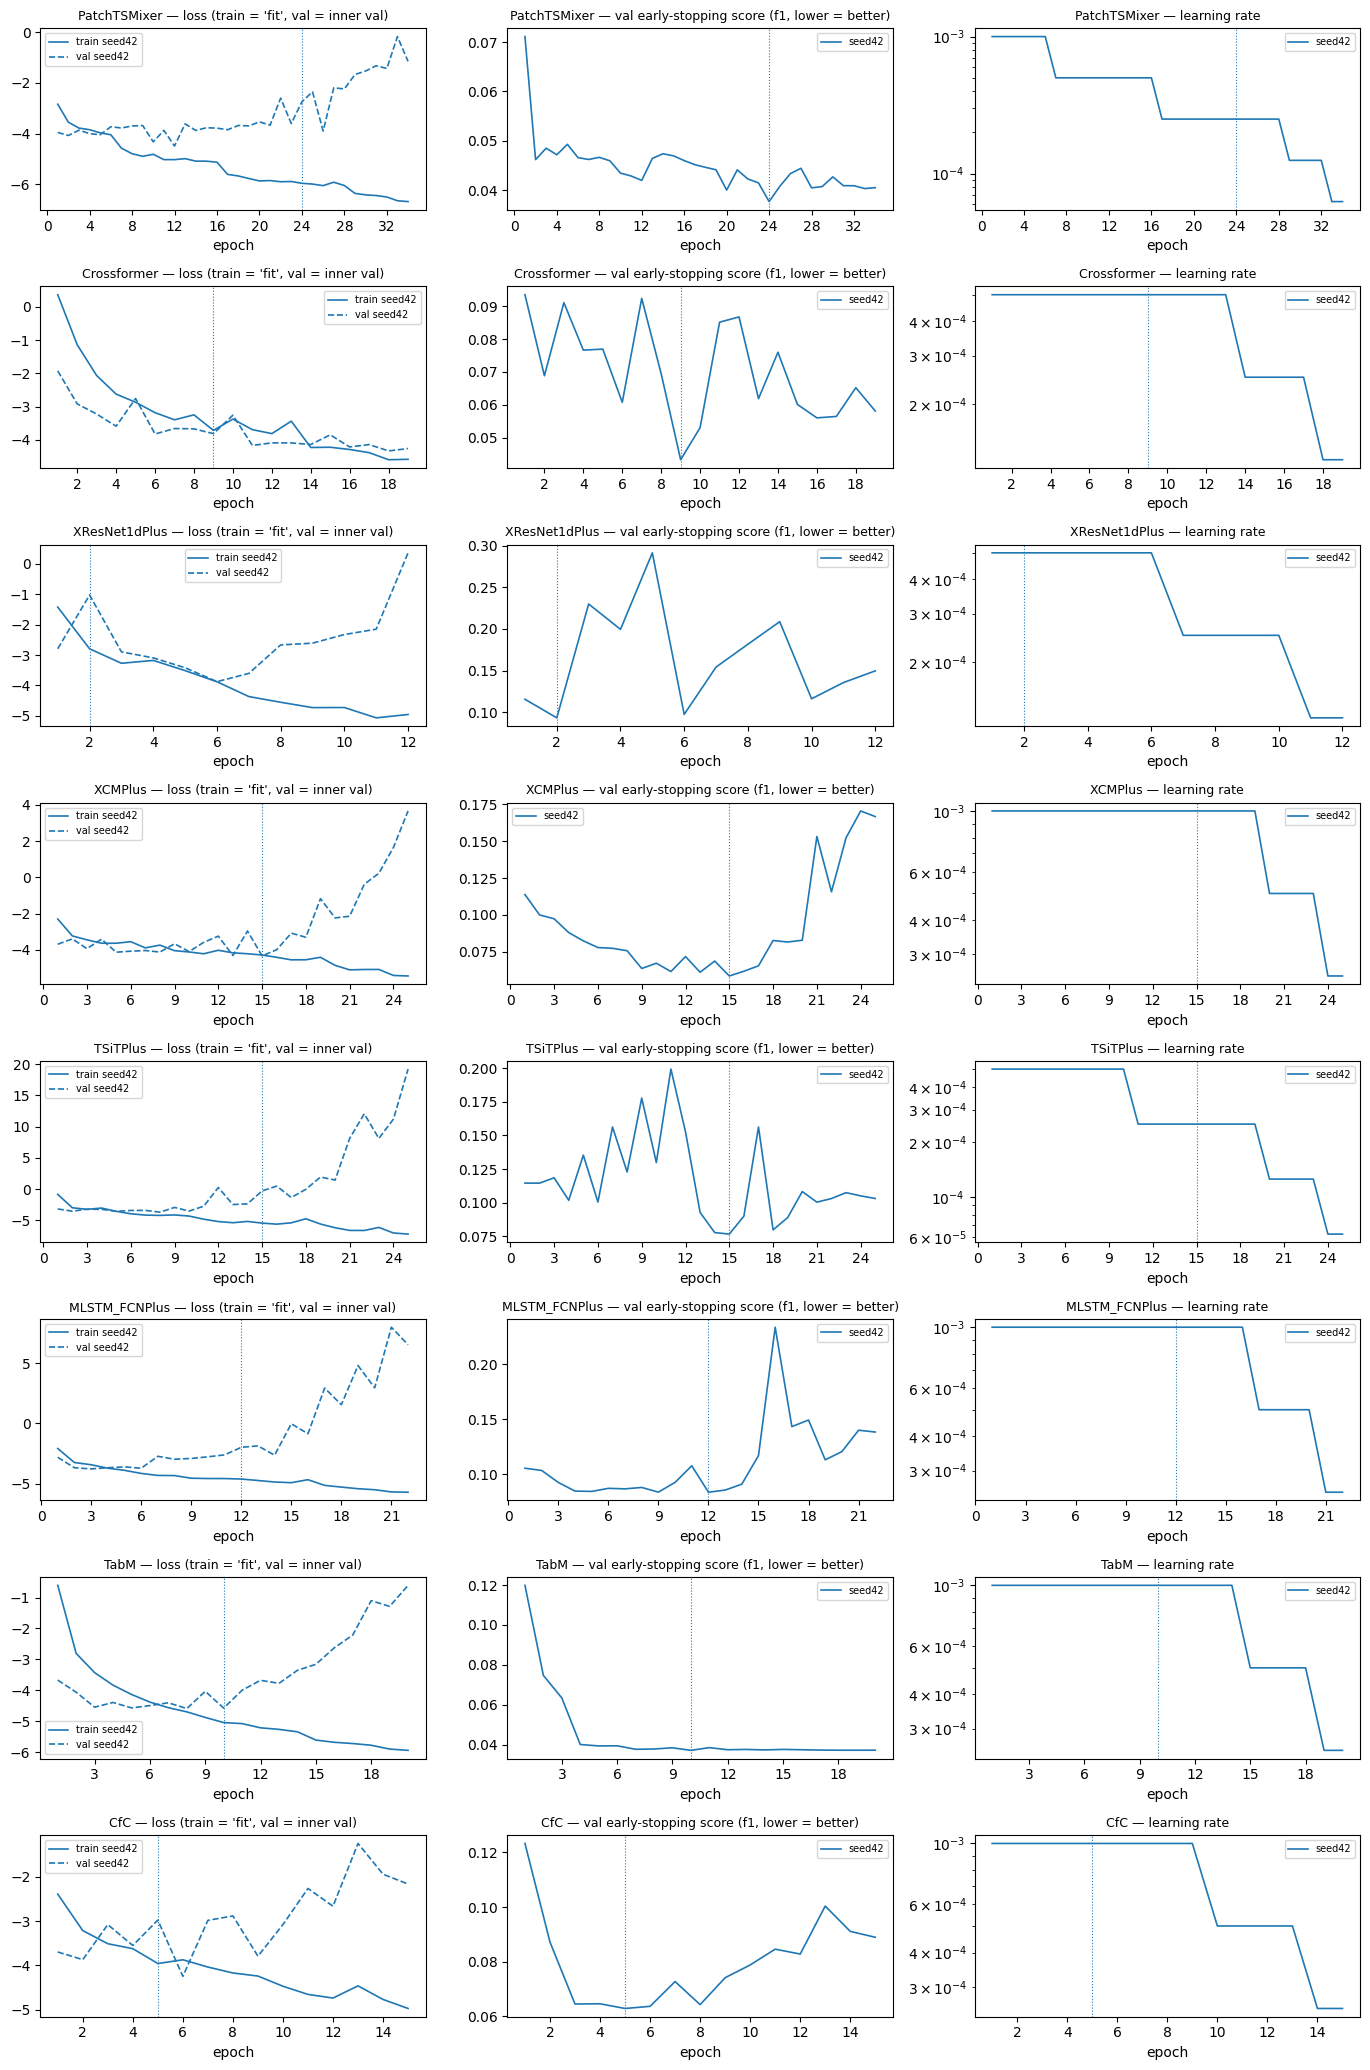

In [ ]:
# ==================== 7b. Training curves (edit the options below) ====================
CURVE_MODELS = None          # None = every network, or e.g. ["TabM", "CfC"]
CURVE_SEEDS = None           # None = every seed, or e.g. [42]
CURVE_PANELS = ["loss", "val_score", "lr"]   # any of: "loss" (train vs val), "val_score", "lr"

if "HISTORIES" not in globals() or not HISTORIES:
    hp = OUTPUT_DIR / "histories.json"
    HISTORIES = json.load(open(hp)) if hp.exists() else {}
models = [m for m in DL_MODELS if CURVE_MODELS is None or m in CURVE_MODELS]
models = [m for m in models if any(k.startswith(m + "_seed") for k in HISTORIES)]
if models:
    titles = {"loss": f"loss (train = '{FIT_SPLIT}', val = inner val)" if VAL_INNER else "loss (train vs val)",
              "val_score": f"val early-stopping score ({EARLY_STOP_METRIC}, lower = better)", "lr": "learning rate"}
    fig, ax = plt.subplots(len(models), len(CURVE_PANELS), figsize=(4.6 * len(CURVE_PANELS), 2.6 * len(models)),
                           squeeze=False)
    for r, m in enumerate(models):
        keys = [k for k in HISTORIES if k.startswith(m + "_seed") and (CURVE_SEEDS is None or int(k.rsplit("seed", 1)[1]) in CURVE_SEEDS)]
        for i, k in enumerate(sorted(keys)):
            h, col, lab = HISTORIES[k], f"C{i}", k.rsplit("_", 1)[1]
            ep = np.arange(1, len(h["loss"]) + 1)
            best = int(np.argmin(h["val_score"])) + 1
            for c, panel in enumerate(CURVE_PANELS):
                a = ax[r, c]
                if panel == "loss":
                    a.plot(ep, h["loss"], color=col, lw=1.2, label=f"train {lab}")
                    a.plot(ep, h["val_loss"], color=col, lw=1.2, ls="--", label=f"val {lab}")
                elif panel == "val_score":
                    a.plot(ep, h["val_score"], color=col, lw=1.2, label=lab)
                elif panel == "lr":
                    a.plot(ep, h["lr"], color=col, lw=1.2, label=lab); a.set_yscale("log")
                a.axvline(best, color=col, ls=":", lw=0.8)
        for c, panel in enumerate(CURVE_PANELS):
            ax[r, c].set_title(f"{m} — {titles[panel]}", fontsize=9); ax[r, c].set_xlabel("epoch")
            ax[r, c].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
            ax[r, c].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / "figures" / "training_curves.png", dpi=110); plt.show()
    with open(OUTPUT_DIR / "histories.json", "w") as f:
        json.dump(HISTORIES, f)
else:
    print("No training history (section 7 not run, and no histories.json).")

## 8. Baselines

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier, ExtraTreesRegressor


def baseline_run(label, fit_fn, predict_fn, refit=True):
    """Fit on FIT_SPLIT, tune thresholds on (inner) val, refit on the whole train block (val = 0), score."""
    t0 = time.time()
    m = fit_fn(FIT_SPLIT)
    pv = predict_fn(m, "val")
    tau = tune_thresholds(pv["prob"], DATA["val"]["pres"])
    if DO_REFIT and refit:
        m = fit_fn("train")
    train_time = time.time() - t0
    preds = {s: predict_fn(m, s) for s in EVAL_SPLITS}
    path = OUTPUT_DIR / "models" / f"{label}.joblib"
    try:
        joblib.dump(m, path); size_mb = path.stat().st_size / 2**20
    except Exception:
        size_mb = np.nan
    t1 = time.time()                                                   # batch-1 latency on 50 test windows
    for i in range(50):
        predict_fn(m, ("test", slice(i, i + 1)))
    lat = (time.time() - t1) / 50 * 1000
    record(label, "Baseline (FP32)", SEED, preds, tau, np.full(G, np.inf), train_time_s=train_time, size_mb_fp32=size_mb,
           latency_ms_b1=lat)
    print(f"  model file {size_mb:.1f} MB | batch-1 latency {lat:.1f} ms")
    return m


def _rows(split):
    """split name or (split, slice) -> (features, raw windows)."""
    if isinstance(split, tuple):
        s, sl = split
        return FEAT[s][sl], DATA[s]["X"][sl]
    return FEAT[split], DATA[split]["X"]


# ---- 1) ExtraTrees inside scikit-lego ZeroInflatedRegressor (classifier: present?  regressor: ppm when present) ----
if "ExtraTrees_ZIR" in BASELINES:
    from sklego.meta import ZeroInflatedRegressor
    cfg = BASELINE_CFG["ExtraTrees_ZIR"]
    print("== ExtraTrees_ZIR (scikit-lego ZeroInflatedRegressor, ExtraTrees hyper-parameters of Ansari et al. 2025)")

    def et_fit(split):
        y0 = np.where(DATA[split]["pres"] > 0.5, DATA[split]["y_ppm"], 0.0)
        return [ZeroInflatedRegressor(classifier=ExtraTreesClassifier(**cfg, n_jobs=-1, random_state=SEED),
                                      regressor=ExtraTreesRegressor(**cfg, n_jobs=-1, random_state=SEED)).fit(FEAT[split], y0[:, j])
                for j in range(G)]

    def et_predict(ms, split):
        F_, _ = _rows(split)
        return {"prob": np.stack([m.classifier_.predict_proba(F_)[:, 1] for m in ms], 1),
                "ppm_cond": np.stack([m.regressor_.predict(F_) for m in ms], 1)}

    try:
        baseline_run("ExtraTrees_ZIR", et_fit, et_predict)
    except Exception as e:
        print(f"  ⚠ {type(e).__name__}: {str(e)[:300]}")

# ---- 2) QUANT (aeon) hurdle: QUANTClassifier for presence + QUANTRegressor on the windows where the gas is present ----
if "QUANT_Hurdle" in BASELINES:
    cfg = dict(BASELINE_CFG["QUANT_Hurdle"])
    stride, n_est = cfg.pop("train_stride"), cfg.pop("n_estimators")
    print(f"== QUANT_Hurdle (aeon QUANTClassifier + QUANTRegressor, 1/{stride} of the training windows)")

    def to_aeon(X):
        return np.ascontiguousarray(X.transpose(0, 2, 1), dtype=np.float64)

    def quant_fit(split):
        from aeon.classification.interval_based import QUANTClassifier
        from aeon.regression.interval_based import QUANTRegressor
        d = DATA[split]
        Xa, P, Yp = to_aeon(d["X"][::stride]), d["pres"][::stride] > 0.5, d["y_ppm"][::stride]
        out = []
        for j in range(G):
            clf = QUANTClassifier(random_state=SEED, estimator=ExtraTreesClassifier(
                n_estimators=n_est, max_features=0.1, criterion="entropy", n_jobs=-1, random_state=SEED), **cfg).fit(Xa, P[:, j])
            reg = QUANTRegressor(random_state=SEED, estimator=ExtraTreesRegressor(
                n_estimators=n_est, max_features=0.1, n_jobs=-1, random_state=SEED), **cfg).fit(Xa[P[:, j]], Yp[P[:, j], j])
            out.append((clf, reg))
        return out

    def quant_predict(ms, split, batch=4096):
        _, X = _rows(split)
        prob, ppm = np.zeros((len(X), G)), np.zeros((len(X), G))
        for i in range(0, len(X), batch):
            Xa = to_aeon(X[i:i + batch])
            for j, (clf, reg) in enumerate(ms):
                pr = clf.predict_proba(Xa)
                prob[i:i + batch, j] = pr[:, list(clf.classes_).index(True)] if True in clf.classes_ else 0.0
                ppm[i:i + batch, j] = reg.predict(Xa)
        return {"prob": prob, "ppm_cond": ppm}

    try:
        baseline_run("QUANT_Hurdle", quant_fit, quant_predict)
    except Exception as e:
        print(f"  ⚠ {type(e).__name__}: {str(e)[:300]}")

# ---- 3) RealMLP (pytabkit) hurdle: classifier + regressor, best epoch chosen on the (inner) val block ----
if "RealMLP_Hurdle" in BASELINES:
    print("== RealMLP_Hurdle (pytabkit RealMLP_TD_Classifier + RealMLP_TD_Regressor)")
    try:
        import pytabkit                                                # pytabkit trains with Lightning: silence its banners
        for lg in ("lightning", "lightning.pytorch", "pytorch_lightning", "lightning.fabric"):
            logging.getLogger(lg).setLevel(logging.ERROR)
    except ImportError:
        pass

    def rmlp_fit(split):
        from pytabkit import RealMLP_TD_Classifier, RealMLP_TD_Regressor
        kw = dict(device="cuda" if torch.cuda.is_available() else "cpu", random_state=SEED, verbosity=0,
                  **BASELINE_CFG["RealMLP_Hurdle"])
        d, v = DATA[split], DATA["val"]
        out = []
        for j in range(G):
            P, Pv = (d["pres"][:, j] > 0.5).astype(int), (v["pres"][:, j] > 0.5).astype(int)
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                clf = RealMLP_TD_Classifier(**kw).fit(FEAT[split], P, X_val=FEAT["val"], y_val=Pv)
                reg = RealMLP_TD_Regressor(**kw).fit(FEAT[split][P == 1], d["y_ppm"][P == 1, j],
                                                     X_val=FEAT["val"][Pv == 1], y_val=v["y_ppm"][Pv == 1, j])
            out.append((clf, reg))
        return out

    def rmlp_predict(ms, split):
        F_, _ = _rows(split)
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            return {"prob": np.stack([c.predict_proba(F_)[:, 1] for c, _ in ms], 1),
                    "ppm_cond": np.stack([r.predict(F_) for _, r in ms], 1)}

    if VAL_INNER:
        print("  val = 0: RealMLP keeps the model trained on 'fit' (its best epoch is chosen on the inner val), no refit")
    try:
        baseline_run("RealMLP_Hurdle", rmlp_fit, rmlp_predict, refit=False)
    except Exception as e:
        print(f"  ⚠ {type(e).__name__}: {str(e)[:300]}")

== ExtraTrees_ZIR (scikit-lego ZeroInflatedRegressor, ExtraTrees hyper-parameters of Ansari et al. 2025)
  test: F1 CO 0.873 | F1 C2H4 0.771 | 4-class F1 0.705 | CO alarm prec 0.811 rec 0.920 | false alarms 1.7/h | RMSE CO 94.5 C2H4 4.34 ppm | τ = [0.27, 0.38]
  model file 20.7 MB | batch-1 latency 241.9 ms
== QUANT_Hurdle (aeon QUANTClassifier + QUANTRegressor, 1/4 of the training windows)
  test: F1 CO 0.914 | F1 C2H4 0.800 | 4-class F1 0.746 | CO alarm prec 0.887 rec 0.918 | false alarms 0.0/h | RMSE CO 83.4 C2H4 4.16 ppm | τ = [0.41, 0.34]
  model file 28.5 MB | batch-1 latency 480.8 ms
== RealMLP_Hurdle (pytabkit RealMLP_TD_Classifier + RealMLP_TD_Regressor)
  val = 0: RealMLP keeps the model trained on 'fit' (its best epoch is chosen on the inner val), no refit
  test: F1 CO 0.893 | F1 C2H4 0.802 | 4-class F1 0.748 | CO alarm prec 0.889 rec 0.892 | false alarms 0.9/h | RMSE CO 92.8 C2H4 4.06 ppm | τ = [0.41, 0.42]
  model file 4.6 MB | batch-1 latency 233.9 ms


## 9. Quantisation benchmark (ONNX Runtime, CPU)


In [ ]:
import onnx
import onnxruntime as ort
from onnx import numpy_helper, helper
from onnxruntime.quantization import quantize_dynamic, quantize_static, QuantType, QuantFormat, CalibrationDataReader
from onnxruntime.quantization.shape_inference import quant_pre_process
from onnxruntime.quantization.matmul_nbits_quantizer import MatMulNBitsQuantizer
from onnxconverter_common import float16

logging.disable(logging.WARNING)            # the ONNX Runtime quantisers log every node
ort.set_default_logger_severity(3)


@contextlib.contextmanager
def silence_fds():
    """Send C/C++ writes on file descriptors 1 and 2 to /dev/null. The TorchScript exporter prints the whole graph
    when it fails; in Jupyter that flood can fill the output pipe and block the kernel."""
    sys.stdout.flush(); sys.stderr.flush()
    saved, null = [os.dup(1), os.dup(2)], os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(null, 1); os.dup2(null, 2)
        yield
    finally:
        os.dup2(saved[0], 1); os.dup2(saved[1], 2)
        for fd in saved + [null]:
            os.close(fd)


# Exporter tried first (both are tried). PatchTSMixer / Crossformer only export with the torch.export-based exporter.
EXPORTER_ORDER = {"PatchTSMixer": ("dynamo", "torchscript"), "Crossformer": ("dynamo", "torchscript")}


@contextlib.contextmanager
def onnx_friendly_ops():
    """TabM concatenates its inputs with torch.column_stack, which has no ONNX export rule. For the 2-D tensors used
    here column_stack is exactly torch.cat(dim=1), so it is swapped in during export only."""
    orig = torch.column_stack
    torch.column_stack = lambda ts: torch.cat([t.flatten(1) for t in ts], 1)
    try:
        yield
    finally:
        torch.column_stack = orig


def ort_session(path, threads=None):
    so = ort.SessionOptions(); so.log_severity_level = 3
    if threads:
        so.intra_op_num_threads, so.inter_op_num_threads = threads, 1
    return ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])


def ort_predict(sess, X, batch=1024):
    name = sess.get_inputs()[0].name
    return np.concatenate([sess.run(None, {name: X[i:i + batch]})[0] for i in range(0, len(X), batch)])


def file_mb(path):
    p = Path(path)
    return (p.stat().st_size + sum(q.stat().st_size for q in p.parent.glob(p.name + ".data"))) / 2**20


def export_onnx(model, X_example, path, order=("torchscript", "dynamo")):
    """Try the exporters in `order` (TorchScript, torch.export / dynamo); keep the first that matches PyTorch."""
    model = model.cpu().eval()
    with torch.no_grad():
        ref = model(torch.from_numpy(X_example[:8])).numpy()
    errors = []
    for exporter in order:
        try:
            with onnx_friendly_ops(), silence_fds(), contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                if exporter == "torchscript":
                    torch.onnx.export(model, (torch.from_numpy(X_example[:1]),), str(path), input_names=["x"], output_names=["y"],
                                      dynamic_axes={"x": {0: "batch"}, "y": {0: "batch"}}, opset_version=17, dynamo=False)
                else:
                    prog = torch.onnx.export(model, (torch.from_numpy(X_example[:4]),), None, input_names=["x"], output_names=["y"],
                                             dynamic_shapes=({0: torch.export.Dim("batch", min=1, max=65536)},),
                                             opset_version=18, dynamo=True)
                    prog.save(str(path))
            m = onnx.load(str(path))
            del m.graph.value_info[:]                    # stale shape annotations make the quantisers fail
            onnx.save(m, str(path))
            out = ort_predict(ort_session(path), X_example[:8])
            if np.abs(out - ref).max() > 1e-3 * (1 + np.abs(ref).max()):
                raise RuntimeError(f"ONNX output differs from PyTorch by {np.abs(out - ref).max():.2e}")
            return exporter
        except Exception as e:
            errors.append(f"{exporter}: {type(e).__name__}: {str(e)[:150]}")
    raise RuntimeError(" | ".join(errors))


def gemm_to_matmul(model):
    """Rewrite Gemm(A, W, b) with a constant W as MatMul(A, W) + Add(b): the INT4 MatMulNBits quantiser only handles MatMul."""
    g = model.graph
    inits = {i.name: i for i in g.initializer}
    new_nodes, added, n_conv = [], set(), 0
    for node in g.node:
        at = {a.name: helper.get_attribute_value(a) for a in node.attribute}
        if (node.op_type == "Gemm" and len(node.input) >= 2 and node.input[1] in inits and at.get("transA", 0) == 0
                and at.get("alpha", 1.0) == 1.0 and at.get("beta", 1.0) == 1.0):
            wname = node.input[1] + "_mm"
            if wname not in added:
                Wt = numpy_helper.to_array(inits[node.input[1]])
                g.initializer.append(numpy_helper.from_array(np.ascontiguousarray(Wt.T if at.get("transB", 0) else Wt), wname))
                added.add(wname)
            has_bias = len(node.input) > 2 and node.input[2] != ""
            mm_out = node.output[0] + "_mm" if has_bias else node.output[0]
            new_nodes.append(helper.make_node("MatMul", [node.input[0], wname], [mm_out], name=node.name + "_mm"))
            if has_bias:
                new_nodes.append(helper.make_node("Add", [mm_out, node.input[2]], [node.output[0]], name=node.name + "_add"))
            n_conv += 1
        else:
            new_nodes.append(node)
    del g.node[:]
    g.node.extend(new_nodes)
    used = {i for nd in g.node for i in nd.input}
    keep = [i for i in g.initializer if i.name in used]
    del g.initializer[:]
    g.initializer.extend(keep)
    return model, n_conv


def preprocess_for_int8(fp32, out):
    try:
        quant_pre_process(str(fp32), str(out))
    except Exception:
        try:
            quant_pre_process(str(fp32), str(out), skip_symbolic_shape=True)
        except Exception:
            return fp32
    return out


class _Calib(CalibrationDataReader):
    def __init__(self, X, batch=16):
        self.it = iter([{"x": X[i:i + batch]} for i in range(0, len(X), batch)])

    def get_next(self):
        return next(self.it, None)


def make_level(level, fp32, base, X_calib):
    """Returns (path, note). Raises NotImplementedError when the level does not apply to this model."""
    if level == "fp32":
        return fp32, ""
    p = Path(f"{base}_{level}.onnx")
    if level == "fp16":
        onnx.save(float16.convert_float_to_float16(onnx.load(str(fp32)), keep_io_types=True), str(p))
        return p, "weights + activations FP16 (onnxconverter-common)"
    pre = preprocess_for_int8(fp32, Path(f"{base}_pre.onnx"))
    if level == "int8_dynamic":
        try:
            quantize_dynamic(str(pre), str(p), weight_type=QuantType.QInt8)
            return p, "INT8 weights, activations quantised on the fly"
        except Exception:                                   # e.g. CfC: Gemm shape inference -> retry on MatMul form
            mm, _ = gemm_to_matmul(onnx.load(str(fp32)))
            tmp = Path(f"{base}_mm.onnx"); onnx.save(mm, str(tmp))
            quantize_dynamic(str(preprocess_for_int8(tmp, Path(f"{base}_mmpre.onnx"))), str(p), weight_type=QuantType.QInt8)
            return p, "INT8 weights (after Gemm→MatMul)"
    if level == "int8_static":
        for per_channel in (True, False):     # per-channel first; ONNX Runtime rejects it for 3-D weights (TabM ensemble head)
            quantize_static(str(pre), str(p), _Calib(X_calib), quant_format=QuantFormat.QDQ, activation_type=QuantType.QInt8,
                            weight_type=QuantType.QInt8, per_channel=per_channel)
            try:
                ort_predict(ort_session(p), X_calib[:2])
                break
            except Exception:
                if not per_channel:
                    raise
        return p, (f"INT8 weights + activations (QDQ, {'per-channel' if per_channel else 'per-tensor'}, "
                   f"{len(X_calib)} calibration windows)")
    if level == "int4":
        mm, _ = gemm_to_matmul(onnx.load(str(fp32)))
        n_mm = sum(nd.op_type == "MatMul" for nd in mm.graph.node)
        inits = {i.name: int(np.prod(i.dims)) for i in mm.graph.initializer if i.data_type == onnx.TensorProto.FLOAT}
        mm_w = {nd.input[1] for nd in mm.graph.node if nd.op_type == "MatMul" and nd.input[1] in inits and
                len(next(i for i in mm.graph.initializer if i.name == nd.input[1]).dims) == 2}
        share = sum(inits[w] for w in mm_w) / max(sum(inits.values()), 1)
        q = MatMulNBitsQuantizer(mm, block_size=INT4_BLOCK, is_symmetric=True)
        q.process()
        q.model.save_model_to_file(str(p), use_external_data_format=False)
        n_q = sum(nd.op_type == "MatMulNBits" for nd in onnx.load(str(p)).graph.node)
        if n_q == 0:
            p.unlink(missing_ok=True)
            raise NotImplementedError("no MatMul with constant weights (convolution / recurrent weights stay FP32)")
        return p, (f"INT4 weight-only on {n_q}/{n_mm} MatMul = {share:.0%} of the weights (block {INT4_BLOCK}); rest FP32"
                   + (" — mostly FP32, little gain" if share < 0.5 else ""))
    raise ValueError(level)


PEAK_SCRIPT = r"""
import sys, numpy as np, onnxruntime as ort
def status(k):
    for line in open("/proc/self/status"):
        if line.startswith(k):
            return int(line.split()[1]) / 1024
path, shape = sys.argv[1], tuple(int(s) for s in sys.argv[2].split(","))
x = np.zeros((1,) + shape, np.float32)
try:
    open("/proc/self/clear_refs", "w").write("5")      # reset the peak (VmHWM) after the imports
except Exception:
    pass
before = status("VmRSS:")
so = ort.SessionOptions(); so.intra_op_num_threads = 1; so.inter_op_num_threads = 1; so.log_severity_level = 3
s = ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])
for _ in range(20):
    s.run(None, {s.get_inputs()[0].name: x})
print(status("VmHWM:") - before)
"""


def peak_rss_mb(path, shape):
    if not MEASURE_PEAK_RAM:
        return np.nan
    r = subprocess.run([sys.executable, "-c", PEAK_SCRIPT, str(path), ",".join(map(str, shape))],
                       capture_output=True, text=True, timeout=600)
    try:
        return float(r.stdout.strip().splitlines()[-1])
    except Exception:
        return np.nan


def latency_ms(path, X):
    s = ort_session(path, threads=1)
    name = s.get_inputs()[0].name
    for i in range(5):
        s.run(None, {name: X[i:i + 1]})
    ts = []
    for i in range(min(LATENCY_RUNS, len(X))):
        t0 = time.perf_counter(); s.run(None, {name: X[i:i + 1]}); ts.append(time.perf_counter() - t0)
    return float(np.median(ts) * 1000)


QRESULTS = []
QPREDS = {}       # (model key, level) -> test predictions, re-scored in 10c
for key, tr in TRAINED.items():
    name, model, tau, ucut = tr["name"], tr["model"], tr["tau"], tr["ucut"]
    X_test = model_input(name, "test")
    X_cal = model_input(name, "train")[np.random.default_rng(SEED).choice(len(DATA["train"]["X"]),
                                                                          min(CALIB_SAMPLES, len(DATA["train"]["X"])), replace=False)]
    base = OUTPUT_DIR / "onnx" / key
    fp32 = Path(f"{base}.onnx")
    print(f"== {key}")
    try:
        exporter = export_onnx(model, X_test, fp32, EXPORTER_ORDER.get(name, ("torchscript", "dynamo")))
    except Exception as e:
        print(f"  ⚠ ONNX export failed: {str(e)[:400]}")
        continue

    fp32 = preprocess_for_int8(fp32, Path(f"{base}_opt.onnx"))  ##

    ref = postprocess(ort_predict(ort_session(fp32), X_test))
    ref_hat = ref["prob"] >= tau
    n_params = sum(p.numel() for p in model.parameters())
    for level in QUANT_LEVELS:
        row = {"model": name, "key": key, "seed": tr["seed"], "level": level, "n_params": n_params, "exporter": exporter,
               "tau": tau, "ucut": ucut}
        try:
            path, note = make_level(level, fp32, base, X_cal)
            pred = postprocess(ort_predict(ort_session(path), X_test))
            QPREDS[(key, level)] = pred
            row.update(note=note, size_mb=file_mb(path), latency_ms_b1=latency_ms(path, X_test),
                       peak_rss_mb=peak_rss_mb(path, X_test.shape[1:]),
                       decision_agreement=float(np.mean((pred["prob"] >= tau) == ref_hat)),
                       mean_abs_dprob=float(np.mean(np.abs(pred["prob"] - ref["prob"]))))
            row.update(evaluate(pred, DATA["test"], tau, ucut))
            for lim, mb in ESP32_LIMITS_MB.items():
                row[f"fits {lim} ({mb:g} MB)"] = bool(row["size_mb"] <= mb)
            print(f"  {level:13s}: {row['size_mb']:8.2f} MB | latency {row['latency_ms_b1']:7.2f} ms | peak RSS "
                  f"{row['peak_rss_mb']:6.1f} MB | F1 CO {row['F1_CO']:.3f} C2H4 {row['F1_Ethylene']:.3f} | "
                  f"false alarms {row['false_alarms_per_h']:.1f}/h | agreement {row['decision_agreement']:.4f}")
        except NotImplementedError as e:
            row.update(note=f"n/a: {e}")
            print(f"  {level:13s}: n/a ({e})")
        except Exception as e:
            row.update(note=f"failed: {type(e).__name__}: {str(e)[:150]}")
            print(f"  {level:13s}: ⚠ {type(e).__name__}: {str(e)[:200]}")
        QRESULTS.append(row)
    for tmp in OUTPUT_DIR.joinpath("onnx").glob(f"{key}_*pre.onnx"):
        tmp.unlink(missing_ok=True)
    for tmp in OUTPUT_DIR.joinpath("onnx").glob(f"{key}_mm.onnx"):
        tmp.unlink(missing_ok=True)
QDF = pd.DataFrame(QRESULTS)
logging.disable(logging.NOTSET)

== PatchTSMixer_seed42
  fp32         :    10.35 MB | latency   16.59 ms | peak RSS   34.1 MB | F1 CO 0.873 C2H4 0.795 | false alarms 0.0/h | agreement 1.0000
  fp16         :     5.21 MB | latency   19.04 ms | peak RSS   36.4 MB | F1 CO 0.873 C2H4 0.795 | false alarms 0.0/h | agreement 0.9998
  int8_static  :     2.92 MB | latency   28.32 ms | peak RSS   29.5 MB | F1 CO 0.811 C2H4 0.642 | false alarms 1.3/h | agreement 0.9163
== Crossformer_seed42
  fp32         :     4.29 MB | latency    3.09 ms | peak RSS   19.3 MB | F1 CO 0.838 C2H4 0.749 | false alarms 0.4/h | agreement 1.0000
  fp16         :     2.17 MB | latency   12.00 ms | peak RSS   21.6 MB | F1 CO 0.838 C2H4 0.750 | false alarms 0.4/h | agreement 0.9999
  int8_static  :     1.30 MB | latency    7.17 ms | peak RSS   18.7 MB | F1 CO 0.838 C2H4 0.680 | false alarms 1.7/h | agreement 0.9511
== XResNet1dPlus_seed42
  fp32         :    60.93 MB | latency    8.89 ms | peak RSS   79.3 MB | F1 CO 0.567 C2H4 0.505 | false alarms 2.2/

## 10. Results


In [ ]:
# ==================== 10a. Re-score every test prediction with the current `evaluate` ====================
# The metrics are recomputed from the stored predictions (PREDS) and decision thresholds (THRESH), so changing
# `evaluate` (section 5) and re-running from here updates every table WITHOUT retraining. If the kernel was restarted,
# the predictions are read back from test_predictions.npz + thresholds.json (DER-interval metrics are then missing).

OUTPUT_DIR = Path(COLAB_OUTPUT_DIR) / RUN_NAME

def load_preds_from_disk():
    z = np.load(OUTPUT_DIR / "test_predictions.npz")
    preds = {}
    for k in z.files:
        if "__" in k:
            key, f = k.split("__", 1)
            preds.setdefault(key, {})[f] = z[k].astype(np.float64)
    with open(OUTPUT_DIR / "thresholds.json") as f:
        return preds, json.load(f)


if "PREDS" in globals() and len(PREDS):
    SRC_PREDS, SRC_THRESH = PREDS, THRESH
else:
    SRC_PREDS, SRC_THRESH = load_preds_from_disk()
    print("PREDS not in memory: using", OUTPUT_DIR / "test_predictions.npz")

FAMILY = {r["model"]: r["family"] for r in RESULTS} if "RESULTS" in globals() else {}
EXTRA = ["n_params", "train_time_s", "best_epoch", "size_mb_fp32", "latency_ms_b1"]
extra = (pd.DataFrame(RESULTS).query("split == 'test'").set_index(["model", "seed"])[[c for c in EXTRA if c in pd.DataFrame(RESULTS)]]
         if "RESULTS" in globals() and len(RESULTS) else pd.DataFrame())
rows = []
for key, pred in SRC_PREDS.items():
    model, seed = key.rsplit("_seed", 1)
    assert len(pred["prob"]) == len(DATA["test"]["y"]), f"{key}: predictions do not match the current test block"
    th = SRC_THRESH[key]
    row = {"model": model, "seed": int(seed),
           "family": FAMILY.get(model, "Network (hurdle + DER)" if model in DL_MODELS else "Baseline (FP32)")}
    row.update(evaluate(pred, DATA["test"], np.array(th["tau"], float), np.array(th["uct_cut_ppm"], float)))
    rows.append(row)
RES_TEST = pd.DataFrame(rows).set_index(["model", "seed"])
if len(extra):
    RES_TEST = RES_TEST.join(extra)
RES_TEST = RES_TEST.reset_index()
RES_TEST.to_csv(OUTPUT_DIR / "results_test_all_seeds.csv", index=False)

# Full summary (all metrics, mean over seeds) — used by the figures in section 11
num_cols = [c for c in RES_TEST.columns if c not in ("model", "family", "seed") and pd.api.types.is_numeric_dtype(RES_TEST[c])]
SUMMARY = RES_TEST.groupby(["model", "family"])[num_cols].mean()
std = RES_TEST.groupby("model")[["F1_CO", "F1_Ethylene", "F1_macro_4class"]].std().add_suffix("_std")
SUMMARY = SUMMARY.join(std, on="model").sort_values("F1_macro_4class", ascending=False)
SUMMARY.to_csv(OUTPUT_DIR / "summary_test.csv")
print(f"Re-scored {len(RES_TEST)} runs ({RES_TEST.model.nunique()} models) on the test block "
      f"({100 * SEGMENTS['test'][0] / N_FULL:.0f}–{100 * SEGMENTS['test'][1] / N_FULL:.0f}%). Available metric columns:")
print(", ".join(num_cols))

V7_REF = pd.DataFrame({"model": ["QUANT", "Ridge", "Torch_CfC", "Torch_ConvTranPlus"],
                       "F1_presence_macro (4 classes)": [0.639, 0.684, 0.719, 0.601],
                       "CO_alarm_prec": [0.735, 0.716, 0.791, 0.748], "CO_alarm_rec": [0.967, 0.941, 0.917, 0.938],
                       "false_alarms_per_h": [19.5, 62.0, 4.8, 6.2], "RMSE_CO": [82.0, 90.2, 98.8, 98.1],
                       "RMSE_Ethylene": [3.59, 3.24, 3.62, 3.99]}).set_index("model")

Re-scored 11 runs (11 models) on the test block (60–80%). Available metric columns:
F1_CO, Prec_CO, Rec_CO, AUROC_CO, F1_steady_CO, F1_Ethylene, Prec_Ethylene, Rec_Ethylene, AUROC_Ethylene, F1_steady_Ethylene, F1_macro_4class, Acc_4class, F1_AIR, AUROC_AIR, F1_C2H4only, AUROC_C2H4only, F1_COonly, AUROC_COonly, F1_MIX, AUROC_MIX, AUROC_macro_4class, RMSE_CO, MAE_CO, RMSE_present_CO, PICP90_CO, PIwidth90_CO, UctErrSpearman_CO, RMSE_Ethylene, MAE_Ethylene, RMSE_present_Ethylene, PICP90_Ethylene, PIwidth90_Ethylene, UctErrSpearman_Ethylene, CO_alarm_prec, CO_alarm_rec, co_events, co_alarm_already_on, co_detect_rate, co_latency_med_s, false_alarms_per_h, CO_warn_share, CO_alarm_prec_confident, n_params, train_time_s, best_epoch, size_mb_fp32, latency_ms_b1


### 10b. Main results table

In [ ]:
# ==================== 10b. Main results table (edit the lists below) ====================
MAIN_COLS = ["F1_AIR", "F1_CO", "F1_Ethylene", "F1_MIX", "F1_macro_4class",
             "AUROC_CO", "AUROC_Ethylene", "AUROC_AIR", "AUROC_MIX", "RMSE_CO", "RMSE_Ethylene"]
# other columns you can add (printed by 10a), e.g. "F1_COonly", "F1_C2H4only", "AUROC_macro_4class", "Prec_CO", "Rec_CO",
# "CO_alarm_prec", "CO_alarm_rec", "false_alarms_per_h", "co_latency_med_s", "PICP90_CO", "n_params", "latency_ms_b1"
SORT_BY, ASCENDING = "F1_macro_4class", False
SHOW_STD = True            # with N_SEEDS > 1: "mean ± std" over seeds
SHOW_FAMILY = True
DECIMALS = 3

cols = [c for c in MAIN_COLS if c in RES_TEST.columns]
missing = [c for c in MAIN_COLS if c not in RES_TEST.columns]
if missing:
    print("⚠ not available (check the names printed in 10a):", missing)
g = RES_TEST.groupby(["model", "family"] if SHOW_FAMILY else ["model"])
mean, sd, n = g[cols].mean(), g[cols].std(), g.size()
MAIN_TABLE = mean.sort_values(SORT_BY, ascending=ASCENDING) if SORT_BY in mean else mean
MAIN_TABLE.round(DECIMALS).to_csv(OUTPUT_DIR / "main_table_test.csv")
print(f"=== Test block, mean over {int(n.max())} seed(s) per network (baselines: 1 run) ===")
if SHOW_STD and n.max() > 1:
    fmt = lambda m, s: f"{m:.{DECIMALS}f}" if not np.isfinite(s) else f"{m:.{DECIMALS}f} ± {s:.{DECIMALS}f}"
    display(pd.DataFrame({c: [fmt(m, s) for m, s in zip(MAIN_TABLE[c], sd.loc[MAIN_TABLE.index, c])] for c in cols},
                         index=MAIN_TABLE.index))
else:
    display(MAIN_TABLE.round(DECIMALS))
# print("v7 reference (same split, regression + 50 ppm threshold):")
# display(V7_REF)

=== Test block, mean over 1 seed(s) per network (baselines: 1 run) ===


,,F1_AIR,F1_CO,F1_Ethylene,F1_MIX,F1_macro_4class,AUROC_CO,AUROC_Ethylene,AUROC_AIR,AUROC_MIX,RMSE_CO,RMSE_Ethylene
model,family,,,,,,,,,,,
TabM,Network (hurdle + DER),0.856,0.881,0.837,0.698,0.810,0.955,0.935,0.933,0.903,94.831,3.599
XCMPlus,Network (hurdle + DER),0.807,0.831,0.782,0.630,0.751,0.922,0.914,0.881,0.973,110.555,4.192
PatchTSMixer,Network (hurdle + DER),0.847,0.873,0.795,0.530,0.748,0.941,0.927,0.925,0.955,99.734,4.205
RealMLP_Hurdle,Baseline (FP32),0.866,0.893,0.802,0.474,0.748,0.969,0.942,0.952,0.960,92.811,4.063
QUANT_Hurdle,Baseline (FP32),0.877,0.914,0.800,0.446,0.746,0.968,0.948,0.958,0.963,83.387,4.161
MLSTM_FCNPlus,Network (hurdle + DER),0.804,0.830,0.759,0.588,0.732,0.928,0.915,0.885,0.970,113.360,4.208
ExtraTrees_ZIR,Baseline (FP32),0.848,0.873,0.771,0.373,0.705,0.956,0.928,0.940,0.965,94.482,4.341
Crossformer,Network (hurdle + DER),0.795,0.838,0.749,0.474,0.697,0.917,0.889,0.888,0.910,109.484,4.825
CfC,Network (hurdle + DER),0.757,0.790,0.661,0.377,0.622,0.878,0.810,0.800,0.984,116.987,4.702


### 10c. Quantisation table

In [ ]:
# ==================== 10c. Quantisation table (edit the lists below) ====================

# QUANT_COLS = ["note", "size_mb", "latency_ms_b1", "peak_rss_mb", "decision_agreement",
#               "F1_CO", "F1_Ethylene", "F1_macro_4class", "AUROC_CO", "AUROC_Ethylene", "RMSE_CO", "RMSE_Ethylene"]

QUANT_COLS = ["size_mb", "latency_ms_b1", "peak_rss_mb", "F1_CO", "F1_Ethylene", "F1_macro_4class", "AUROC_CO", "AUROC_Ethylene", "RMSE_CO", "RMSE_Ethylene"]

SHOW_ESP32_FIT = True      # add the "fits ESP32 ..." columns
DELTA_COLS = ["F1_CO", "F1_Ethylene", "F1_macro_4class", "AUROC_CO", "RMSE_CO", "false_alarms_per_h"]   # change vs FP32
DECIMALS_Q = 3

if "QDF" in globals() and len(QDF):
    Q = QDF.copy()
    if "QPREDS" in globals() and len(QPREDS):          # re-score with the current `evaluate` (new metrics included)
        new = []
        for _, r in Q.iterrows():
            p = QPREDS.get((r.get("key"), r["level"]))
            new.append(evaluate(p, DATA["test"], r["tau"], r["ucut"]) if p is not None else {})
        Q = Q.drop(columns=[c for c in pd.DataFrame(new).columns if c in Q.columns]).join(pd.DataFrame(new, index=Q.index))
    elif any(c not in Q.columns for c in QUANT_COLS):
        print("⚠ QPREDS not available (quantisation run before this version): new metric columns stay empty")
    fit_cols = [c for c in Q.columns if c.startswith("fits ")] if SHOW_ESP32_FIT else []
    show = [c for c in QUANT_COLS if c in Q.columns] + fit_cols
    QUANT_TABLE = Q.set_index(["model", "level"])[show]
    QUANT_TABLE.to_csv(OUTPUT_DIR / "quantization_table.csv")
    print("=== Quantisation, test block, decision thresholds of the FP32 model ===")
    display(QUANT_TABLE.round(DECIMALS_Q))

    base = Q[Q.level == "fp32"].set_index("model")
    d = []
    for _, r in Q.iterrows():
        if r.level == "fp32" or r.model not in base.index or not np.isfinite(r.get("size_mb", np.nan)):
            continue
        b = base.loc[r.model]
        row = {"model": r.model, "level": r.level, "size_x_smaller": b.size_mb / r.size_mb,
               "speedup_x": b.latency_ms_b1 / r.latency_ms_b1}
        row.update({f"d_{c}": r[c] - b[c] for c in DELTA_COLS if c in Q.columns})
        d.append(row)
    QDELTA = pd.DataFrame(d).set_index(["model", "level"]) if d else pd.DataFrame()
    QDELTA.to_csv(OUTPUT_DIR / "quantization_delta.csv")
    print("=== Change vs FP32 (size_x_smaller / speedup_x: how many times smaller / faster; d_* = level − FP32) ===")
    display(QDELTA.round(DECIMALS_Q))
else:
    print("No quantisation results (section 9 not run).")

=== Quantisation, test block, decision thresholds of the FP32 model ===


size_mb  latency_ms_b1  peak_rss_mb  F1_CO  F1_Ethylene  F1_macro_4class  AUROC_CO  AUROC_Ethylene  RMSE_CO  RMSE_Ethylene  fits ESP32 flash (4 MB)  fits ESP32-S3 PSRAM (8 MB)  \
model         level                                                                                                                                                                                          
PatchTSMixer  fp32          10.352         16.591       34.133  0.873        0.795            0.748     0.941           0.927   99.734          4.205                    False                       False   
              fp16           5.206         19.039       36.395  0.873        0.795            0.748     0.941           0.927   99.779          4.209                    False                        True   
              int8_static    2.921         28.322       29.535  0.811        0.642            0.631     0.904           0.866  120.688          5.992                     True                        True   
Crossformer   fp32           4.295          3.085       19.328  0.838        0.749            0.697     0.917           0.889  109.484          4.825                    False                        True   
              fp16           2.169         12.003       21.562  0.838        0.750            0.697     0.917           0.889  109.485          4.823                     True                        True   
              int8_static    1.295          7.170       18.730  0.838        0.680            0.634     0.921           0.841  107.556          5.218                     True                        True   
XResNet1dPlus fp32          60.930          8.885       79.266  0.567        0.505            0.282     0.759           0.653  169.131          7.404                    False                       False   
              fp16          30.492          8.583      122.625  0.567        0.505            0.282     0.759           0.653  169.146          7.405                    False                       False   
              int8_static   15.783          5.050       47.230  0.555        0.500            0.292     0.758           0.650  165.815          7.090                    False                       False   
XCMPlus       fp32           4.041          1.966       18.996  0.831        0.782            0.751     0.922           0.914  110.555          4.192                    False                        True   
              fp16           2.035          1.941       22.762  0.831        0.782            0.751     0.922           0.914  110.554          4.192                     True                        True   
              int8_static    1.062          1.578       15.816  0.832        0.781            0.751     0.923           0.913  110.363          4.201                     True                        True   
TSiTPlus      fp32           9.246          5.061       23.957  0.845        0.657            0.595     0.937           0.855  109.089          5.365                    False                       False   
              fp16           4.670          4.893       29.652  0.845        0.658            0.595     0.937           0.855  109.091          5.356                    False                        True   
              int8_static    2.654         15.501       20.875  0.845        0.665            0.603     0.936           0.851  108.503          5.320                     True                        True   
MLSTM_FCNPlus fp32           5.616          3.405       20.145  0.830        0.759            0.732     0.928           0.915  113.360          4.208                    False                        True   
              fp16           2.815          3.412       22.824  0.830        0.759            0.733     0.928           0.915  113.298          4.208                     True                        True   
              int8_static    4.804          3.517       20.434  0.830        0.759            0.731     0.928    

=== Change vs FP32 (size_x_smaller / speedup_x: how many times smaller / faster; d_* = level − FP32) ===


size_x_smaller  speedup_x  d_F1_CO  d_F1_Ethylene  d_F1_macro_4class  d_AUROC_CO  d_RMSE_CO  d_false_alarms_per_h
model         level                                                                                                                         
PatchTSMixer  fp16                  1.988      0.871   -0.000          0.000             -0.000       0.000      0.045                 0.000
              int8_static           3.544      0.586   -0.063         -0.153             -0.117      -0.037     20.954                 1.302
Crossformer   fp16                  1.980      0.257    0.000          0.000              0.000       0.000      0.002                 0.000
              int8_static           3.315      0.430   -0.000         -0.069             -0.062       0.004     -1.928                 1.302
XResNet1dPlus fp16                  1.998      1.035    0.000         -0.000             -0.000      -0.000      0.015                 0.000
              int8_static           3.861      1.759   -0.012         -0.005              0.009      -0.001     -3.316                 0.434
XCMPlus       fp16                  1.986      1.013    0.000          0.000              0.000      -0.000     -0.001                 0.000
              int8_static           3.804      1.246    0.001         -0.001              0.000       0.001     -0.191                 0.000
TSiTPlus      fp16                  1.980      1.034    0.000          0.001              0.001       0.000      0.002                 0.000
              int8_static           3.484      0.326    0.000          0.008              0.009      -0.001     -0.586                 0.000
MLSTM_FCNPlus fp16                  1.995      0.998    0.000          0.000              0.000       0.000     -0.062                 0.000
              int8_static           1.169      0.968   -0.000          0.000             -0.001      -0.001      0.353                 0.000
TabM          fp16                  1.999      1.006    0.000          0.000              0.000      -0.000      0.000                 0.000
              int8_static           3.971      1.274   -0.000         -0.000              0.000      -0.000      0.240                 0.000
CfC           fp16                  1.241      0.770    0.000          0.000              0.000       0.000     -0.004                 0.000
              int8_static           0.308      0.214    0.001         -0.001             -0.001       0.002      0.809                 0.000

## 11. Figures


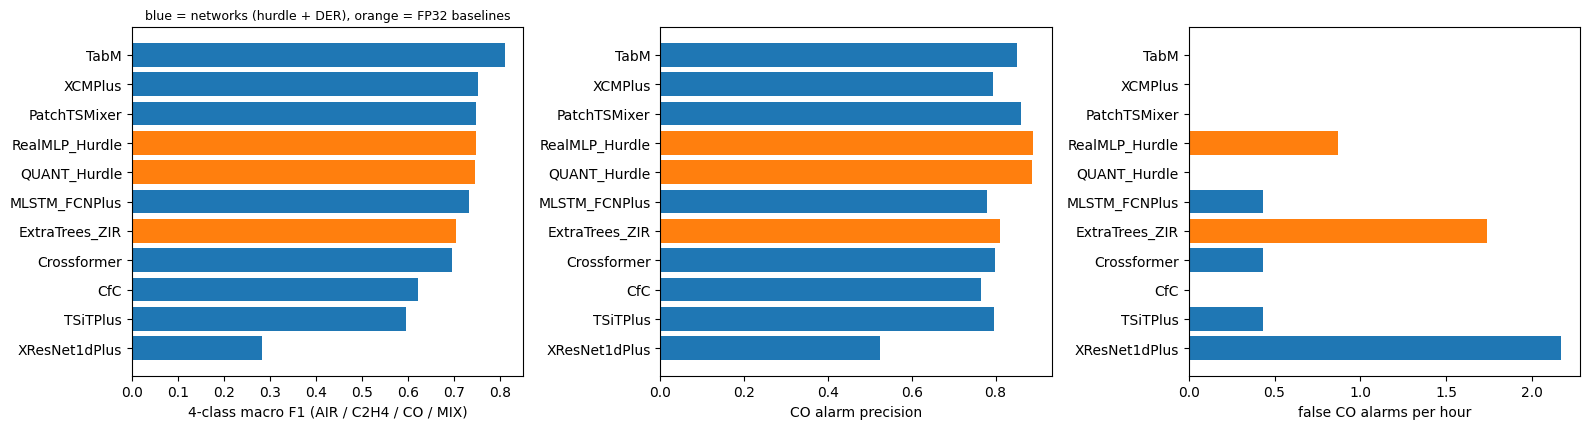

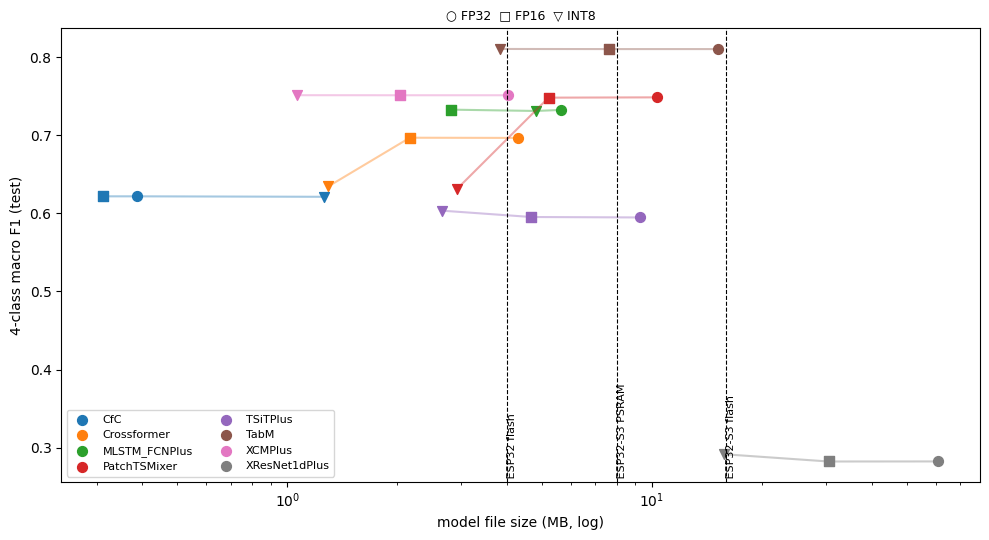

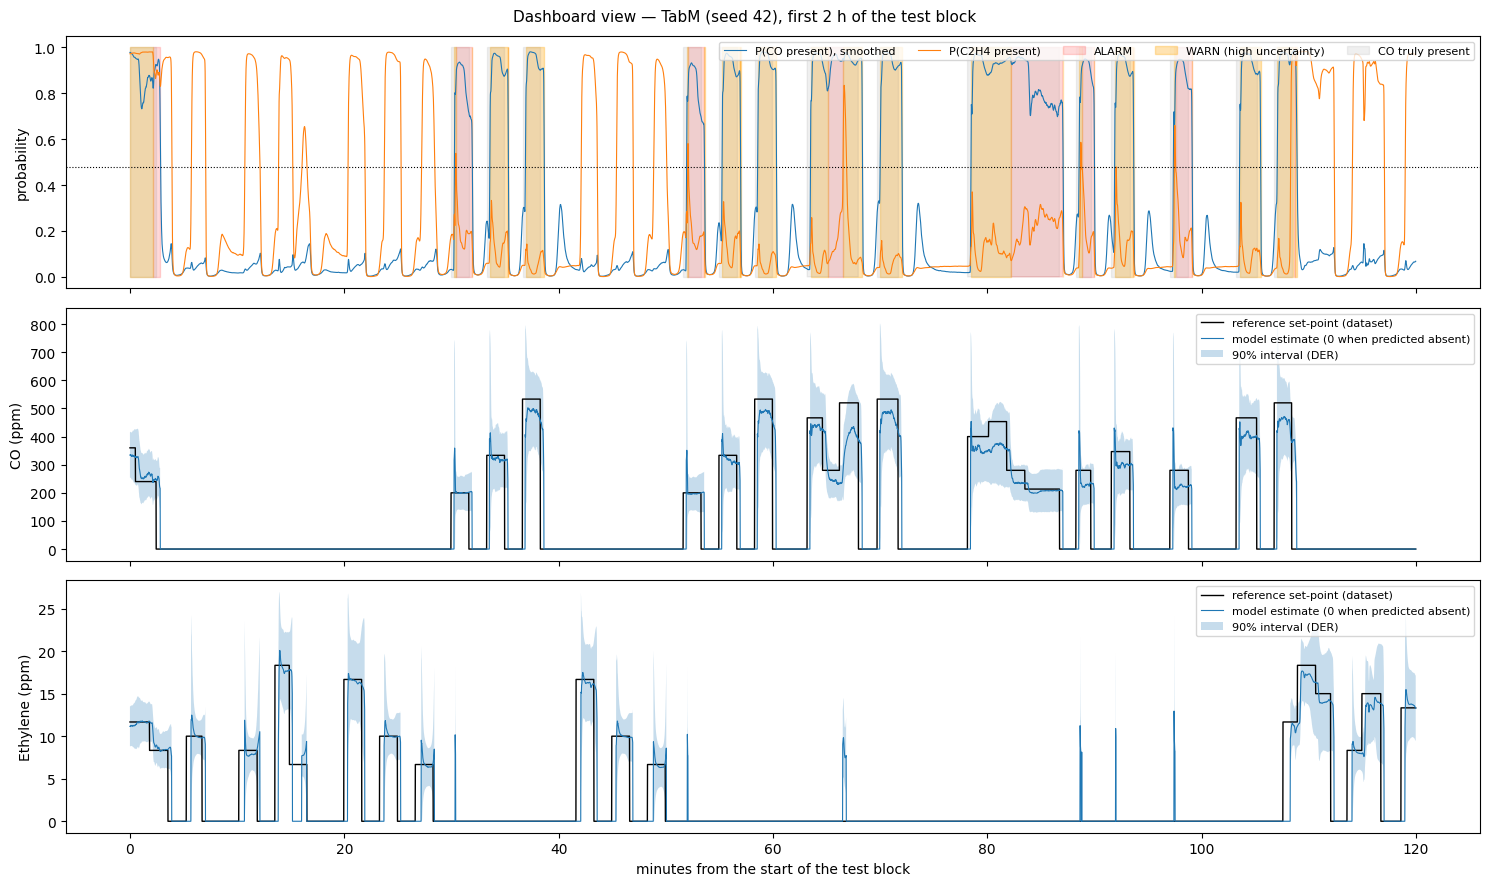

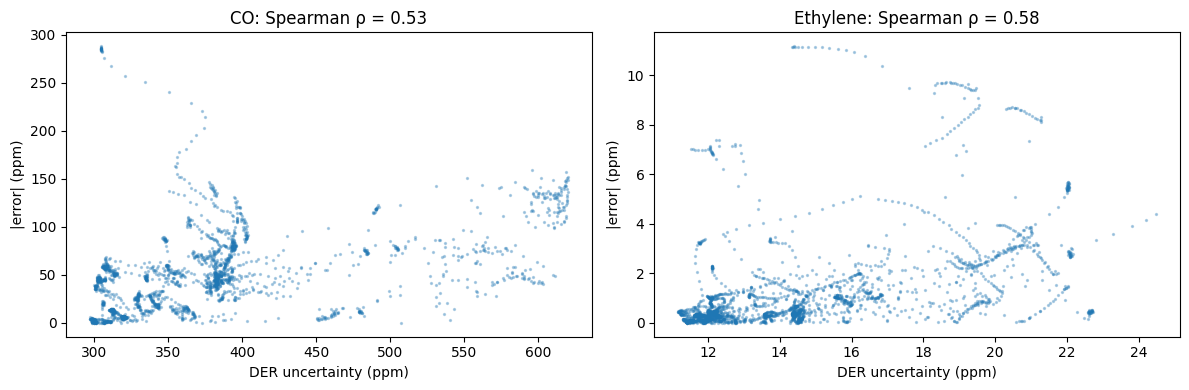

In [ ]:
FAMILY_COLOR = {"Network (hurdle + DER)": "tab:blue", "Baseline (FP32)": "tab:orange"}
S = SUMMARY.reset_index()

# 1) Detection quality and false alarms per model
fig, ax = plt.subplots(1, 3, figsize=(16, max(3.5, 0.4 * len(S))))
for a, col, lab in zip(ax, ["F1_macro_4class", "CO_alarm_prec", "false_alarms_per_h"],
                       ["4-class macro F1 (AIR / C2H4 / CO / MIX)", "CO alarm precision", "false CO alarms per hour"]):
    a.barh(S.model, S[col], color=[FAMILY_COLOR.get(f, "gray") for f in S.family])
    a.set_xlabel(lab); a.invert_yaxis()
ax[0].set_title("blue = networks (hurdle + DER), orange = FP32 baselines", fontsize=9)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "figures" / "test_by_model.png", dpi=120); plt.show()

# 2) Size vs quality for every quantisation level, with the ESP32 memory limits
if len(QDF) and "size_mb" in QDF:
    q = QDF.dropna(subset=["size_mb"])
    fig, ax = plt.subplots(figsize=(10, 5.5))
    markers = {"fp32": "o", "fp16": "s", "int8_dynamic": "^", "int8_static": "v", "int4": "D"}
    for i, (m, g) in enumerate(q.groupby("model")):
        g = g.sort_values("size_mb")
        ax.plot(g.size_mb, g.F1_macro_4class, "-", color=f"C{i}", alpha=0.4)
        for _, r in g.iterrows():
            ax.scatter(r.size_mb, r.F1_macro_4class, color=f"C{i}", marker=markers.get(r.level, "o"), s=50,
                       label=m if r.level == "fp32" else None)
    for lim, mb in ESP32_LIMITS_MB.items():
        ax.axvline(mb, color="k", ls="--", lw=0.8); ax.text(mb, ax.get_ylim()[0], f" {lim}", rotation=90, va="bottom", fontsize=8)
    ax.set_xscale("log"); ax.set_xlabel("model file size (MB, log)"); ax.set_ylabel("4-class macro F1 (test)")

    # ax.set_title("○ FP32  □ FP16  △ INT8 dynamic  ▽ INT8 static  ◇ INT4", fontsize=9)

    ax.set_title("○ FP32  □ FP16  ▽ INT8", fontsize=9)

    ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.savefig(OUTPUT_DIR / "figures" / "size_vs_f1.png", dpi=120); plt.show()

# 3) Dashboard view of the best network on the test block: probability, ALARM / WARN, ppm with the 90% interval
nets = S[S.family.str.startswith("Network")]
if len(nets):
    best = nets.iloc[0].model
    key = f"{best}_seed{SEED}"
    pr, th = PREDS[key], THRESH[key]
    tau, ucut = np.array(th["tau"]), np.array(th["uct_cut_ppm"])
    d = DATA["test"]
    span = slice(0, min(len(d["end_idx"]), int(2 * 3600 * RESAMPLE_HZ)))
    t = (d["end_idx"][span] - d["end_idx"][0]) / RESAMPLE_HZ / 60
    ps = smooth_causal(pr["prob"], ALARM_SMOOTH_S)[span]
    fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
    alarm = ps[:, 0] >= tau[0]
    warn = alarm & (pr["uct_ppm"][span, 0] > ucut[0])
    ax[0].plot(t, ps[:, 0], lw=0.8, label="P(CO present), smoothed"); ax[0].plot(t, ps[:, 1], lw=0.8, label="P(C2H4 present)")
    ax[0].axhline(tau[0], color="k", ls=":", lw=0.8)
    ax[0].fill_between(t, 0, 1, where=alarm & ~warn, color="red", alpha=0.15, step="mid", label="ALARM")
    ax[0].fill_between(t, 0, 1, where=warn, color="orange", alpha=0.3, step="mid", label="WARN (high uncertainty)")
    ax[0].fill_between(t, 0, 1, where=d["pres"][span, 0] > 0.5, color="gray", alpha=0.12, step="mid", label="CO truly present")
    ax[0].legend(fontsize=8, ncol=5, loc="upper right"); ax[0].set_ylabel("probability")
    for j, g in enumerate(GAS_NAMES):
        hat = pr["prob"][span, j] >= tau[j]
        ppm = np.where(hat, np.clip(pr["ppm_cond"][span, j], 0, None), 0)
        half = scipy.stats.t.ppf(T_Q, pr["df_t"][span, j]) * pr["scale_ppm"][span, j]
        ax[j + 1].plot(t, d["y_ppm"][span, j], "k", lw=1, label="reference set-point (dataset)")
        ax[j + 1].plot(t, ppm, lw=0.8, label="model estimate (0 when predicted absent)")
        ax[j + 1].fill_between(t, np.where(hat, np.clip(ppm - half, 0, None), np.nan), np.where(hat, ppm + half, np.nan), alpha=0.25,
                               label="90% interval (DER)")
        ax[j + 1].set_ylabel(f"{g} (ppm)"); ax[j + 1].legend(fontsize=8, loc="upper right")
    ax[-1].set_xlabel("minutes from the start of the test block")
    fig.suptitle(f"Dashboard view — {best} (seed {SEED}), first 2 h of the test block", fontsize=11)
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / "figures" / "dashboard_demo.png", dpi=120); plt.show()

    # 4) Is the DER uncertainty informative? |error| vs predicted uncertainty on windows with the gas present
    fig, ax = plt.subplots(1, G, figsize=(12, 4))
    for j, g in enumerate(GAS_NAMES):
        m = d["pres"][:, j] > 0.5
        err = np.abs(d["y_ppm"][m, j] - pr["ppm_cond"][m, j])
        ax[j].scatter(pr["uct_ppm"][m, j], err, s=2, alpha=0.3)
        ax[j].set_xlabel("DER uncertainty (ppm)"); ax[j].set_ylabel("|error| (ppm)")
        rho = scipy.stats.spearmanr(pr["uct_ppm"][m, j], err).statistic if m.sum() > 10 else np.nan
        ax[j].set_title(f"{g}: Spearman ρ = {rho:.2f}")
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / "figures" / "uncertainty_vs_error.png", dpi=120); plt.show()

# Training curves: see section 7b


## 11a. Top 4 Results & Figures

In [ ]:
# ==================== Top-N models: FP32 / FP16 / INT8 summary (edit the lists below) ====================
TOP_N = 4
SORT_BY, ASCENDING = "F1_macro_4class", False      # ranking on the FP32 test results (RES_TEST, mean over seeds)
ONLY_NETWORKS = False       # True: rank only the quantised networks (the baselines have FP32 only)
REQUIRE_QUANT = True        # True: skip models without results for every level in LEVELS (baselines, failed exports)
                            #       and take the next ones in the ranking
LEVELS = ["fp32", "fp16", "int8_static"]           # quantisation levels shown for each network
LEVEL_LABELS = {"fp32": "FP32", "fp16": "FP16", "int8_static": "INT8"}

# SUMMARY_COLS = ["size_mb_fp32", "latency_ms_b1", "F1_CO", "F1_Ethylene", "F1_AIR", "F1_MIX",
#                 "F1_macro_4class", "RMSE_CO", "RMSE_Ethylene"]
SUMMARY_COLS = ["size_mb", "latency_ms_b1", "F1_CO", "F1_Ethylene", "F1_AIR", "F1_MIX",
                "F1_macro_4class", "RMSE_CO", "RMSE_Ethylene"]
# size_mb / latency_ms_b1: networks -> ONNX file size and batch-1 latency of each level (section 9);
#                          baselines (FP32 only) -> joblib file size (size_mb_fp32) and Python batch-1 latency.
SHOW_ESP32_FIT = False       # add the "fits ESP32 ..." columns
DELTA_COLS = ["F1_CO", "F1_Ethylene", "F1_AIR", "F1_MIX", "F1_macro_4class", "RMSE_CO", "false_alarms_per_h"]
DECIMALS = 3

# Safely reload QDF from disk if it is missing or empty in memory
if "QDF" not in globals() or len(QDF) == 0:
    qpath = OUTPUT_DIR / "quantization_table.csv"
    if qpath.exists():
        QDF = pd.read_csv(qpath)
        # Re-assign 'level' if it is saved under index/columns
        if "level" not in QDF.columns and "level" in QDF.index.names:
            QDF = QDF.reset_index()
        # If it was saved as a MultiIndex csv, reconstruct it
        if "model" not in QDF.columns:
            QDF = QDF.reset_index()

if "RES_TEST" in globals() and len(RES_TEST):
    # 1) ranking on the FP32 results (same numbers as 10b)
    num = [c for c in RES_TEST.columns if c != "seed" and pd.api.types.is_numeric_dtype(RES_TEST[c])]
    RANK = RES_TEST.groupby(["model", "family"])[num].mean().reset_index()
    if ONLY_NETWORKS:
        RANK = RANK[RANK.family.str.startswith("Network")]
    if REQUIRE_QUANT:                                  # keep only models with a result for every level in LEVELS
        if "QDF" in globals() and len(QDF) and "size_mb" in QDF.columns:
            ok = QDF[QDF.level.isin(LEVELS) & QDF["size_mb"].notna()].groupby("model")["level"].nunique()
            quantised = set(ok[ok == len(LEVELS)].index)
        else:
            quantised = set()
        order = RANK.sort_values(SORT_BY, ascending=ASCENDING).model if SORT_BY in RANK.columns else RANK.model
        skipped = [m for m in order if m not in quantised]
        if skipped:
            print("Skipped (no " + " / ".join(LEVEL_LABELS.get(l, l) for l in LEVELS) + " results):", skipped)
        RANK = RANK[RANK.model.isin(quantised)]
    if SORT_BY in RANK.columns:
        RANK = RANK.sort_values(SORT_BY, ascending=ASCENDING)
    else:
        print(f"☐ SORT_BY = {SORT_BY!r} not available, keeping the original order")
    TOP_MODELS = RANK.model.head(TOP_N).tolist()
    RANK = RANK.set_index("model")

    # 2) quantised rows, re-scored with the current `evaluate` (as in 10c)
    Q = QDF.copy() if "QDF" in globals() and len(QDF) else pd.DataFrame(columns=["model", "level"])
    if len(Q) and "QPREDS" in globals() and len(QPREDS):
        new = [evaluate(QPREDS[(r.get("key"), r["level"])], DATA["test"], r["tau"], r["ucut"])
               if (r.get("key"), r["level"]) in QPREDS else {} for _, r in Q.iterrows()]
        new = pd.DataFrame(new, index=Q.index)
        Q = Q.drop(columns=[c for c in new.columns if c in Q.columns]).join(new)

    # 3) one row per (model, level): networks -> every level in LEVELS, baselines -> FP32 from RES_TEST
    rows = []
    for m in TOP_MODELS:
        fam = RANK.loc[m, "family"]
        qm = Q[(Q.model == m) & Q.level.isin(LEVELS)]
        if len(qm):
            for lv in LEVELS:
                r = qm[qm.level == lv]
                if len(r):
                    rows.append({**r.iloc[0].to_dict(), "model": m, "family": fam, "level": lv})
        else:
            r = RANK.loc[m].to_dict()
            r["size_mb"] = r.get("size_mb", r.get("size_mb_fp32", np.nan))
            rows.append({**r, "model": m, "family": fam, "level": "fp32"})
    T = pd.DataFrame(rows)
    if len(T) > 0 and "family" in T.columns:
        is_net = T.family.str.startswith("Network")
        for lim, mb in ESP32_LIMITS_MB.items():         # baselines are not exported to ONNX -> no ESP32 verdict
            T[f"fits {lim} ({mb:g} MB)"] = np.where(is_net, T["size_mb"] <= mb, None)
        T["level_label"] = T.level.map(LEVEL_LABELS).fillna(T.level)
    else:
        T = pd.DataFrame(columns=["model", "level", "level_label"])
    TOP_ROWS = T                                         # used by the figures cell below

    # 4) summary table
    available_cols = [c for c in SUMMARY_COLS if c in T.columns]
    missing_cols = [c for c in SUMMARY_COLS if c not in T.columns]
    if missing_cols:
        print("☐ The following columns are not available:", missing_cols)
    fit_cols = [c for c in T.columns if c.startswith("fits ")] if SHOW_ESP32_FIT else []
    if len(T) > 0:
        TOP_TABLE = T.set_index(["model", "level_label"])[available_cols + fit_cols]
        TOP_TABLE.index.names = ["model", "level"]
        TOP_TABLE.to_csv(OUTPUT_DIR / f"top_{TOP_N}_models_test.csv")
        print(f"=== Top {TOP_N} models (ranked by {SORT_BY} of FP32) — test block, decision thresholds of the FP32 model ===")
        display(TOP_TABLE.round(DECIMALS))
    else:
        print("No matching summary table rows generated.")

    # 5) change vs FP32 of the same model (networks only)
    d = []
    for m in TOP_MODELS:
        tm = T[T.model == m].set_index("level") if len(T) > 0 else pd.DataFrame()
        if "fp32" not in tm.index:
            continue
        b = tm.loc["fp32"]
        for lv, r in tm.iterrows():
            if lv == "fp32":
                continue
            row = {"model": m, "level": LEVEL_LABELS.get(lv, lv), "size_x_smaller": b.size_mb / r.size_mb,
                   "speedup_x": b.latency_ms_b1 / r.latency_ms_b1}
            row.update({f"d_{c}": r[c] - b[c] for c in DELTA_COLS if c in tm.columns})
            d.append(row)
    TOP_DELTA = pd.DataFrame(d).set_index(["model", "level"]) if d else pd.DataFrame()
    if len(TOP_DELTA) > 0:
        TOP_DELTA.to_csv(OUTPUT_DIR / f"top_{TOP_N}_models_delta.csv")
        print("=== Change vs FP32 (size_x_smaller / speedup_x: how many times smaller / faster; d_* = level − FP32) ===")
        display(TOP_DELTA.round(DECIMALS))
    else:
        print("no quantised model in the top list")
else:
    print("No test results (RES_TEST) available in memory to summarize.")

Skipped (no FP32 / FP16 / INT8 results): ['RealMLP_Hurdle', 'QUANT_Hurdle', 'ExtraTrees_ZIR']
=== Top 4 models (ranked by F1_macro_4class of FP32) — test block, decision thresholds of the FP32 model ===


size_mb  latency_ms_b1  F1_CO  F1_Ethylene  F1_AIR  F1_MIX  F1_macro_4class  RMSE_CO  RMSE_Ethylene
model         level                                                                                                     
TabM          FP32    15.214          2.458  0.881        0.837   0.856   0.698            0.810   94.831          3.599
              FP16     7.611          2.443  0.881        0.837   0.856   0.698            0.810   94.831          3.599
              INT8     3.831          1.929  0.880        0.837   0.856   0.700            0.810   95.071          3.607
XCMPlus       FP32     4.041          1.966  0.831        0.782   0.807   0.630            0.751  110.555          4.192
              FP16     2.035          1.941  0.831        0.782   0.807   0.630            0.751  110.554          4.192
              INT8     1.062          1.578  0.832        0.781   0.807   0.630            0.751  110.363          4.201
PatchTSMixer  FP32    10.352         16.591  0.873        0.795   0.847   0.530            0.748   99.734          4.205
              FP16     5.206         19.039  0.873        0.795   0.847   0.529            0.748   99.779          4.209
              INT8     2.921         28.322  0.811        0.642   0.774   0.368            0.631  120.688          5.992
MLSTM_FCNPlus FP32     5.616          3.405  0.830        0.759   0.804   0.588            0.732  113.360          4.208
              FP16     2.815          3.412  0.830        0.759   0.804   0.589            0.733  113.298          4.208
              INT8     4.804          3.517  0.830        0.759   0.804   0.583            0.731  113.712          4.222

=== Change vs FP32 (size_x_smaller / speedup_x: how many times smaller / faster; d_* = level − FP32) ===


size_x_smaller  speedup_x  d_F1_CO  d_F1_Ethylene  d_F1_AIR  d_F1_MIX  d_F1_macro_4class  d_RMSE_CO  d_false_alarms_per_h
model         level                                                                                                                           
TabM          FP16            1.999      1.006    0.000          0.000     0.000     0.000              0.000      0.000                 0.000
              INT8            3.971      1.274   -0.000         -0.000    -0.001     0.002              0.000      0.240                 0.000
XCMPlus       FP16            1.986      1.013    0.000          0.000     0.000     0.000              0.000     -0.001                 0.000
              INT8            3.804      1.246    0.001         -0.001     0.000     0.000              0.000     -0.191                 0.000
PatchTSMixer  FP16            1.988      0.871   -0.000          0.000    -0.000    -0.001             -0.000      0.045                 0.000
              INT8            3.544      0.586   -0.063         -0.153    -0.073    -0.162             -0.117     20.954                 1.302
MLSTM_FCNPlus FP16            1.995      0.998    0.000          0.000     0.000     0.001              0.000     -0.062                 0.000
              INT8            1.169      0.968   -0.000          0.000    -0.000    -0.005             -0.001      0.353                 0.000

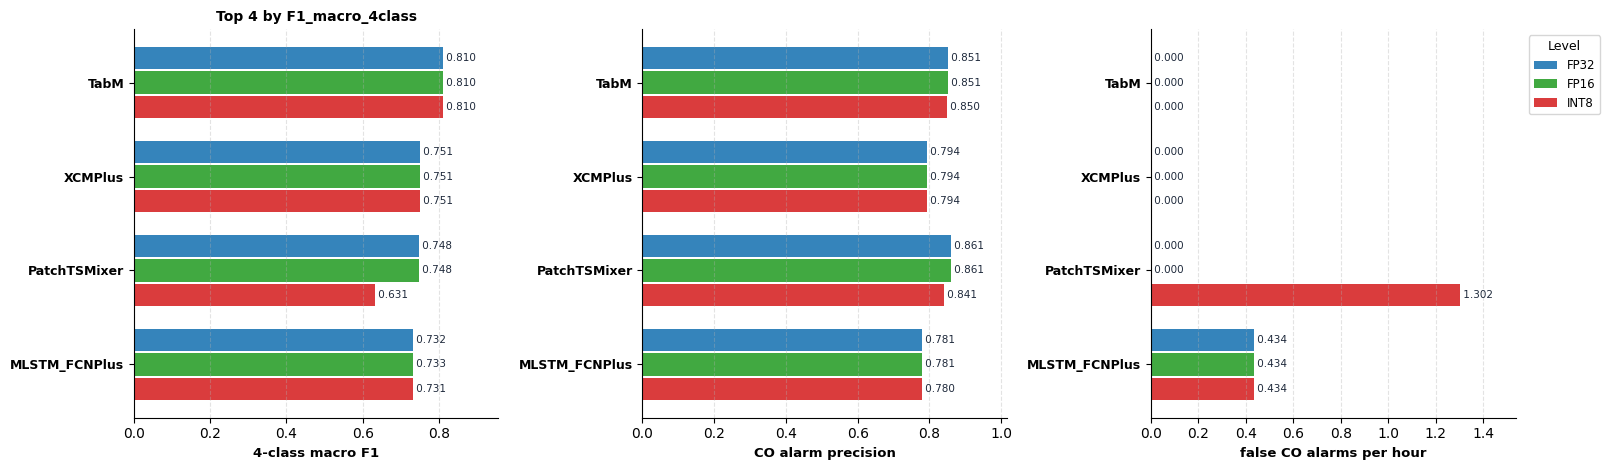

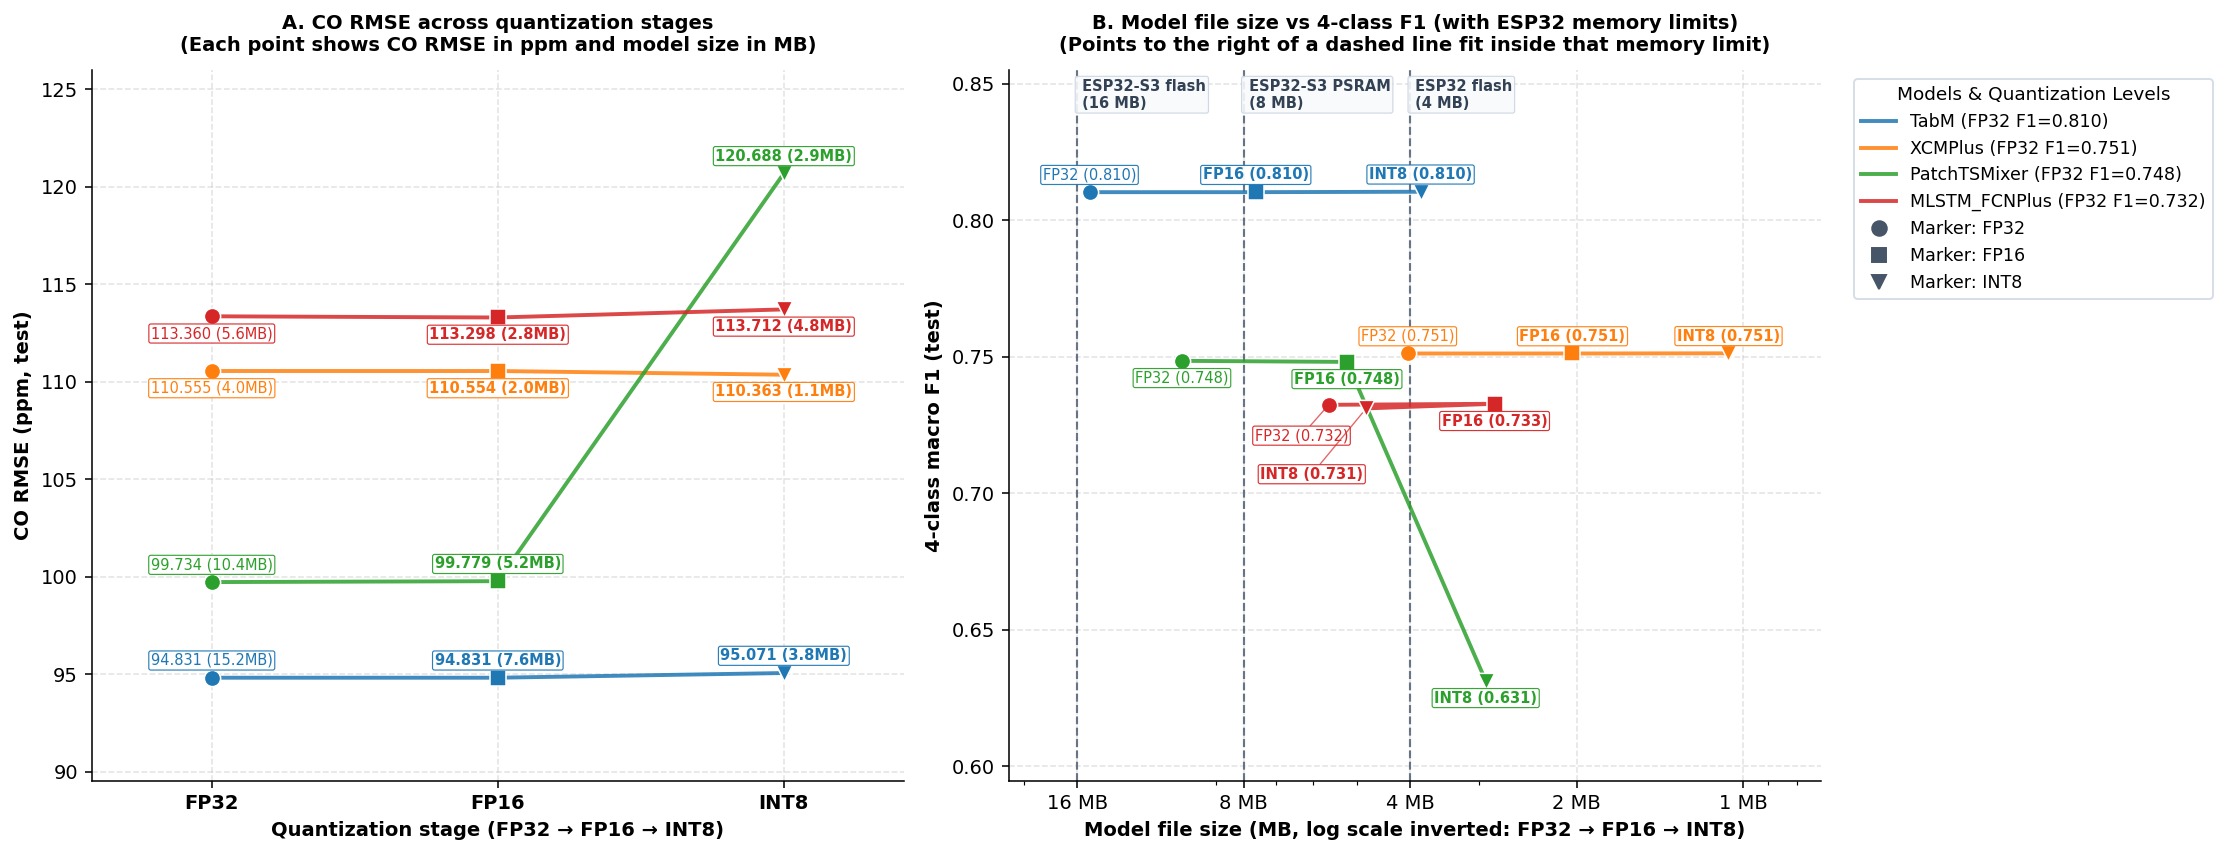

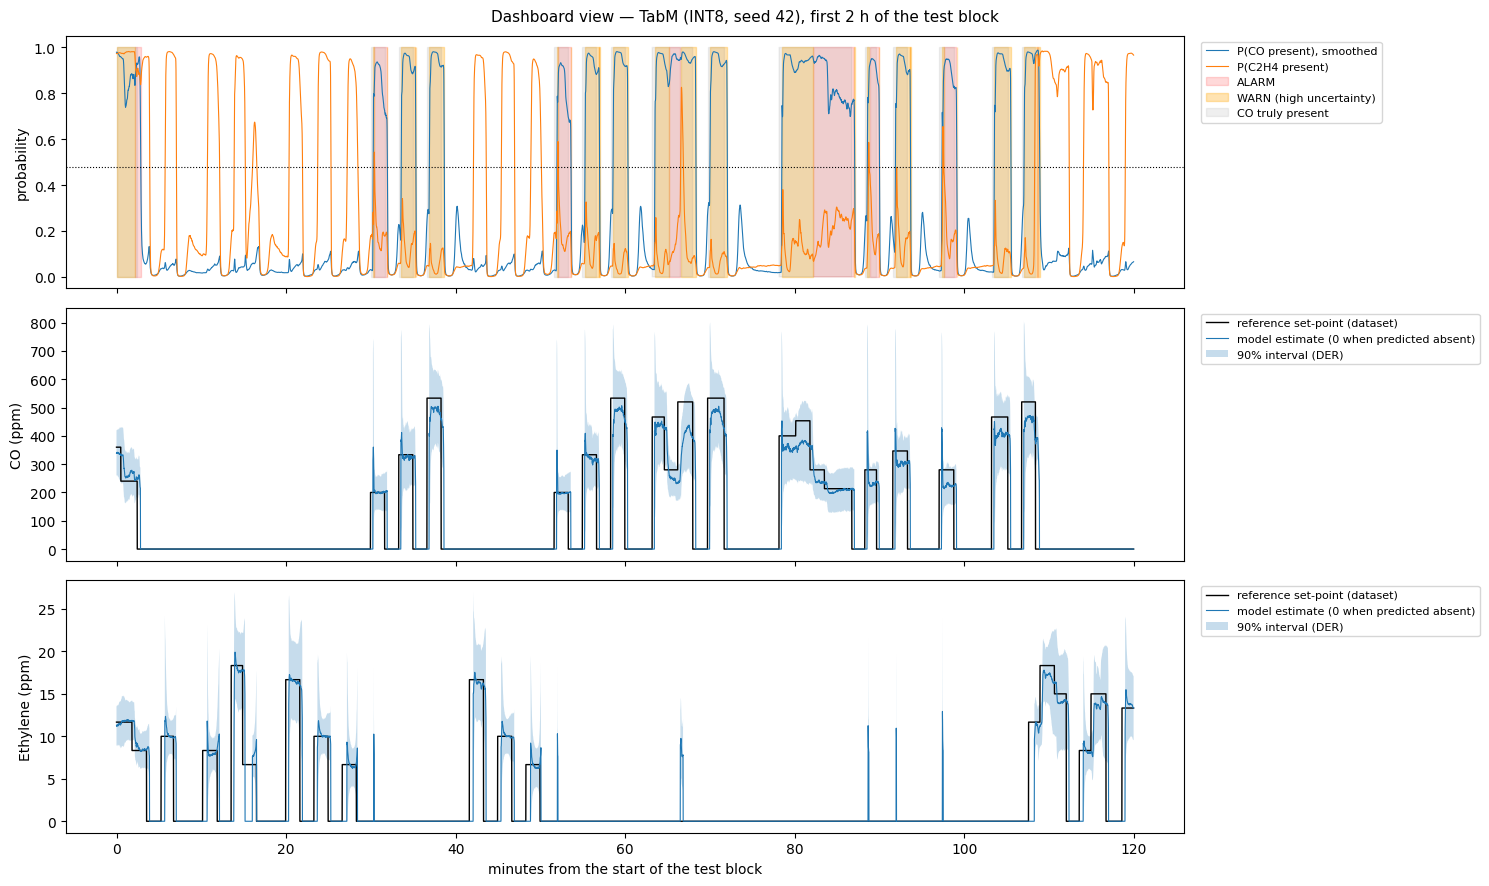

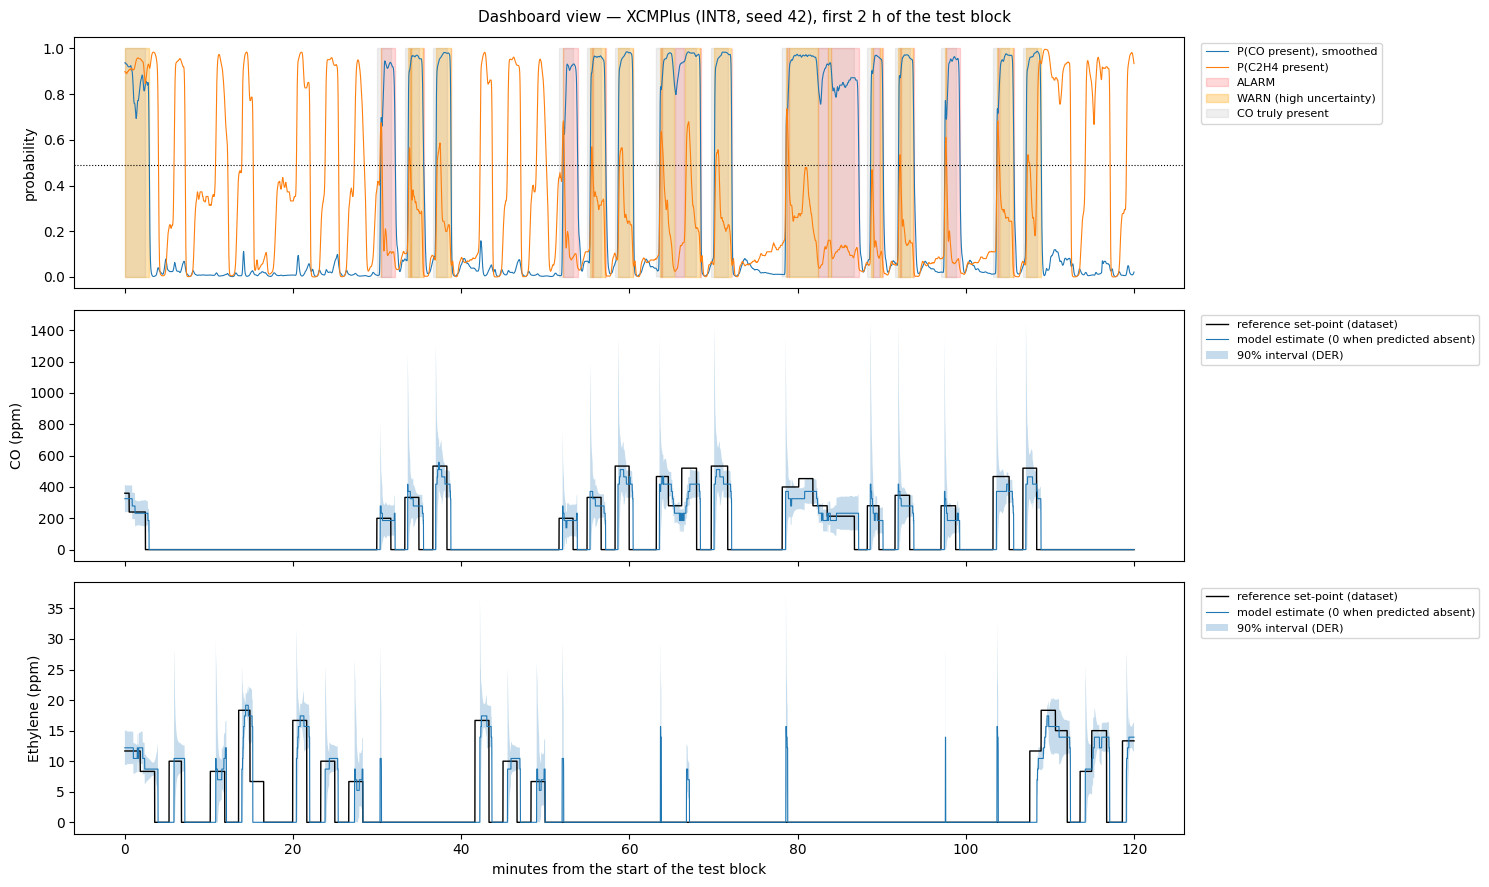

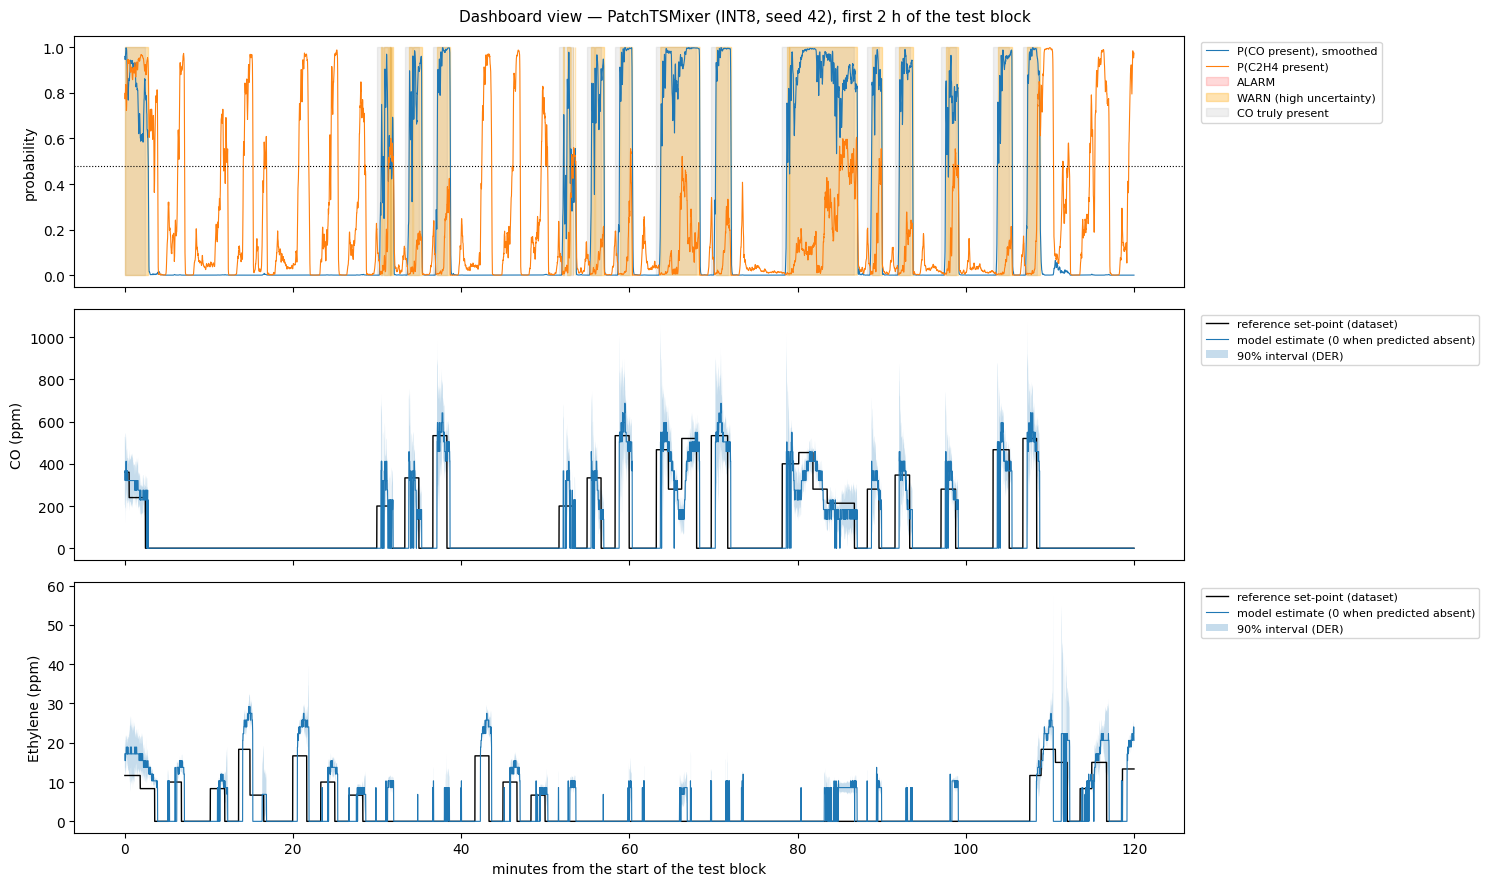

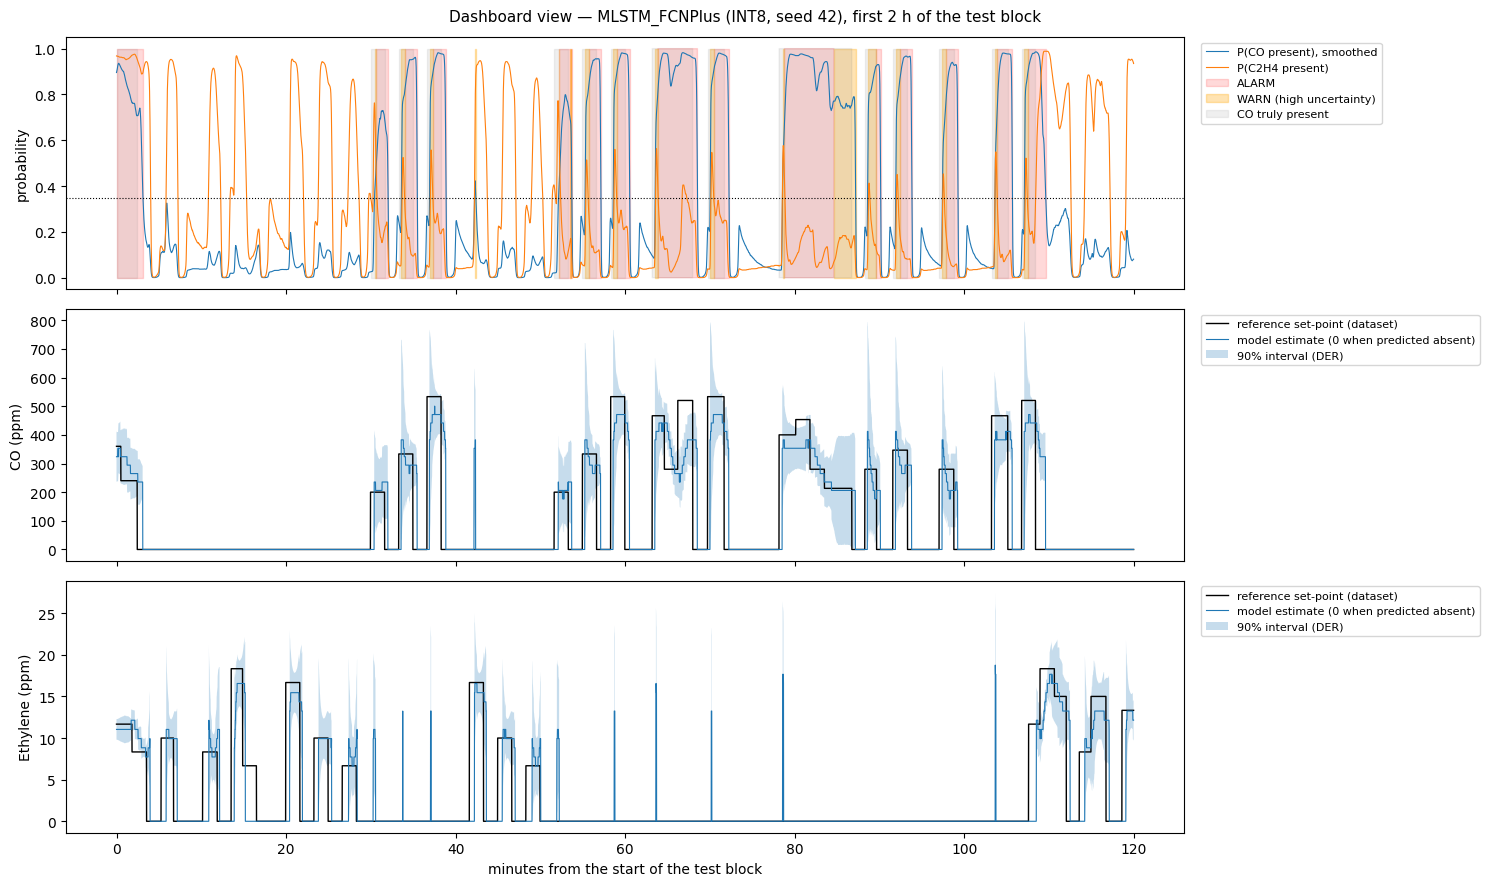

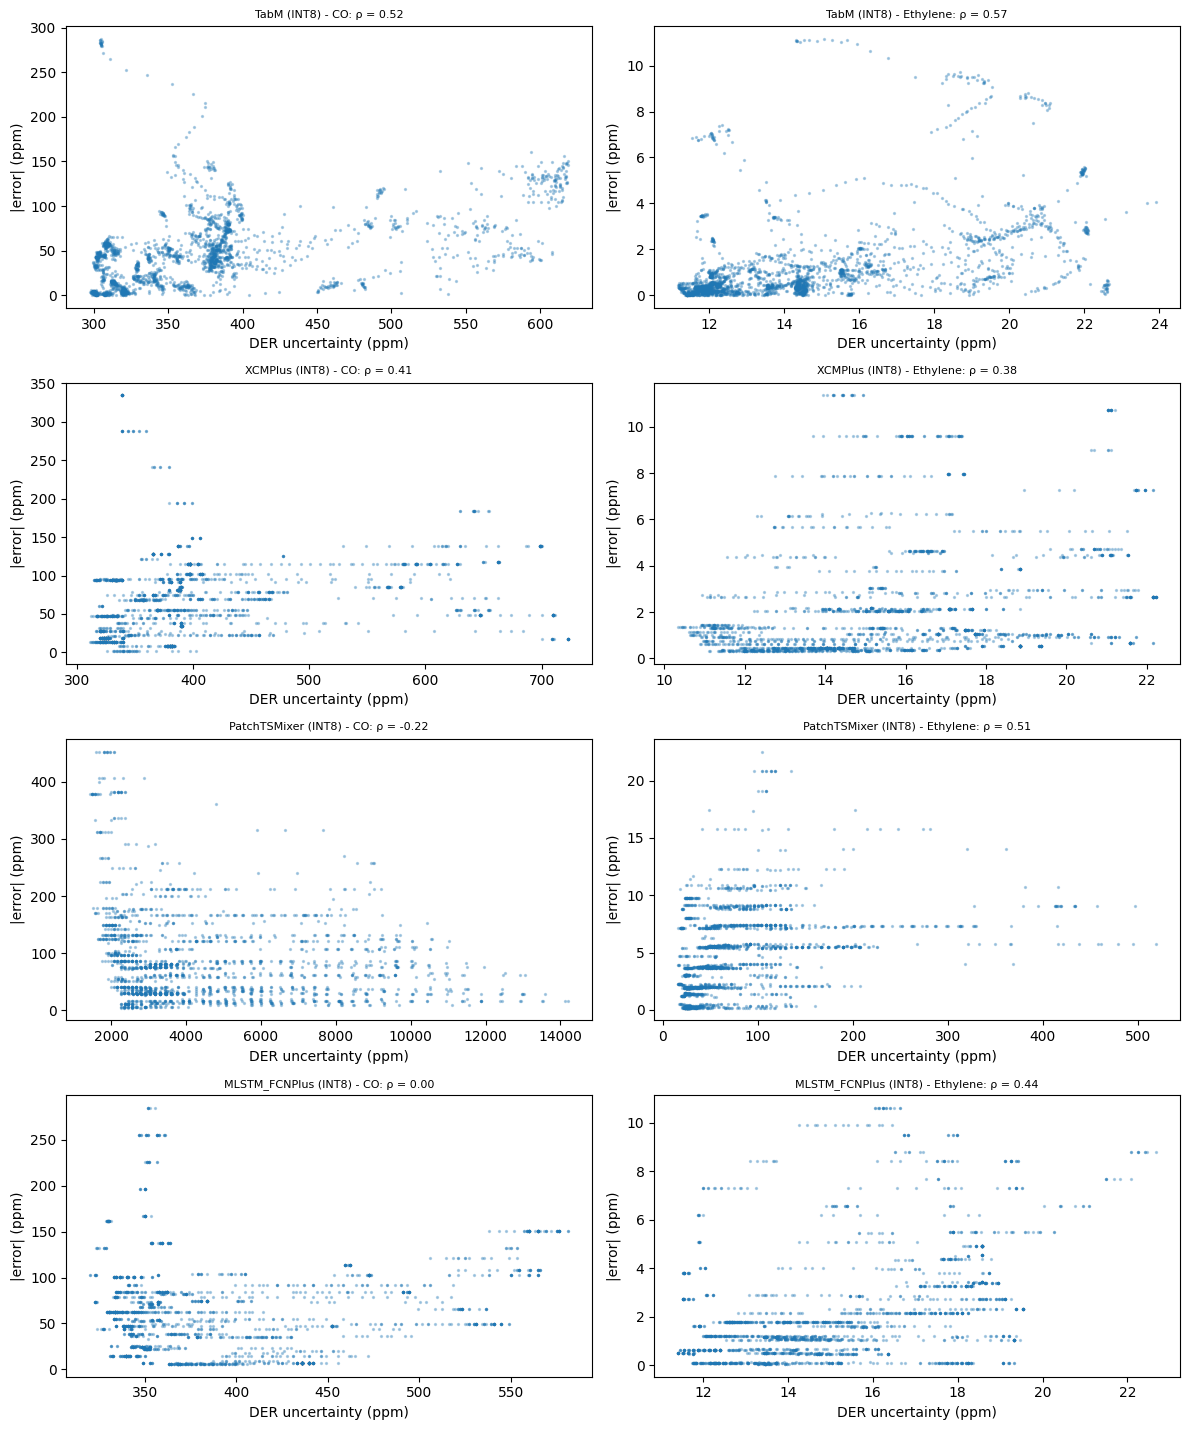

In [ ]:
# ==================== Top-N models: figures (run the Top-N table cell first) ====================
import matplotlib.ticker as ticker

BAR_METRICS = [
    ("F1_macro_4class", "4-class macro F1"),
    ("CO_alarm_prec", "CO alarm precision"),
    ("false_alarms_per_h", "false CO alarms per hour"),
]
DASHBOARD_LEVEL = "int8_static"   # predictions shown in the dashboard view: "fp32" (PyTorch) or a level in LEVELS
DASHBOARD_MODELS = None           # None = every network of the top list, or e.g. ["TabM"]
DASHBOARD_HOURS = 2               # length of the test excerpt shown
LEVEL_COLOR = {"fp32": "tab:blue", "fp16": "tab:green", "int8_static": "tab:red"}
LEVEL_MARKER = {"fp32": "o", "fp16": "s", "int8_static": "v"}
MODEL_PALETTE = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]

# Chế độ hiển thị cho biểu đồ số 2:
# - "both"     : Vẽ song song 2 biểu đồ (Trái: FP32 -> FP16 -> INT8; Phải: Dung lượng MB đảo chiều Lớn -> Nhỏ)
# - "level"    : Chỉ vẽ biểu đồ trục hoành phân loại trực tiếp FP32 -> FP16 -> INT8
# - "size_desc": Chỉ vẽ biểu đồ dung lượng MB đảo chiều (FP32 -> FP16 -> INT8) kèm vạch giới hạn ESP32
PLOT2_X_MODE = "both"             # "both" | "level" | "size_desc"
SHOW_VAL_ON_BARS = True           # Hiện giá trị trên thanh bar ở biểu đồ 1 (không kèm %)


def place_smart_labels(ax, items, all_pts_xy, all_segs_xy):
    """Đặt nhãn tự động quanh từng điểm sao cho không bao giờ đè lên nhau, không đè lên điểm/đường vẽ
    và không để đường chỉ (leader line) cắt ngang qua đường của model khác."""
    fig = ax.figure
    fig.canvas.draw()
    trans = ax.transData
    bbox_ax = ax.get_window_extent()
    scale = fig.dpi / 72.0

    pts_px = [trans.transform(pt) for pt in all_pts_xy]
    segs_px, segs_pairs_px = [], []
    for (p1, p2) in all_segs_xy:
        u1, u2 = trans.transform(p1), trans.transform(p2)
        segs_pairs_px.append((u1, u2))
        for tv in np.linspace(0.18, 0.82, 18):
            segs_px.append(u1 * (1 - tv) + u2 * tv)

    def _segments_intersect(a1, a2, b1, b2):
        def ccw(A, B, C):
            return (C[1] - A[1]) * (B[0] - A[0]) > (B[1] - A[1]) * (C[0] - A[0])
        return (ccw(a1, b1, b2) != ccw(a2, b1, b2)) and (ccw(a1, a2, b1) != ccw(a1, a2, b2))

    dy_steps = [5, -5, 8, -8, 12, -12, 17, -17, 23, -23, 30, -30, 38, -38]
    dx_steps = [0, -14, 14, -28, 28, -44, 44]

    placed_boxes = []
    for it in items:
        px, py = trans.transform((it["x"], it["y"]))
        w_px = (len(it["text"]) * 5.2 + 8.0) * scale
        h_px = 11.0 * scale

        pref_dy = it.get("dy_pref", 6)
        pref_dx = it.get("dx_pref", 0)

        cands = [(dx, dy) for dy in dy_steps for dx in dx_steps]
        cands.sort(key=lambda c: (
            abs(c[1]) * 1.4 + abs(c[0]) * 1.0 + (0.0 if np.sign(c[1]) == np.sign(pref_dy) else 2.5)
        ))

        best_cand = cands[0]
        best_cost = 1e18
        best_box = None

        for dx_pt, dy_pt in cands:
            cx = px + dx_pt * scale
            cy = py + dy_pt * scale + (h_px * 0.5 if dy_pt >= 0 else -h_px * 0.5)
            box = (cx - w_px * 0.5, cy - h_px * 0.5, cx + w_px * 0.5, cy + h_px * 0.5)

            cost = 0.0
            if box[0] < bbox_ax.x0 + 3 or box[2] > bbox_ax.x1 - 3:
                cost += 80000.0
            if box[1] < bbox_ax.y0 + 3 or box[3] > bbox_ax.y1 - 26:
                cost += 80000.0

            # 1) Tránh đè lên các hộp nhãn đã đặt trước đó
            for b in placed_boxes:
                ox = max(0.0, min(box[2], b[2]) - max(box[0], b[0]) + 3.0 * scale)
                oy = max(0.0, min(box[3], b[3]) - max(box[1], b[1]) + 2.0 * scale)
                if ox > 0 and oy > 0:
                    cost += 300000.0 + ox * oy * 25.0

            # 2) Tránh đè lên bất kỳ điểm marker nào
            for (mx, my) in pts_px:
                if (box[0] - 3.5 * scale <= mx <= box[2] + 3.5 * scale) and (box[1] - 3.5 * scale <= my <= box[3] + 3.5 * scale):
                    cost += 90000.0

            # 3) Tránh đè lên đoạn thẳng nối giữa các điểm
            for (sx, sy) in segs_px:
                if (box[0] - 1.5 * scale <= sx <= box[2] + 1.5 * scale) and (box[1] - 2.0 * scale <= sy <= box[3] + 2.0 * scale):
                    cost += 25000.0

            # 4) Tránh để đường nối (leader line) cắt ngang qua đường của model khác
            p_start = np.array([px, py])
            p_end = np.array([cx, cy])
            if np.linalg.norm(p_end - p_start) > 8.0 * scale:
                p_s = p_start + 0.15 * (p_end - p_start)
                for (u1, u2) in segs_pairs_px:
                    if _segments_intersect(p_s, p_end, u1, u2):
                        cost += 60000.0

            # 5) Ưu tiên vị trí gần điểm nhất kèm ưu tiên nhẹ theo hướng mặc định (trên/dưới)
            cost += abs(dy_pt) * 1.6 + abs(dx_pt) * 1.1 + (0.0 if np.sign(dy_pt) == np.sign(pref_dy) else 3.0)

            if cost < best_cost:
                best_cost = cost
                best_cand = (dx_pt, dy_pt)
                best_box = box
                if cost < 6.0:
                    break

        placed_boxes.append(best_box)
        dx_pt, dy_pt = best_cand
        dist_pt = (dx_pt ** 2 + dy_pt ** 2) ** 0.5
        use_arrow = dist_pt >= 12.0
        ax.annotate(
            it["text"],
            (it["x"], it["y"]),
            xytext=(dx_pt, dy_pt),
            textcoords="offset points",
            ha="center",
            va="bottom" if dy_pt >= 0 else "top",
            fontsize=7.5,
            fontweight=it.get("fontweight", "bold"),
            color=it["color"],
            bbox=dict(boxstyle="round,pad=0.14", fc="white", ec=it["color"], lw=0.6, alpha=0.94),
            arrowprops=dict(arrowstyle="-", color=it["color"], lw=0.7, alpha=0.7, shrinkA=0, shrinkB=3) if use_arrow else None,
            zorder=6,
        )


if "TOP_ROWS" not in globals() or not len(TOP_ROWS):
    print("Run the Top-N table cell first.")
else:
    T = TOP_ROWS.copy()
    lv_order = ["fp32", "fp16", "int8_static"]
    lv_present = [lv for lv in (LEVELS if "LEVELS" in globals() else lv_order) if lv in set(T.level)]
    lv_present = sorted(lv_present, key=lambda x: lv_order.index(x) if x in lv_order else 99)
    lvl_labels = globals().get("LEVEL_LABELS", {"fp32": "FP32", "fp16": "FP16", "int8_static": "INT8"})
    tag = f"top{TOP_N}"

    # -------------------------------------------------------------------------
    # 1) Quality per model and level (grouped horizontal bars + side legend)
    # -------------------------------------------------------------------------
    fig, ax = plt.subplots(
        1, len(BAR_METRICS),
        figsize=(5.4 * len(BAR_METRICS), 1.2 + 0.9 * len(TOP_MODELS)),
    )
    ax = np.atleast_1d(ax)
    h = 0.78 / max(len(lv_present), 1)

    for idx_a, (a, (col, lab)) in enumerate(zip(ax, BAR_METRICS)):
        max_v = np.nanmax(T[col].to_numpy(dtype=float)) if col in T.columns else 1.0
        for k, lv in enumerate(lv_present):
            sub = T[T.level == lv].set_index("model")
            y, v = [], []
            for i, m in enumerate(TOP_MODELS):
                if m in sub.index and col in sub.columns:
                    y.append(i + k * h)
                    v.append(float(sub.loc[m, col]))

            bars = a.barh(
                y, v, height=h * 0.92,
                color=LEVEL_COLOR.get(lv, "gray"),
                label=lvl_labels.get(lv, lv),
                alpha=0.9,
            )
            if SHOW_VAL_ON_BARS:
                for bar, val in zip(bars, v):
                    if not np.isfinite(val):
                        continue
                    txt = f" {val:.3f}" if max_v <= 2.0 else f" {val:.1f}"
                    a.text(
                        bar.get_width(),
                        bar.get_y() + bar.get_height() / 2,
                        txt,
                        va="center", ha="left", fontsize=7.5, color="#1E293B",
                    )

        a.set_yticks([i + h * (len(lv_present) - 1) / 2 for i in range(len(TOP_MODELS))], TOP_MODELS, fontsize=9, fontweight="bold")
        a.invert_yaxis()
        a.set_xlabel(lab, fontsize=9.5, fontweight="bold")
        a.grid(axis="x", linestyle="--", alpha=0.35)
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        if np.isfinite(max_v) and max_v > 0:
            a.set_xlim(0, max_v * (1.18 if SHOW_VAL_ON_BARS else 1.08))

    ax[-1].legend(
        title="Level",
        fontsize=8.5, title_fontsize=9,
        bbox_to_anchor=(1.02, 1.0), loc="upper left", frameon=True,
    )
    ax[0].set_title(f"Top {TOP_N} by {SORT_BY}", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figures" / f"{tag}_by_model.png", dpi=140, bbox_inches="tight")
    plt.show()

    # # -------------------------------------------------------------------------
    # # 2) FP32 -> FP16 -> INT8 vs quality (Smart anti-collision labels + side legend, NO %)
    # # -------------------------------------------------------------------------
    # q = T.dropna(subset=["size_mb"]).copy()
    # if len(q):
    #     q["lv_rank"] = q["level"].map(lambda x: lv_order.index(x) if x in lv_order else 99)
    #     fp32_order = (
    #         q[q.level == "fp32"]
    #         .set_index("model")
    #         .reindex(TOP_MODELS)["F1_macro_4class"]
    #         .sort_values(ascending=False)
    #         .index.tolist()
    #     )

    #     modes = ["level", "size_desc"] if PLOT2_X_MODE == "both" else [PLOT2_X_MODE]
    #     fig, axes_q = plt.subplots(1, len(modes), figsize=(8.0 * len(modes), 6.2), dpi=140, squeeze=False)
    #     axes_q = axes_q[0]
    #     pending_placements = []

    #     for ax_idx, mode in enumerate(modes):
    #         # ax_q = axes_q[ax_idx]
    #         ax_q = axes_q[ax_idx]
    #         metric_col = "RMSE_CO" if mode == "level" else "F1_macro_4class"  # đổi thành "RMSE_Ethylene" nếu muốn vẽ C2H4
    #         fp32_order = (
    #             q[q.level == "fp32"]
    #             .set_index("model")
    #             .reindex(TOP_MODELS)[metric_col]
    #             .sort_values(ascending=False)
    #             .index.tolist()
    #         )
    #         items_m, pts_m, segs_m = [], [], []
    #         items_m, pts_m, segs_m = [], [], []

    #         for i, m in enumerate(TOP_MODELS):
    #             g = q[q.model == m].sort_values("lv_rank")
    #             if not len(g):
    #                 continue
    #             col_c = MODEL_PALETTE[i % len(MODEL_PALETTE)]

    #             # fp32_row = g[g.level == "fp32"]
    #             # f1_base = float(fp32_row["F1_macro_4class"].iloc[0]) if len(fp32_row) else float(g["F1_macro_4class"].iloc[0])

    #             # y_vals = g["F1_macro_4class"].to_numpy(dtype=float)

    #             fp32_row = g[g.level == "fp32"]
    #             f1_base = float(fp32_row[metric_col].iloc[0]) if len(fp32_row) else float(g[metric_col].iloc[0])

    #             y_vals = g[metric_col].to_numpy(dtype=float)

    #             x_vals = g["lv_rank"].to_numpy(dtype=float) if mode == "level" else g["size_mb"].to_numpy(dtype=float)

    #             leg_lbl = f"{m} (FP32 F1={f1_base:.3f})"
    #             ax_q.plot(x_vals, y_vals, "-", color=col_c, lw=2.0, alpha=0.85, label=leg_lbl, zorder=3)

    #             for k_seg in range(len(x_vals) - 1):
    #                 segs_m.append(((x_vals[k_seg], y_vals[k_seg]), (x_vals[k_seg + 1], y_vals[k_seg + 1])))

    #             rank_idx = fp32_order.index(m) if m in fp32_order else i
    #             dy_default = 6 if rank_idx < max(len(fp32_order) // 2, 1) else -6

    #             for idx_pt, (_, r) in enumerate(g.iterrows()):
    #                 xv, yv = x_vals[idx_pt], y_vals[idx_pt]
    #                 pts_m.append((xv, yv))
    #                 lv_short = lvl_labels.get(r.level, r.level)
    #                 ax_q.scatter(
    #                     xv, yv, color=col_c, marker=LEVEL_MARKER.get(r.level, "o"),
    #                     s=70, edgecolors="white", linewidths=0.8, zorder=5,
    #                 )
    #                 if mode == "level":
    #                     txt = f"{yv:.3f} ({r.size_mb:.1f}MB)"
    #                     fw = "bold" if r.level != "fp32" else "normal"
    #                 else:
    #                     txt = f"{lv_short} ({yv:.3f})"
    #                     fw = "bold" if r.level != "fp32" else "normal"

    #                 items_m.append({
    #                     "x": xv, "y": yv, "text": txt, "color": col_c,
    #                     "fontweight": fw, "dy_pref": dy_default, "dx_pref": 0,
    #                 })

    #         if mode == "level":
    #             txt = f"{yv:.1f} ({r.size_mb:.1f}MB)"
    #             fw = "bold" if r.level != "fp32" else "normal"

    #             ax_q.set_xticks(range(len(lv_present)), [lvl_labels.get(lv, lv) for lv in lv_present], fontsize=10, fontweight="bold")
    #             ax_q.set_xlim(-0.42, len(lv_present) - 0.58)
    #             ylo, yhi = ax_q.get_ylim()
    #             span_y = max(yhi - ylo, 1e-3)
    #             ax_q.set_ylim(ylo - 0.14 * span_y, yhi + 0.14 * span_y)

    #             # ax_q.set_xlabel("Quantization stage (FP32 → FP16 → INT8)", fontsize=10, fontweight="bold")
    #             # ax_q.set_title("A. Performance trend across quantization stages\n(Each point shows 4-class F1 score and model size in MB)", fontsize=10, fontweight="bold", pad=10)
    #             # ax_q.grid(True, linestyle="--", alpha=0.35)

    #             ax_q.set_xlabel("Quantization stage (FP32 → FP16 → INT8)", fontsize=10, fontweight="bold")
    #             ax_q.set_ylabel("CO RMSE (ppm, test)", fontsize=10, fontweight="bold")
    #             ax_q.set_title("A. RMSE trend across quantization stages\n(Each point shows CO RMSE in ppm and model size in MB)", fontsize=10, fontweight="bold", pad=10)
    #             ax_q.grid(True, linestyle="--", alpha=0.35)
    #         else:
    #             ax_q.set_xscale("log")
    #             ax_q.invert_xaxis()
    #             mb_ticks = [64, 32, 16, 8, 4, 2, 1, 0.5, 0.25]
    #             xmin_cur, xmax_cur = min(q["size_mb"]) * 0.68, max(q["size_mb"]) * 1.40
    #             ax_q.set_xlim(xmax_cur, xmin_cur)
    #             valid_ticks = [t_mb for t_mb in mb_ticks if xmin_cur <= t_mb <= xmax_cur]
    #             if valid_ticks:
    #                 ax_q.set_xticks(valid_ticks)
    #             ax_q.get_xaxis().set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:g} MB"))
    #             ax_q.xaxis.set_minor_formatter(ticker.NullFormatter())

    #             ylo2, yhi2 = ax_q.get_ylim()
    #             span_y2 = max(yhi2 - ylo2, 1e-3)
    #             ax_q.set_ylim(ylo2 - 0.14 * span_y2, yhi2 + 0.18 * span_y2)

    #             for lim, mb in ESP32_LIMITS_MB.items():
    #                 if xmin_cur <= mb <= xmax_cur:
    #                     ax_q.axvline(mb, color="#475569", ls="--", lw=1.1, alpha=0.8, zorder=2)
    #                     ax_q.text(
    #                         mb, ax_q.get_ylim()[1] - 0.015 * span_y2,
    #                         f" {lim}\n ({mb:g} MB)",
    #                         rotation=0, va="top", ha="left", fontsize=7.5, color="#334155", fontweight="bold",
    #                         bbox=dict(boxstyle="round,pad=0.15", fc="#F8FAFC", ec="#CBD5E1", lw=0.6, alpha=0.9),
    #                     )

    #             # ax_q.set_xlabel("Model file size (MB, log scale inverted: FP32 → FP16 → INT8)", fontsize=10, fontweight="bold")
    #             # ax_q.set_title("B. Model file size vs 4-class F1 (with ESP32 memory limits)\n(Points to the right of a dashed line fit inside that memory limit)", fontsize=10, fontweight="bold", pad=10)
    #             # ax_q.grid(True, which="major", linestyle="--", alpha=0.35)

    #             ax_q.set_xlabel("Model file size (MB, log scale inverted: FP32 → FP16 → INT8)", fontsize=10, fontweight="bold")
    #             ax_q.set_ylabel("4-class macro F1 (test)", fontsize=10, fontweight="bold")
    #             ax_q.set_title("B. Model file size vs 4-class F1 (with ESP32 memory limits)\n(Points to the right of a dashed line fit inside that memory limit)", fontsize=10, fontweight="bold", pad=10)
    #             ax_q.grid(True, which="major", linestyle="--", alpha=0.35)

    #         ax_q.set_ylabel("4-class macro F1 (test)", fontsize=10, fontweight="bold")
    #         ax_q.spines["top"].set_visible(False)
    #         ax_q.spines["right"].set_visible(False)
    #         pending_placements.append((ax_q, items_m, pts_m, segs_m))

    #     handles, labels = axes_q[-1].get_legend_handles_labels()
    #     for lv_key in lv_present:
    #         handles.append(
    #             plt.Line2D(
    #                 [0], [0], color="#475569", marker=LEVEL_MARKER.get(lv_key, "o"),
    #                 linestyle="None", markersize=7.5, label=f"Marker: {lvl_labels.get(lv_key, lv_key)}",
    #             )
    #         )
    #     axes_q[-1].legend(
    #         handles=handles,
    #         title="Models & Quantization Levels",
    #         fontsize=9, title_fontsize=9.5,
    #         bbox_to_anchor=(1.03, 1.0), loc="upper left", frameon=True, edgecolor="#CBD5E1",
    #     )

    #     plt.tight_layout()
    #     for (ax_q, items_m, pts_m, segs_m) in pending_placements:
    #         place_smart_labels(ax_q, items_m, pts_m, segs_m)

    #     plt.savefig(OUTPUT_DIR / "figures" / f"{tag}_size_vs_f1.png", dpi=140, bbox_inches="tight")
    #     plt.show()

    # # -------------------------------------------------------------------------
    # # Helper: test predictions + thresholds of one model at one level
    # # -------------------------------------------------------------------------
    # def top_pred(model, level):
    #     key = f"{model}_seed{SEED}"
    #     p = None
    #     if level != "fp32" and "QPREDS" in globals():
    #         p = QPREDS.get((key, level))
    #     if p is None:
    #         preds_source = PREDS if len(PREDS) else globals().get("SRC_PREDS", {})
    #         p, level = preds_source.get(key), "fp32"
    #     thresh_source = THRESH if len(THRESH) else globals().get("SRC_THRESH", {})
    #     th = thresh_source[key]
    #     return p, np.array(th["tau"], float), np.array(th["uct_cut_ppm"], float), level

    # nets = [m for m in TOP_MODELS if RANK.loc[m, "family"].startswith("Network")]
    # if DASHBOARD_MODELS is not None:
    #     nets = [m for m in nets if m in DASHBOARD_MODELS]
    # d = DATA["test"]
    # span = slice(0, min(len(d["end_idx"]), int(DASHBOARD_HOURS * 3600 * RESAMPLE_HZ)))
    # t = (d["end_idx"][span] - d["end_idx"][0]) / RESAMPLE_HZ / 60


    # -------------------------------------------------------------------------
    # 2) FP32 -> FP16 -> INT8 vs quality
    #    Figure A: CO RMSE vs quantization stage
    #    Figure B: 4-class macro F1 vs model size
    # -------------------------------------------------------------------------
    q = T.dropna(subset=["size_mb"]).copy()

    if len(q):
        q["lv_rank"] = q["level"].map(
            lambda x: lv_order.index(x) if x in lv_order else 99
        )

        modes = (
            ["level", "size_desc"]
            if PLOT2_X_MODE == "both"
            else [PLOT2_X_MODE]
        )

        fig, axes_q = plt.subplots(
            1,
            len(modes),
            figsize=(8.0 * len(modes), 6.2),
            dpi=140,
            squeeze=False,
        )
        axes_q = axes_q[0]
        pending_placements = []

        for ax_idx, mode in enumerate(modes):
            ax_q = axes_q[ax_idx]

            # Chọn metric riêng cho từng hình
            metric_col = (
                "RMSE_CO" if mode == "level"
                else "F1_macro_4class"
            )

            # Thứ tự model dựa trên kết quả FP32 của metric đang xét
            fp32_metric = (
                q[q.level == "fp32"]
                .set_index("model")[metric_col]
                .reindex(TOP_MODELS)
            )
            fp32_order = (
                fp32_metric
                .dropna()
                .sort_values(ascending=(mode == "level"))
                .index.tolist()
            )

            items_m, pts_m, segs_m = [], [], []

            for i, m in enumerate(TOP_MODELS):
                g = q[q.model == m].sort_values("lv_rank")

                if g.empty or metric_col not in g.columns:
                    continue

                # Chỉ lấy các hàng có giá trị hợp lệ cho metric
                g = g.dropna(subset=[metric_col]).copy()
                if g.empty:
                    continue

                col_c = MODEL_PALETTE[i % len(MODEL_PALETTE)]

                # Giá trị FP32 dùng trong legend
                fp32_row = g[g.level == "fp32"]
                f1_base = (
                    float(fp32_row[metric_col].iloc[0])
                    if not fp32_row.empty
                    else float(g[metric_col].iloc[0])
                )

                y_vals = g[metric_col].to_numpy(dtype=float)

                # Trục X:
                # Hình A: thứ tự quantization
                # Hình B: kích thước model (MB)
                x_vals = (
                    g["lv_rank"].to_numpy(dtype=float)
                    if mode == "level"
                    else g["size_mb"].to_numpy(dtype=float)
                )

                leg_lbl = (
                    f"{m} (FP32 CO RMSE={f1_base:.3f})"
                    if mode == "level"
                    else f"{m} (FP32 F1={f1_base:.3f})"
                )

                ax_q.plot(
                    x_vals,
                    y_vals,
                    "-",
                    color=col_c,
                    lw=2.0,
                    alpha=0.85,
                    label=leg_lbl,
                    zorder=3,
                )

                # Lưu các đoạn nối để thuật toán đặt nhãn tránh đường vẽ
                for k_seg in range(len(x_vals) - 1):
                    segs_m.append(
                        (
                            (x_vals[k_seg], y_vals[k_seg]),
                            (x_vals[k_seg + 1], y_vals[k_seg + 1]),
                        )
                    )

                rank_idx = (
                    fp32_order.index(m)
                    if m in fp32_order
                    else i
                )
                dy_default = (
                    6
                    if rank_idx < max(len(fp32_order) // 2, 1)
                    else -6
                )

                for idx_pt, (_, r) in enumerate(g.iterrows()):
                    xv = x_vals[idx_pt]
                    yv = y_vals[idx_pt]

                    pts_m.append((xv, yv))

                    lv_short = lvl_labels.get(r.level, r.level)

                    ax_q.scatter(
                        xv,
                        yv,
                        color=col_c,
                        marker=LEVEL_MARKER.get(r.level, "o"),
                        s=70,
                        edgecolors="white",
                        linewidths=0.8,
                        zorder=5,
                    )

                    if mode == "level":
                        txt = f"{yv:.3f} ({r.size_mb:.1f}MB)"
                    else:
                        txt = f"{lv_short} ({yv:.3f})"

                    fw = "bold" if r.level != "fp32" else "normal"

                    items_m.append(
                        {
                            "x": xv,
                            "y": yv,
                            "text": txt,
                            "color": col_c,
                            "fontweight": fw,
                            "dy_pref": dy_default,
                            "dx_pref": 0,
                        }
                    )

            # -------------------------------------------------------------
            # Cấu hình riêng cho hình A: RMSE theo quantization stage
            # -------------------------------------------------------------
            if mode == "level":
                ax_q.set_xticks(
                    range(len(lv_present)),
                    [lvl_labels.get(lv, lv) for lv in lv_present],
                    fontsize=10,
                    fontweight="bold",
                )

                ax_q.set_xlim(-0.42, len(lv_present) - 0.58)

                ylo, yhi = ax_q.get_ylim()
                span_y = max(yhi - ylo, 1e-3)
                ax_q.set_ylim(
                    ylo - 0.14 * span_y,
                    yhi + 0.14 * span_y,
                )

                ax_q.set_xlabel(
                    "Quantization stage (FP32 → FP16 → INT8)",
                    fontsize=10,
                    fontweight="bold",
                )

                ax_q.set_title(
                    "A. CO RMSE across quantization stages\n"
                    "(Each point shows CO RMSE in ppm and model size in MB)",
                    fontsize=10,
                    fontweight="bold",
                    pad=10,
                )

                ax_q.grid(True, linestyle="--", alpha=0.35)

            # -------------------------------------------------------------
            # Cấu hình riêng cho hình B: F1 theo kích thước model
            # -------------------------------------------------------------
            else:
                ax_q.set_xscale("log")
                ax_q.invert_xaxis()

                mb_ticks = [
                    64, 32, 16, 8, 4, 2, 1, 0.5, 0.25
                ]

                positive_sizes = q.loc[
                    q["size_mb"] > 0, "size_mb"
                ]

                if positive_sizes.empty:
                    raise ValueError(
                        "No positive model sizes available for log scale."
                    )

                xmin_cur = positive_sizes.min() * 0.68
                xmax_cur = positive_sizes.max() * 1.40

                ax_q.set_xlim(xmax_cur, xmin_cur)

                valid_ticks = [
                    t_mb for t_mb in mb_ticks
                    if xmin_cur <= t_mb <= xmax_cur
                ]

                if valid_ticks:
                    ax_q.set_xticks(valid_ticks)

                ax_q.get_xaxis().set_major_formatter(
                    ticker.FuncFormatter(
                        lambda x, _: f"{x:g} MB"
                    )
                )
                ax_q.xaxis.set_minor_formatter(
                    ticker.NullFormatter()
                )

                ylo2, yhi2 = ax_q.get_ylim()
                span_y2 = max(yhi2 - ylo2, 1e-3)

                ax_q.set_ylim(
                    ylo2 - 0.14 * span_y2,
                    yhi2 + 0.18 * span_y2,
                )

                # Vạch giới hạn bộ nhớ ESP32
                for lim, mb in ESP32_LIMITS_MB.items():
                    if xmin_cur <= mb <= xmax_cur:
                        ax_q.axvline(
                            mb,
                            color="#475569",
                            ls="--",
                            lw=1.1,
                            alpha=0.8,
                            zorder=2,
                        )

                        ax_q.text(
                            mb,
                            ax_q.get_ylim()[1] - 0.015 * span_y2,
                            f" {lim}\n ({mb:g} MB)",
                            rotation=0,
                            va="top",
                            ha="left",
                            fontsize=7.5,
                            color="#334155",
                            fontweight="bold",
                            bbox=dict(
                                boxstyle="round,pad=0.15",
                                fc="#F8FAFC",
                                ec="#CBD5E1",
                                lw=0.6,
                                alpha=0.9,
                            ),
                        )

                ax_q.set_xlabel(
                    "Model file size (MB, log scale inverted: "
                    "FP32 → FP16 → INT8)",
                    fontsize=10,
                    fontweight="bold",
                )

                ax_q.set_title(
                    "B. Model file size vs 4-class F1 "
                    "(with ESP32 memory limits)\n"
                    "(Points to the right of a dashed line fit "
                    "inside that memory limit)",
                    fontsize=10,
                    fontweight="bold",
                    pad=10,
                )

                ax_q.grid(
                    True,
                    which="major",
                    linestyle="--",
                    alpha=0.35,
                )

            # -------------------------------------------------------------
            # FIX: Nhãn trục Y riêng cho từng hình
            # -------------------------------------------------------------
            if mode == "level":
                ax_q.set_ylabel(
                    "CO RMSE (ppm, test)",
                    fontsize=10,
                    fontweight="bold",
                )
            else:
                ax_q.set_ylabel(
                    "4-class macro F1 (test)",
                    fontsize=10,
                    fontweight="bold",
                )

            ax_q.spines["top"].set_visible(False)
            ax_q.spines["right"].set_visible(False)

            pending_placements.append(
                (ax_q, items_m, pts_m, segs_m)
            )

        # -------------------------------------------------------------
        # Legend: models + quantization levels
        # -------------------------------------------------------------
        handles, labels = axes_q[-1].get_legend_handles_labels()

        for lv_key in lv_present:
            handles.append(
                plt.Line2D(
                    [0],
                    [0],
                    color="#475569",
                    marker=LEVEL_MARKER.get(lv_key, "o"),
                    linestyle="None",
                    markersize=7.5,
                    label=f"Marker: {lvl_labels.get(lv_key, lv_key)}",
                )
            )

        axes_q[-1].legend(
            handles=handles,
            title="Models & Quantization Levels",
            fontsize=9,
            title_fontsize=9.5,
            bbox_to_anchor=(1.03, 1.0),
            loc="upper left",
            frameon=True,
            edgecolor="#CBD5E1",
        )

        plt.tight_layout()

        # Đặt nhãn thông minh sau khi layout đã được tính
        for ax_q, items_m, pts_m, segs_m in pending_placements:
            place_smart_labels(
                ax_q,
                items_m,
                pts_m,
                segs_m,
            )

        plt.savefig(
            OUTPUT_DIR / "figures" / f"{tag}_size_vs_f1.png",
            dpi=140,
            bbox_inches="tight",
        )

        plt.show()

    # -------------------------------------------------------------------------
    # 3) Dashboard view: probability, ALARM / WARN, ppm with the 90% DER interval
    # -------------------------------------------------------------------------
    for m in nets:
        pr, tau, ucut, used = top_pred(m, DASHBOARD_LEVEL)
        if pr is None:
            continue
        ps = smooth_causal(pr["prob"], ALARM_SMOOTH_S)[span]
        alarm = ps[:, 0] >= tau[0]
        warn = alarm & (pr["uct_ppm"][span, 0] > ucut[0]) if "uct_ppm" in pr else np.zeros_like(alarm)
        fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
        ax[0].plot(t, ps[:, 0], lw=0.8, label="P(CO present), smoothed")
        ax[0].plot(t, ps[:, 1], lw=0.8, label="P(C2H4 present)")
        ax[0].axhline(tau[0], color="k", ls=":", lw=0.8)
        ax[0].fill_between(t, 0, 1, where=alarm & ~warn, color="red", alpha=0.15, step="mid", label="ALARM")
        ax[0].fill_between(t, 0, 1, where=warn, color="orange", alpha=0.3, step="mid", label="WARN (high uncertainty)")
        ax[0].fill_between(t, 0, 1, where=d["pres"][span, 0] > 0.5, color="gray", alpha=0.12, step="mid", label="CO truly present")
        ax[0].legend(fontsize=8, ncol=1, bbox_to_anchor=(1.01, 1.0), loc="upper left")
        ax[0].set_ylabel("probability")
        for j, gname in enumerate(GAS_NAMES):
            hat = pr["prob"][span, j] >= tau[j]
            ppm = np.where(hat, np.clip(pr["ppm_cond"][span, j], 0, None), 0)
            ax[j + 1].plot(t, d["y_ppm"][span, j], "k", lw=1, label="reference set-point (dataset)")
            ax[j + 1].plot(t, ppm, lw=0.8, label="model estimate (0 when predicted absent)")
            if "scale_ppm" in pr:
                half = scipy.stats.t.ppf(T_Q, pr["df_t"][span, j]) * pr["scale_ppm"][span, j]
                ax[j + 1].fill_between(
                    t,
                    np.where(hat, np.clip(ppm - half, 0, None), np.nan),
                    np.where(hat, ppm + half, np.nan),
                    alpha=0.25, label="90% interval (DER)",
                )
            ax[j + 1].set_ylabel(f"{gname} (ppm)")
            ax[j + 1].legend(fontsize=8, bbox_to_anchor=(1.01, 1.0), loc="upper left")
        ax[-1].set_xlabel("minutes from the start of the test block")
        fig.suptitle(
            f"Dashboard view — {m} ({lvl_labels.get(used, used)}, seed {SEED}), first {DASHBOARD_HOURS} h of the test block",
            fontsize=11,
        )
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "figures" / f"{tag}_dashboard_{m}_{used}.png", dpi=120, bbox_inches="tight")
        plt.show()

    # -------------------------------------------------------------------------
    # 4) Is the DER uncertainty informative? |error| vs predicted uncertainty
    # -------------------------------------------------------------------------
    if nets:
        fig, ax = plt.subplots(len(nets), G, figsize=(12, 3.6 * len(nets)), squeeze=False)
        for i, m in enumerate(nets):
            pr, _, _, used = top_pred(m, DASHBOARD_LEVEL)
            for j, gname in enumerate(GAS_NAMES):
                a = ax[i, j]
                if pr is None or "uct_ppm" not in pr:
                    a.set_axis_off()
                    continue
                mk = d["pres"][:, j] > 0.5
                err = np.abs(d["y_ppm"][mk, j] - pr["ppm_cond"][mk, j])
                a.scatter(pr["uct_ppm"][mk, j], err, s=2, alpha=0.3)
                a.set_xlabel("DER uncertainty (ppm)")
                a.set_ylabel("|error| (ppm)")
                rho = scipy.stats.spearmanr(pr["uct_ppm"][mk, j], err).statistic if mk.sum() > 10 else np.nan
                a.set_title(f"{m} ({lvl_labels.get(used, used)}) - {gname}: ρ = {rho:.2f}", fontsize=8)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "figures" / f"{tag}_uncertainty_vs_error.png", dpi=120, bbox_inches="tight")
        plt.show()

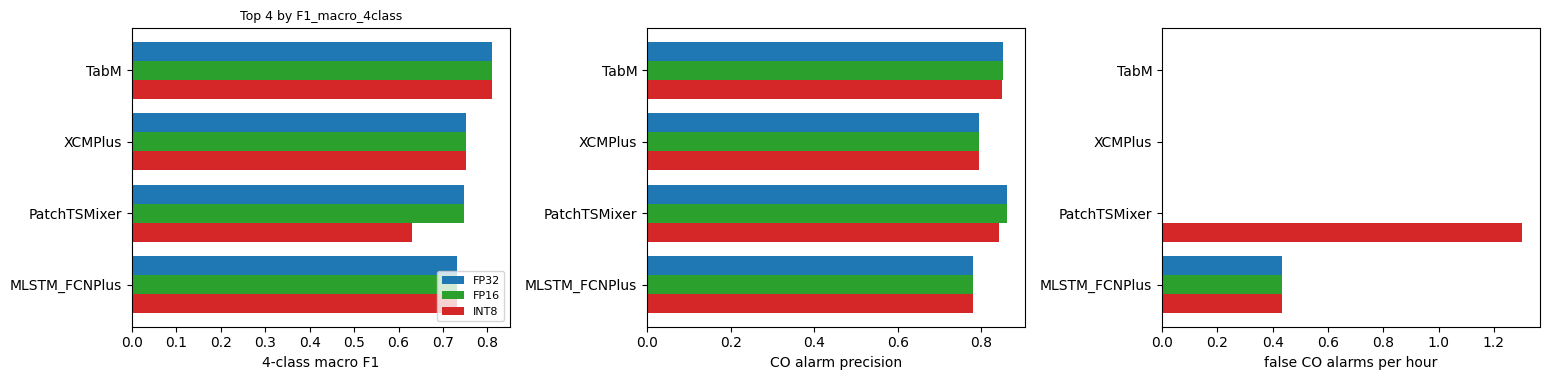

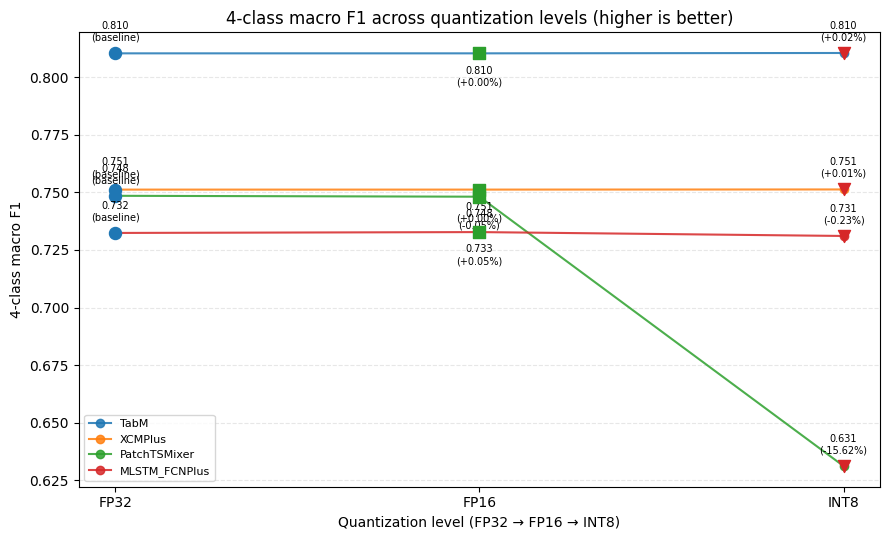

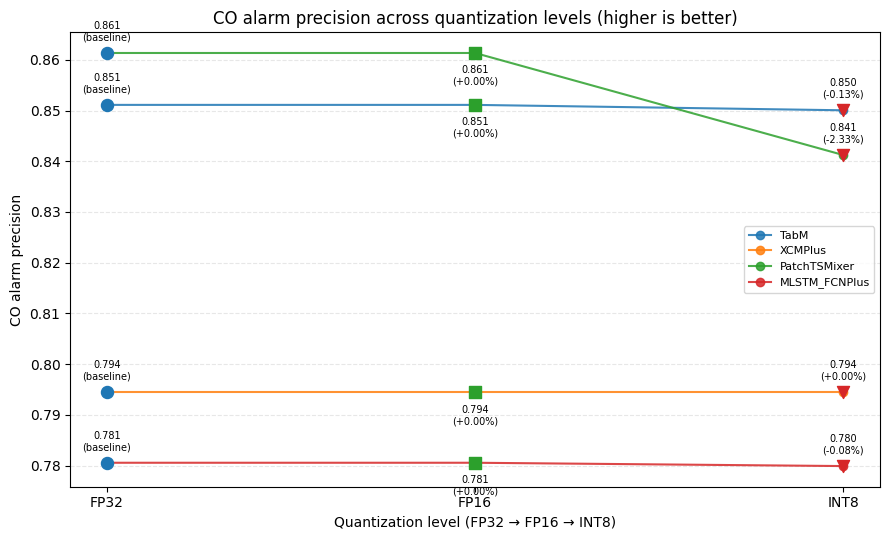

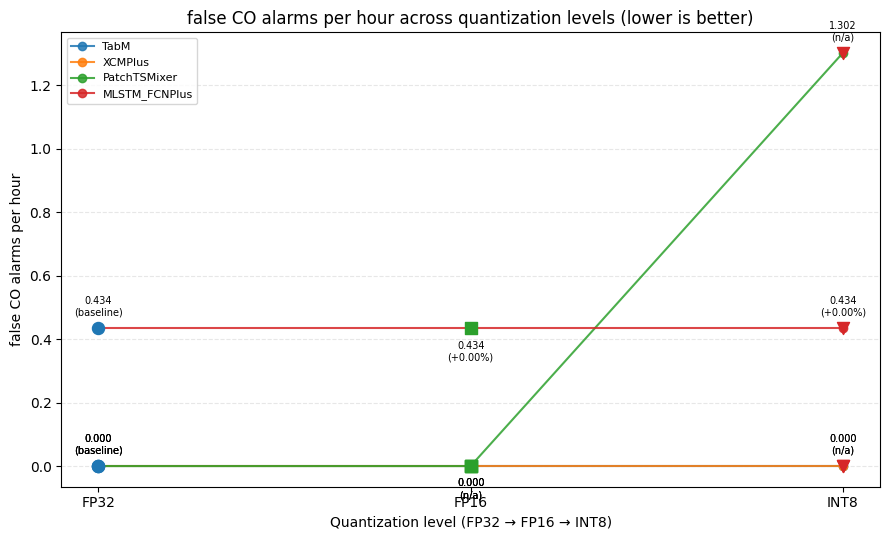

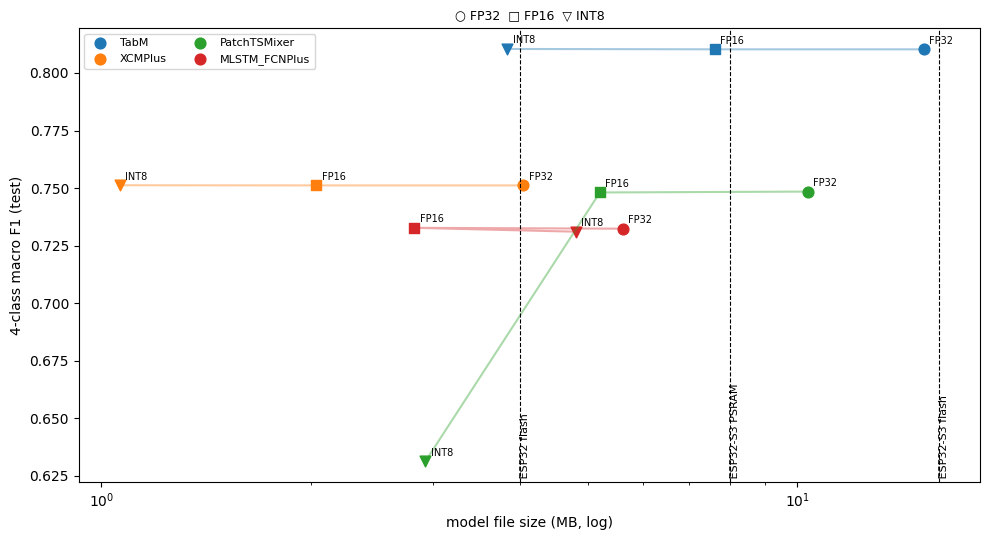

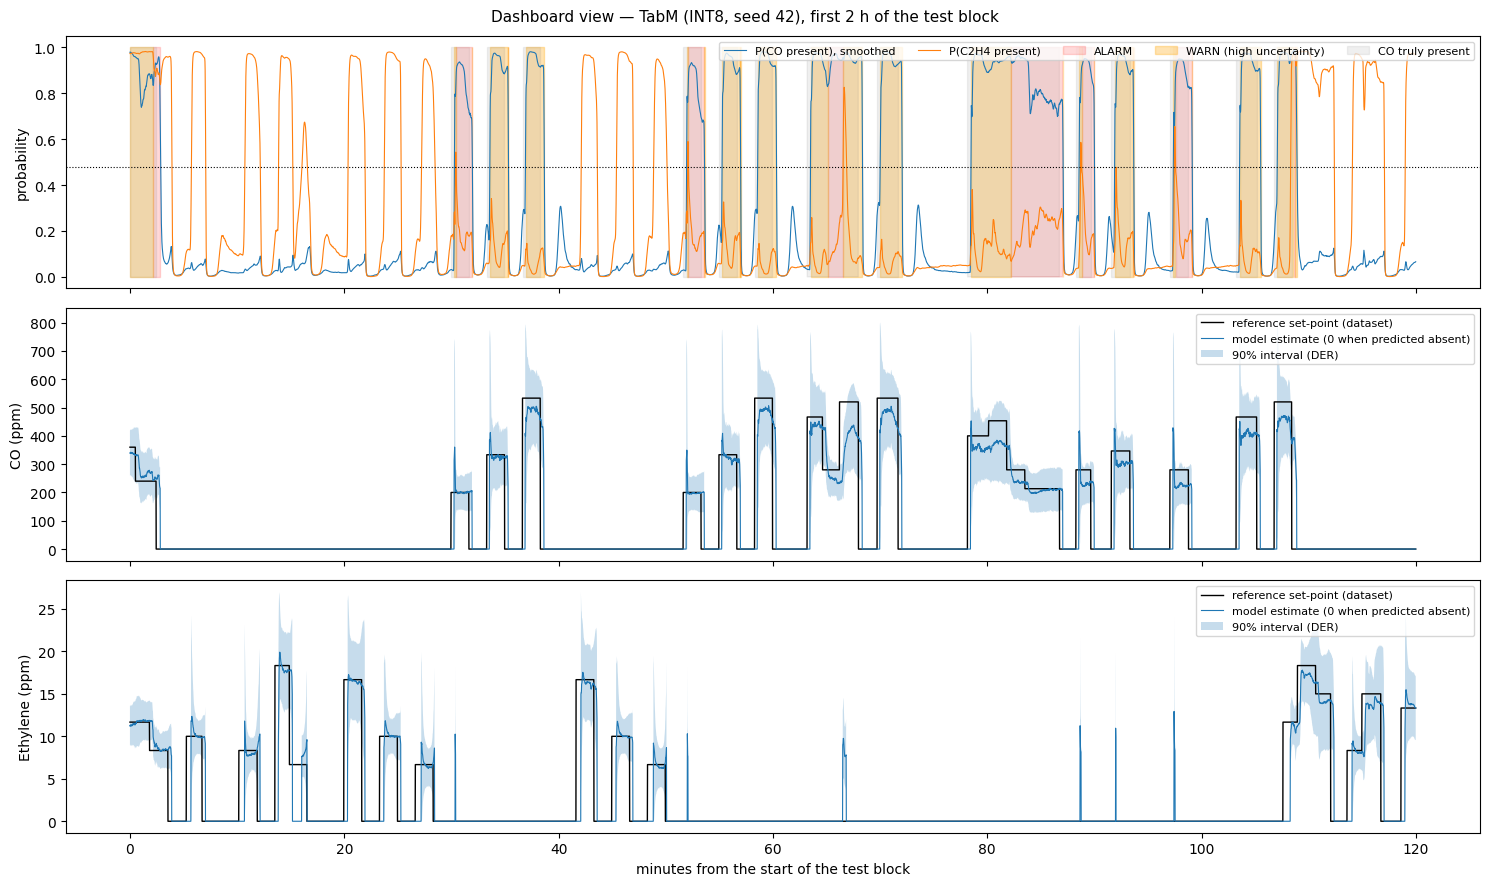

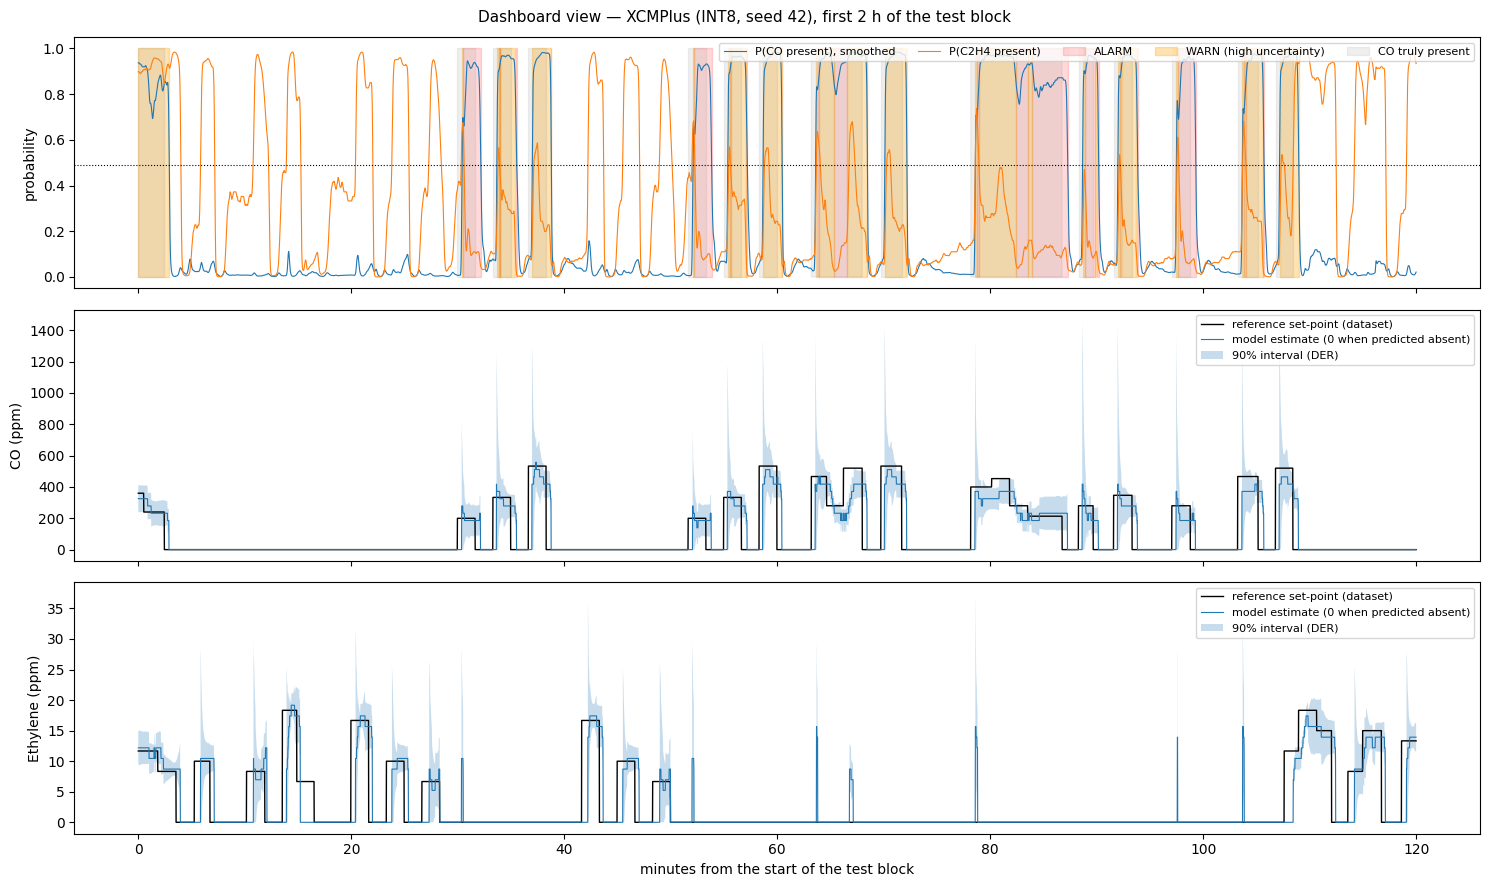

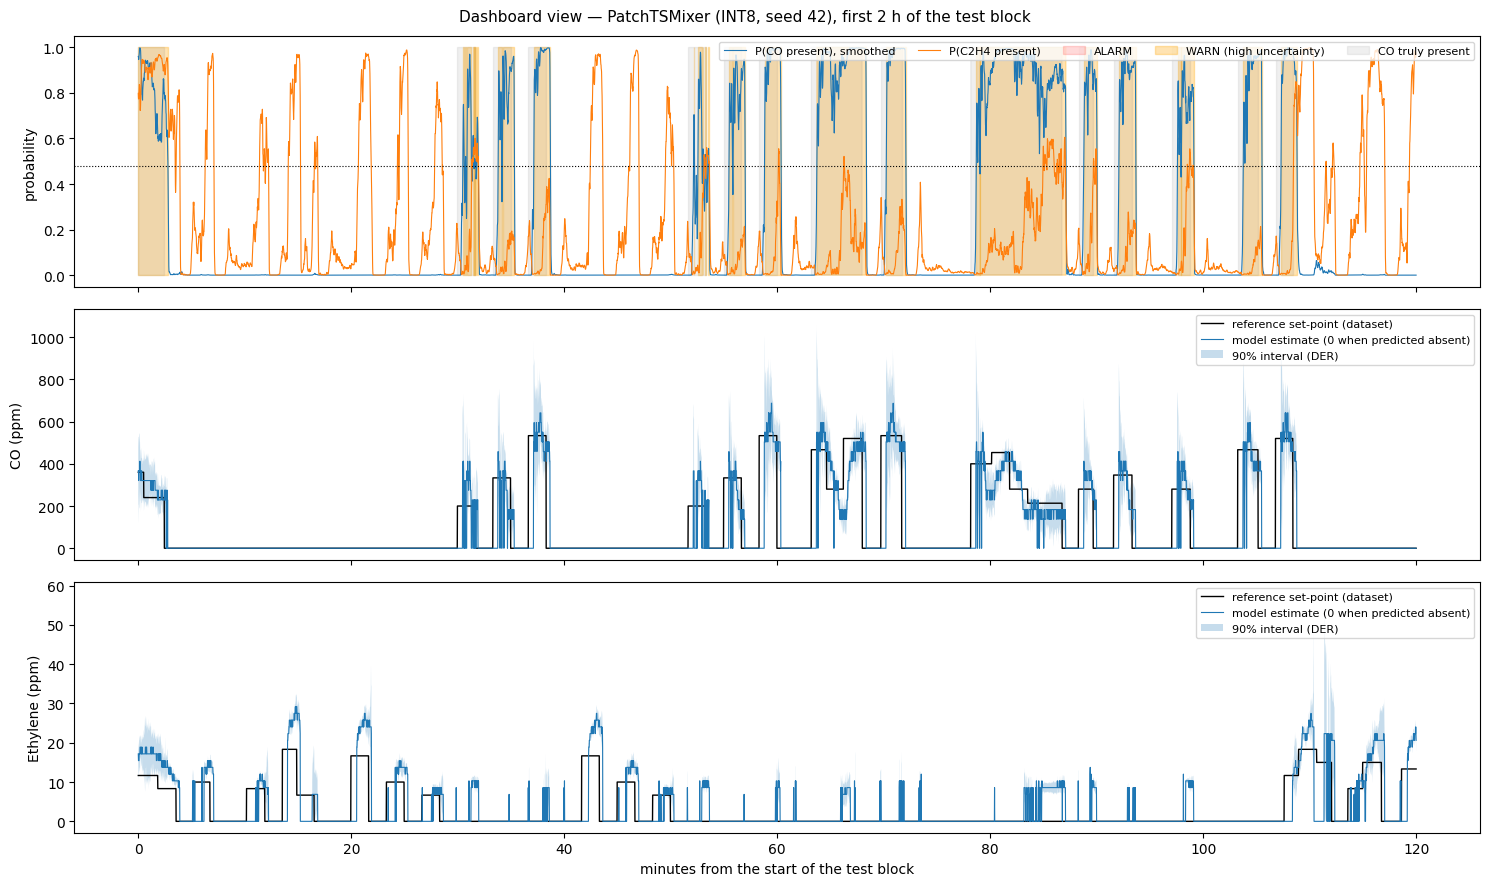

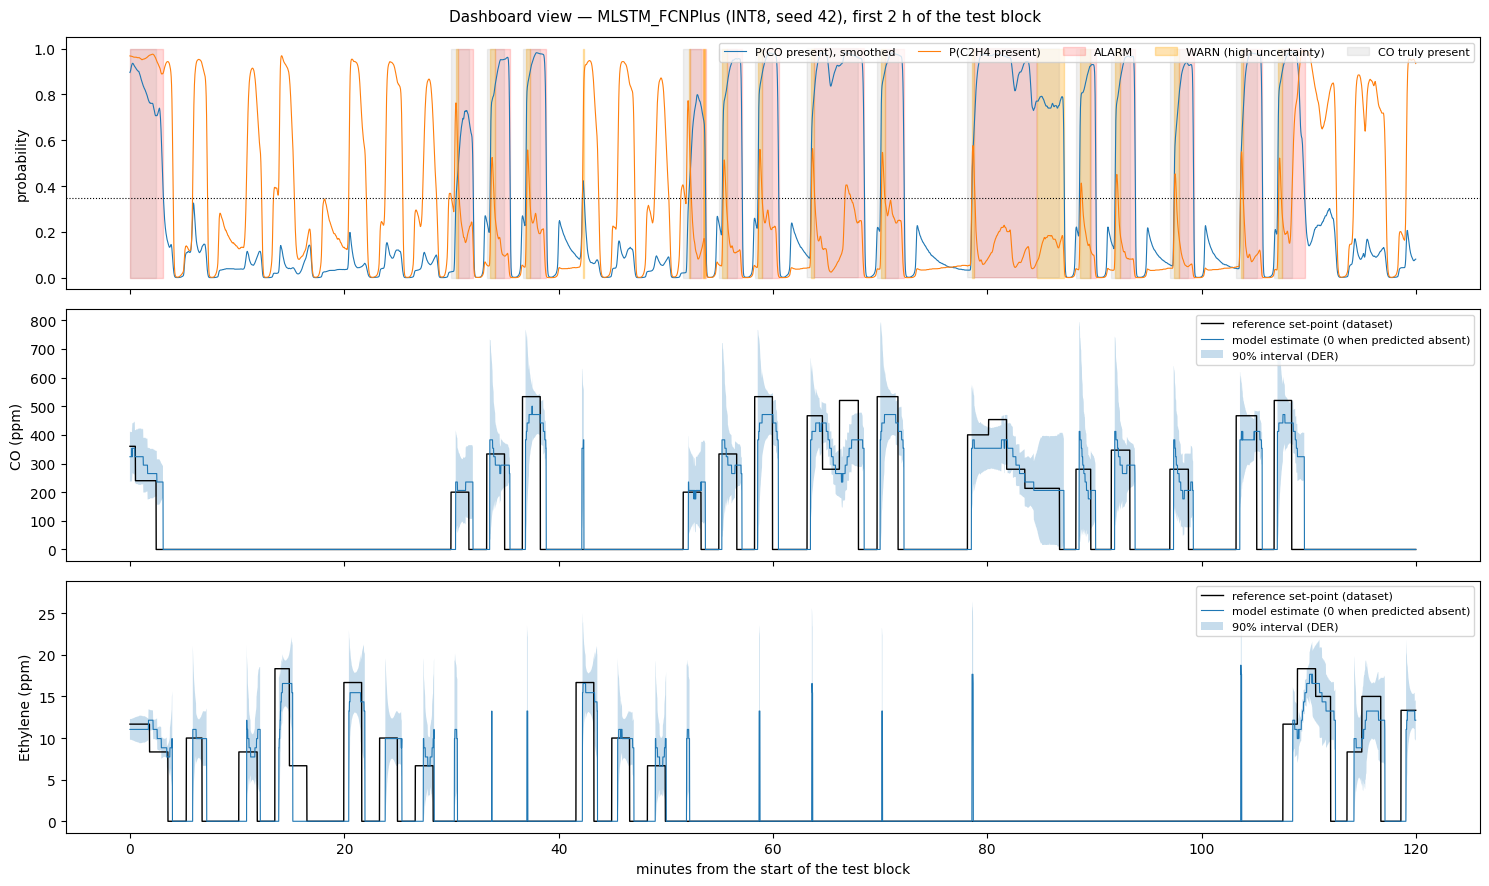

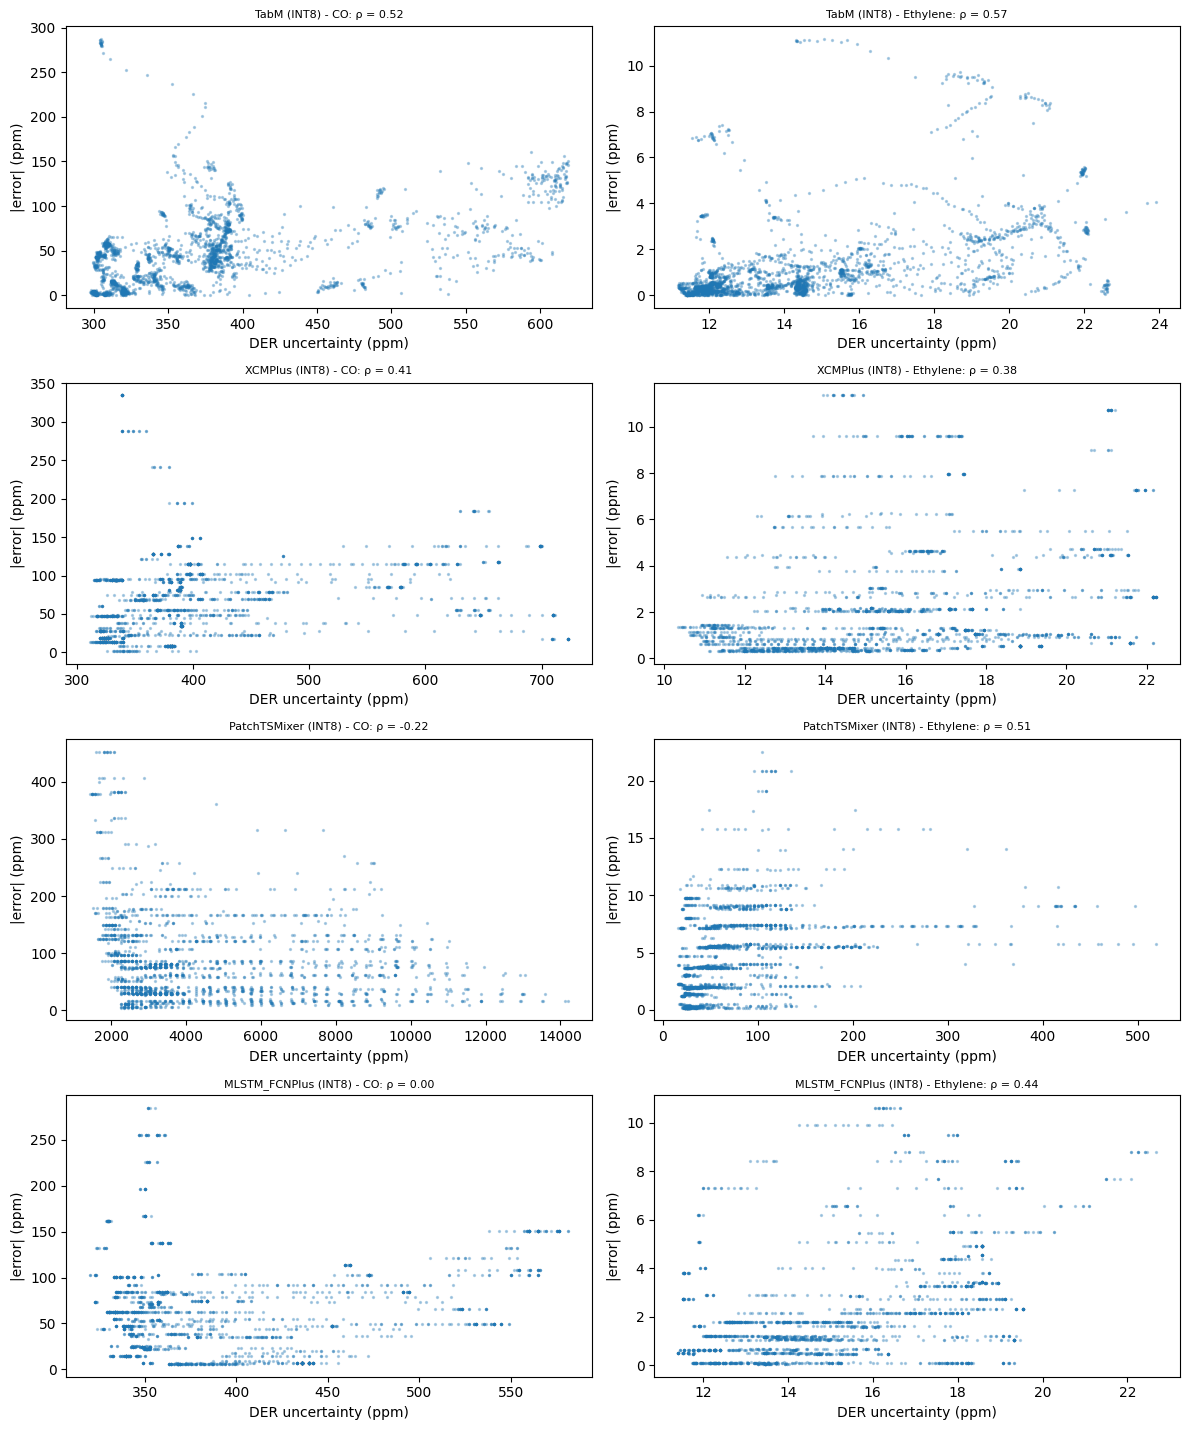

In [ ]:

# ==================== Top-N models: figures (run the Top-N table cell first) ====================

BAR_METRICS = [
    ("F1_macro_4class", "4-class macro F1"),
    ("CO_alarm_prec", "CO alarm precision"),
    ("false_alarms_per_h", "false CO alarms per hour"),
]

DASHBOARD_LEVEL = "int8_static"
DASHBOARD_MODELS = None
DASHBOARD_HOURS = 2

LEVEL_COLOR = {
    "fp32": "tab:blue",
    "fp16": "tab:green",
    "int8_static": "tab:red",
}
LEVEL_MARKER = {
    "fp32": "o",
    "fp16": "s",
    "int8_static": "v",
}

# Thứ tự hiển thị cố định, không sắp xếp theo giá trị metric
QUANT_ORDER = ["fp32", "fp16", "int8_static"]

# Các metric càng cao càng tốt hay càng thấp càng tốt
METRIC_DIRECTION = {
    "F1_macro_4class": "higher",
    "CO_alarm_prec": "higher",
    "false_alarms_per_h": "lower",
}


if "TOP_ROWS" not in globals() or not len(TOP_ROWS):
    print("Run the Top-N table cell first.")

else:
    T = TOP_ROWS.copy()
    tag = f"top{TOP_N}"

    # Giữ đúng thứ tự FP32 -> FP16 -> INT8,
    # chỉ hiển thị các level có trong dữ liệu
    lv_present = [lv for lv in QUANT_ORDER if lv in set(T.level)]
    lv_present += [
        lv for lv in LEVELS
        if lv in set(T.level) and lv not in lv_present
    ]

    # ============================================================
    # 1) Quality per model and level: grouped horizontal bars
    # Giữ nguyên 3 metric ban đầu
    # ============================================================
    fig, ax = plt.subplots(
        1, len(BAR_METRICS),
        figsize=(5.2 * len(BAR_METRICS), 0.9 + 0.75 * len(TOP_MODELS))
    )
    ax = np.atleast_1d(ax)
    h = 0.8 / max(len(lv_present), 1)

    for a, (col, lab) in zip(ax, BAR_METRICS):
        for k, lv in enumerate(lv_present):
            sub = T[T.level == lv].set_index("model")

            models_here = [m for m in TOP_MODELS if m in sub.index]
            y = [TOP_MODELS.index(m) + k * h for m in models_here]
            v = [
                sub.loc[m, col] if col in sub.columns else np.nan
                for m in models_here
            ]

            a.barh(
                y, v, height=h,
                color=LEVEL_COLOR.get(lv, "gray"),
                label=LEVEL_LABELS.get(lv, lv)
            )

        a.set_yticks(
            [
                i + h * (len(lv_present) - 1) / 2
                for i in range(len(TOP_MODELS))
            ],
            TOP_MODELS
        )
        a.invert_yaxis()
        a.set_xlabel(lab)

    ax[0].legend(fontsize=8, loc="lower right")
    ax[0].set_title(f"Top {TOP_N} by {SORT_BY}", fontsize=9)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figures" / f"{tag}_by_model.png", dpi=120)
    plt.show()

    # ============================================================
    # 1B) Quantization trend + percentage change at each point
    # FP32 -> FP16 -> INT8
    # ============================================================
    for col, lab in BAR_METRICS:
        fig, ax = plt.subplots(figsize=(9, 5.5))

        for i, m in enumerate(TOP_MODELS):
            g = T[T.model == m].copy()

            # Ép thứ tự level theo quá trình lượng tử hóa
            g["_order"] = g["level"].map(
                {lv: idx for idx, lv in enumerate(QUANT_ORDER)}
            )
            g = g.dropna(subset=["_order", col])
            g = g.sort_values("_order")

            # Chỉ lấy các level trong thứ tự được quy định
            g = g[g["level"].isin(QUANT_ORDER)]

            if g.empty:
                continue

            x = [QUANT_ORDER.index(lv) for lv in g["level"]]
            y = g[col].to_numpy(dtype=float)

            ax.plot(
                x, y, marker="o", linewidth=1.5,
                color=f"C{i}", label=m, alpha=0.85
            )

            for k, (_, r) in enumerate(g.iterrows()):
                value = float(r[col])
                lv = r["level"]

                # FP32 là baseline; các điểm sau so với level trước
                if k == 0:
                    annotation = "baseline" if lv == "fp32" else "n/a"
                else:
                    prev_value = float(g.iloc[k - 1][col])

                    if np.isclose(prev_value, 0.0):
                        annotation = "n/a"
                    else:
                        pct = (value - prev_value) / abs(prev_value) * 100
                        annotation = f"{pct:+.2f}%"

                # Màu và marker theo level
                ax.scatter(
                    x[k], value,
                    color=LEVEL_COLOR.get(lv, f"C{i}"),
                    marker=LEVEL_MARKER.get(lv, "o"),
                    s=75, zorder=3
                )

                ax.annotate(
                    f"{value:.3f}\n({annotation})"
                    if col != "false_alarms_per_h"
                    else f"{value:.3f}\n({annotation})",
                    (x[k], value),
                    xytext=(0, 9 if k % 2 == 0 else -23),
                    textcoords="offset points",
                    ha="center", fontsize=7
                )

        ax.set_xticks(
            range(len(QUANT_ORDER)),
            [LEVEL_LABELS.get(lv, lv) for lv in QUANT_ORDER]
        )
        ax.set_xlabel("Quantization level (FP32 → FP16 → INT8)")
        ax.set_ylabel(lab)

        direction_text = (
            "higher is better"
            if METRIC_DIRECTION[col] == "higher"
            else "lower is better"
        )
        ax.set_title(f"{lab} across quantization levels ({direction_text})")
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.legend(fontsize=8, loc="best")
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / "figures" / f"{tag}_{col}_quant_trend.png",
            dpi=150, bbox_inches="tight"
        )
        plt.show()

    # ============================================================
    # 2) Model size vs quality with ESP32 memory limits
    # ============================================================
    q = T.dropna(subset=["size_mb"])

    if len(q):
        fig, ax = plt.subplots(figsize=(10, 5.5))

        for i, m in enumerate(TOP_MODELS):
            g = q[q.model == m].copy()
            g["_order"] = g["level"].map(
                {lv: idx for idx, lv in enumerate(QUANT_ORDER)}
            )
            g = g.sort_values("_order")

            if not len(g):
                continue

            ax.plot(
                g.size_mb, g.F1_macro_4class, "-",
                color=f"C{i}", alpha=0.4
            )

            for _, r in g.iterrows():
                ax.scatter(
                    r.size_mb, r.F1_macro_4class,
                    color=f"C{i}",
                    marker=LEVEL_MARKER.get(r.level, "o"),
                    s=60,
                    label=m if r.level == "fp32" else None
                )
                ax.annotate(
                    LEVEL_LABELS.get(r.level, r.level),
                    (r.size_mb, r.F1_macro_4class),
                    fontsize=7, xytext=(4, 4),
                    textcoords="offset points"
                )

        for lim, mb in ESP32_LIMITS_MB.items():
            ax.axvline(mb, color="k", ls="--", lw=0.8)
            ax.text(
                mb, ax.get_ylim()[0], f" {lim}",
                rotation=90, va="bottom", fontsize=8
            )

        ax.set_xscale("log")
        ax.set_xlabel("model file size (MB, log)")
        ax.set_ylabel("4-class macro F1 (test)")
        ax.set_title("○ FP32  □ FP16  ▽ INT8", fontsize=9)
        ax.legend(fontsize=8, ncol=2)
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / "figures" / f"{tag}_size_vs_f1.png", dpi=120
        )
        plt.show()

    # ============================================================
    # Helper: test predictions + thresholds of one model at one level
    # ============================================================
    def top_pred(model, level):
        key = f"{model}_seed{SEED}"
        p = None

        if level != "fp32" and "QPREDS" in globals():
            p = QPREDS.get((key, level))

        if p is None:
            preds_source = (
                PREDS if len(PREDS)
                else globals().get("SRC_PREDS", {})
            )
            p, level = preds_source.get(key), "fp32"

        thresh_source = (
            THRESH if len(THRESH)
            else globals().get("SRC_THRESH", {})
        )
        th = thresh_source[key]

        return (
            p,
            np.array(th["tau"], float),
            np.array(th["uct_cut_ppm"], float),
            level
        )

    nets = [
        m for m in TOP_MODELS
        if RANK.loc[m, "family"].startswith("Network")
    ]

    if DASHBOARD_MODELS is not None:
        nets = [m for m in nets if m in DASHBOARD_MODELS]

    d = DATA["test"]
    span = slice(
        0,
        min(
            len(d["end_idx"]),
            int(DASHBOARD_HOURS * 3600 * RESAMPLE_HZ)
        )
    )
    t = (d["end_idx"][span] - d["end_idx"][0]) / RESAMPLE_HZ / 60

    # ============================================================
    # 3) Dashboard: probability, ALARM/WARN, ppm + 90% DER interval
    # ============================================================
    for m in nets:
        pr, tau, ucut, used = top_pred(m, DASHBOARD_LEVEL)

        if pr is None:
            continue

        ps = smooth_causal(pr["prob"], ALARM_SMOOTH_S)[span]
        alarm = ps[:, 0] >= tau[0]

        warn = (
            alarm & (pr["uct_ppm"][span, 0] > ucut[0])
            if "uct_ppm" in pr
            else np.zeros_like(alarm)
        )

        fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)

        ax[0].plot(
            t, ps[:, 0], lw=0.8,
            label="P(CO present), smoothed"
        )
        ax[0].plot(
            t, ps[:, 1], lw=0.8,
            label="P(C2H4 present)"
        )
        ax[0].axhline(tau[0], color="k", ls=":", lw=0.8)

        ax[0].fill_between(
            t, 0, 1, where=alarm & ~warn,
            color="red", alpha=0.15, step="mid", label="ALARM"
        )
        ax[0].fill_between(
            t, 0, 1, where=warn,
            color="orange", alpha=0.3, step="mid",
            label="WARN (high uncertainty)"
        )
        ax[0].fill_between(
            t, 0, 1, where=d["pres"][span, 0] > 0.5,
            color="gray", alpha=0.12, step="mid",
            label="CO truly present"
        )

        ax[0].legend(fontsize=8, ncol=5, loc="upper right")
        ax[0].set_ylabel("probability")

        for j, gname in enumerate(GAS_NAMES):
            hat = pr["prob"][span, j] >= tau[j]
            ppm = np.where(
                hat, np.clip(pr["ppm_cond"][span, j], 0, None), 0
            )

            ax[j + 1].plot(
                t, d["y_ppm"][span, j], "k", lw=1,
                label="reference set-point (dataset)"
            )
            ax[j + 1].plot(
                t, ppm, lw=0.8,
                label="model estimate (0 when predicted absent)"
            )

            if "scale_ppm" in pr:
                half = (
                    scipy.stats.t.ppf(T_Q, pr["df_t"][span, j])
                    * pr["scale_ppm"][span, j]
                )
                ax[j + 1].fill_between(
                    t,
                    np.where(hat, np.clip(ppm - half, 0, None), np.nan),
                    np.where(hat, ppm + half, np.nan),
                    alpha=0.25, label="90% interval (DER)"
                )

            ax[j + 1].set_ylabel(f"{gname} (ppm)")
            ax[j + 1].legend(fontsize=8, loc="upper right")

        ax[-1].set_xlabel("minutes from the start of the test block")
        fig.suptitle(
            f"Dashboard view — {m} "
            f"({LEVEL_LABELS.get(used, used)}, seed {SEED}), "
            f"first {DASHBOARD_HOURS} h of the test block",
            fontsize=11
        )

        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / "figures" / f"{tag}_dashboard_{m}_{used}.png",
            dpi=120
        )
        plt.show()

    # ============================================================
    # 4) DER uncertainty: |error| vs predicted uncertainty
    # ============================================================
    if nets:
        fig, ax = plt.subplots(
            len(nets), G,
            figsize=(12, 3.6 * len(nets)),
            squeeze=False
        )

        for i, m in enumerate(nets):
            pr, _, _, used = top_pred(m, DASHBOARD_LEVEL)

            for j, gname in enumerate(GAS_NAMES):
                a = ax[i, j]

                if pr is None or "uct_ppm" not in pr:
                    a.set_axis_off()
                    continue

                mk = d["pres"][:, j] > 0.5
                err = np.abs(
                    d["y_ppm"][mk, j] - pr["ppm_cond"][mk, j]
                )

                a.scatter(
                    pr["uct_ppm"][mk, j], err,
                    s=2, alpha=0.3
                )
                a.set_xlabel("DER uncertainty (ppm)")
                a.set_ylabel("|error| (ppm)")

                rho = (
                    scipy.stats.spearmanr(
                        pr["uct_ppm"][mk, j], err
                    ).statistic
                    if mk.sum() > 10 else np.nan
                )

                a.set_title(
                    f"{m} ({LEVEL_LABELS.get(used, used)}) - "
                    f"{gname}: ρ = {rho:.2f}",
                    fontsize=8
                )

        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / "figures" / f"{tag}_uncertainty_vs_error.png",
            dpi=120
        )
        plt.show()


## 12. Saved files


In [ ]:
cfg_keys = ["SPLIT", "INNER_VAL_FRAC", "REFIT_FULL_TRAIN", "GAP_S", "RESAMPLE_HZ", "DROP_FIRST_S", "WINDOW_S", "SIGNAL_TRANSFORM",
            "SENSOR_GROUPING", "PRESENT_PPM", "CO_DANGER_PPM", "THRESHOLD_MODE", "ALARM_SMOOTH_S", "UNCERTAINTY_Q",
            "STEADY_SKIP_S", "DL_MODELS", "BASELINES", "MODEL_CFG", "BASELINE_CFG", "N_SEEDS", "EPOCHS", "PATIENCE",
            "BATCH_SIZE", "BATCH_BY_MODEL", "TRAIN_STRIDE", "LR", "LR_BY_MODEL", "WEIGHT_DECAY", "EARLY_STOP_METRIC", "LAMBDA_DER", "DER_COEFF", "QUANT_LEVELS",
            "CALIB_SAMPLES", "INT4_BLOCK", "SEED", "QUICK_RUN"]
with open(OUTPUT_DIR / "config.json", "w") as f:
    json.dump({k: globals()[k] for k in cfg_keys}, f, indent=2, default=str)
# Everything the edge gateway needs to reproduce the model input
with open(OUTPUT_DIR / "preprocessing.json", "w") as f:
    json.dump({"gas_names": GAS_NAMES, "sensor_cols": SENSOR_COLS, "resample_hz": RESAMPLE_HZ, "window_s": WINDOW_S,
               "signal_transform": SIGNAL_TRANSFORM, "sensor_grouping": SENSOR_GROUPING,
               "x_mean": x_mean.tolist(), "x_std": x_std.tolist(), "y_max": Y_MAX.tolist(),
               "feature_names": FEAT_NAMES, "feature_mean": f_mu.tolist(), "feature_std": f_sd.tolist(),
               "output_layout": "(batch, 5, n_gas): presence logit, DER gamma, nu, alpha, beta (raw, before DERLayer)"}, f)
with open(OUTPUT_DIR / "thresholds.json", "w") as f:
    json.dump(THRESH, f, indent=2)
if "HISTORIES" in globals() and HISTORIES:
    with open(OUTPUT_DIR / "histories.json", "w") as f:
        json.dump(HISTORIES, f)
np.savez_compressed(OUTPUT_DIR / "test_predictions.npz", end_idx=DATA["test"]["end_idx"], y_ppm=DATA["test"]["y_ppm"],
                    **{f"{k}__{f}": v[f] for k, v in PREDS.items() for f in ("prob", "ppm_cond") if f in v})
pd.DataFrame(RESULTS).to_csv(OUTPUT_DIR / "results_all_seeds.csv", index=False)
print("Saved to", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUTPUT_DIR)}  ({p.stat().st_size / 1024:.0f} KB)")

Saved to /content/drive/MyDrive/AIoT/outputs/tinyml_benchmark_v8_new_1
  config.json  (2 KB)
  figures/dashboard_demo.png  (306 KB)
  figures/size_vs_f1.png  (52 KB)
  figures/test_by_model.png  (53 KB)
  figures/top4_by_model.png  (33 KB)
  figures/top4_dashboard_MLSTM_FCNPlus_int8_static.png  (310 KB)
  figures/top4_dashboard_PatchTSMixer_int8_static.png  (319 KB)
  figures/top4_dashboard_TabM_int8_static.png  (309 KB)
  figures/top4_dashboard_XCMPlus_int8_static.png  (297 KB)
  figures/top4_size_vs_f1.png  (58 KB)
  figures/top4_uncertainty_vs_error.png  (331 KB)
  figures/training_curves.png  (436 KB)
  figures/uncertainty_vs_error.png  (96 KB)
  histories.json  (12 KB)
  main_table_test.csv  (1 KB)
  models/CfC_seed42.pt  (177 KB)
  models/Crossformer_seed42.pt  (13763 KB)
  models/ExtraTrees_ZIR.joblib  (21173 KB)
  models/MLSTM_FCNPlus_seed42.pt  (5756 KB)
  models/PatchTSMixer_seed42.pt  (10637 KB)
  models/QUANT_Hurdle.joblib  (29197 KB)
  models/RealMLP_Hurdle.joblib  (4704 K